# Оценка залоговой недвижимости линейными моделями

Оценка рыночной стоимости жилья для залогового портфеля (AVM). Данные: California Housing, перепись США 1990 г., 20 640 кварталов; таргет — медианная стоимость дома в квартале. Основная метрика — MAPE, выбрана до моделирования.

### Итоги

* Ridge на 213 признаках: MAPE на тесте 17,7%. Наивный МНК — 27,8%, градиентный бустинг — 14,6%.
* Интерпретируемая лог-модель на 16 признаках: MAPE 22,1%, эластичность цены по доходу 0,64, INLAND дешевле `<1H OCEAN` на 27% при прочих равных.
* При гетероскедастичности классические SE дают покрытие 95%-ного ДИ около 80% (симуляция), HC3 — 95%. Кластерные SE по географическим ячейкам в 1,1–5,5 раза больше HC3.
* Нижнюю границу 90%-ного предсказательного интервала (консервативную стоимость залога) корректно калибрует только квантильная регрессия: тест Купика пройден в целом и по сегментам.
* Из 21 парного сравнения моделей значимы 20 (Холм). Ridge и МНК на одном пространстве признаков не различаются.

Разделы: 1 данные · 2 EDA · 3 признаки · 4 оценки МНК · 5 реализация · 6 базовая модель · 7 интерпретируемая модель · 8 регуляризация · 9 GD/SGD · 10 интервалы · 11 сравнение моделей · 12 ограничения

## 0. Окружение

Python ≥ 3.9, pandas ≥ 1.5, scikit-learn ≥ 1.2, matplotlib ≥ 3.5. Данные скачиваются при первом запуске, полный прогон занимает около 2 минут. МНК-вывод реализован на numpy/scipy (раздел 5), statsmodels не нужен.

In [1]:
%config InlineBackend.figure_format = 'retina'

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from scipy.linalg import solve_triangular

import sklearn
from sklearn.base import BaseEstimator, OneToOneFeatureMixin, RegressorMixin, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import (
    ElasticNet, Lasso, LassoCV, LinearRegression, QuantileRegressor, Ridge, enet_path,
)
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, SplineTransformer, StandardScaler
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 40)

print("Версии:", {m.__name__: m.__version__ for m in [np, pd, scipy, sklearn, mpl, sns]})

Версии: {'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


In [2]:
# Категориальная палитра: цвет закреплён за моделью или методом
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
PALETTE = list(C.values())
INK, INK2, MUTED, GRID, BASELINE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
NEUTRAL = "#b9b8b0"  # «приглушённый» цвет для второстепенных элементов

# Последовательная (синяя) и расходящаяся (синий ↔ серый ↔ красный) шкалы
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
CMAP_DIV = mpl.colors.LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#3987e5", "#9ec5f4", "#f0efec", "#f3a3a2", "#e34948", "#a8292a"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10,
    "axes.edgecolor": BASELINE, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 10, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "xtick.color": BASELINE, "ytick.color": BASELINE,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "legend.title_fontsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 6, "patch.linewidth": 0,
    "figure.titlesize": 13, "figure.titleweight": "bold",
})


def suptitle(fig, title, subtitle=None):
    """Заголовок фигуры слева сверху и (опционально) пояснение под ним.
    Отступы задаются в дюймах, поэтому не зависят от высоты фигуры."""
    h = fig.get_figheight()
    base = 1.0 + 0.10 / h
    if subtitle:
        fig.text(0.01, base, subtitle, ha="left", va="bottom", color=INK2, fontsize=9.5)
        base += 0.27 / h
    fig.suptitle(title, x=0.01, y=base, ha="left", va="bottom", color=INK)


def thousands(x, pos=None):
    """Форматтер оси: значения в тысячах долларов."""
    return f"{x / 1e3:,.0f}k"

Метрики: MAPE (основная); MdAPE; PE10/PE20 — доля оценок с ошибкой не более 10%/20%; OVR20 — доля переоценок более чем на 20% (для залога переоценка опаснее недооценки); RMSE, MAE, $R^2$ в долларах.

In [3]:
def regression_report(y_true, y_pred):
    """Набор метрик качества оценки стоимости (в исходной шкале, доллары)."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_pred - y_true
    ape = np.abs(err) / y_true
    return {
        "MAPE, %": 100 * ape.mean(),
        "MdAPE, %": 100 * np.median(ape),
        "PE10, %": 100 * np.mean(ape <= 0.10),
        "PE20, %": 100 * np.mean(ape <= 0.20),
        "OVR20, %": 100 * np.mean(err / y_true > 0.20),
        "RMSE, $": np.sqrt(np.mean(err ** 2)),
        "MAE, $": np.mean(np.abs(err)),
        "R2": 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2),
    }


def report_table(preds, y_true):
    """Таблица метрик для словаря {имя модели: предсказания}."""
    return pd.DataFrame({name: regression_report(y_true, p) for name, p in preds.items()}).T

## 1. Данные

Версия из книги Géron, *Hands-On ML*: в отличие от `fetch_california_housing`, содержит суммарные признаки квартала, `ocean_proximity` и пропуски. При отсутствии локальной копии архив скачивается с GitHub.

In [4]:
DATA_DIR = Path("data")
CSV_PATH = DATA_DIR / "housing.csv"
DATA_URL = "https://github.com/ageron/data/raw/main/housing.tgz"


def load_housing(csv_path: Path = CSV_PATH, url: str = DATA_URL) -> pd.DataFrame:
    """Читает датасет; если локальной копии нет — скачивает архив и извлекает CSV."""
    if not csv_path.exists():
        import tarfile
        import urllib.request
        csv_path.parent.mkdir(parents=True, exist_ok=True)
        archive = csv_path.parent / "housing.tgz"
        urllib.request.urlretrieve(url, archive)
        with tarfile.open(archive) as tar:
            csv_path.write_bytes(tar.extractfile("housing/housing.csv").read())
    return pd.read_csv(csv_path)


raw = load_housing()
print(f"Объектов: {raw.shape[0]:,}, столбцов: {raw.shape[1]}")
raw.head()

Объектов: 20,640, столбцов: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


| Признак | Описание |
|---|---|
| `longitude`, `latitude` | координаты квартала |
| `housing_median_age` | медианный возраст домов; значения ≥ 52 записаны как 52 |
| `total_rooms`, `total_bedrooms` | комнаты и спальни в квартале; в `total_bedrooms` есть пропуски |
| `population`, `households` | население и число домохозяйств |
| `median_income` | медианный доход, десятки тыс. долл.; значения ≥ 15 записаны как 15,0001 |
| `ocean_proximity` | близость к океану, 5 категорий |
| `median_house_value` | таргет, долл.; значения ≥ 500 000 записаны как 500 001 |

In [5]:
print("Пропуски:", raw.isna().sum()[lambda s: s > 0].to_dict())
raw.describe().T

Пропуски: {'total_bedrooms': 207}


,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"


Пропуски только в `total_bedrooms` (207, 1%). Масштабы признаков различаются на порядки, у суммарных признаков тяжёлый правый хвост: максимум в 3–6 раз выше 99-го перцентиля.

## 2. EDA

### 2.1. Таргет и цензурирование

,объектов,"доля, %"
таргет = 500 001 (цензура сверху),965,4.6754
таргет = 14 999 (цензура снизу),4,0.0194
возраст = 52 (обрезка сверху),1273,6.1676
доход ≥ 15 (обрезка сверху),51,0.2471


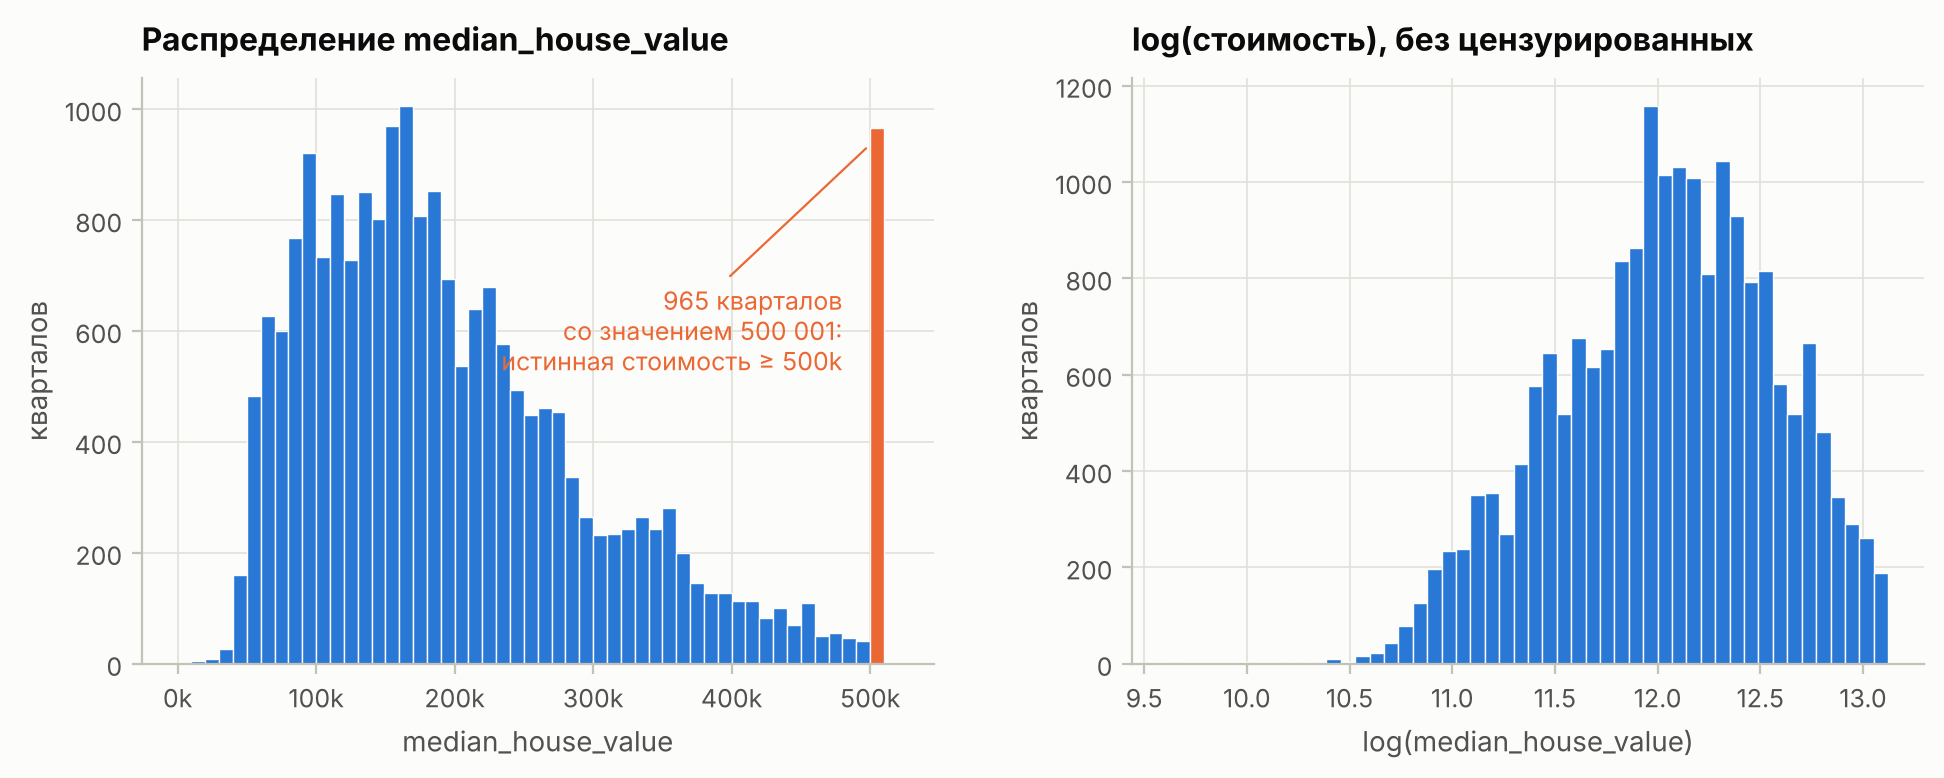

Асимметрия: исходная шкала 0.81, лог-шкала -0.29


In [6]:
y_all = raw["median_house_value"]
is_censored = y_all >= 500_001

censoring = pd.DataFrame({
    "объектов": [is_censored.sum(), (y_all <= 14_999).sum(),
                 (raw.housing_median_age >= 52).sum(), (raw.median_income >= 15).sum()],
}, index=["таргет = 500 001 (цензура сверху)", "таргет = 14 999 (цензура снизу)",
          "возраст = 52 (обрезка сверху)", "доход ≥ 15 (обрезка сверху)"])
censoring["доля, %"] = 100 * censoring["объектов"] / len(raw)
display(censoring)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"wspace": 0.25})
bins = np.arange(0, 520_001, 10_000)
ax = axes[0]
ax.hist(y_all[~is_censored], bins=bins, color=C["blue"], edgecolor=SURFACE, linewidth=0.5)
ax.hist(y_all[is_censored], bins=bins, color=C["orange"], edgecolor=SURFACE, linewidth=0.5)
ax.annotate(f"{is_censored.sum()} кварталов\nсо значением 500 001:\nистинная стоимость ≥ 500k",
            xy=(500_000, is_censored.sum() * 0.97), xytext=(480_000, 600), ha="right", va="center",
            color=C["orange"], fontsize=9, arrowprops=dict(arrowstyle="-", color=C["orange"], lw=0.8))
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.set(title="Распределение median_house_value", xlabel="median_house_value", ylabel="кварталов")

ax = axes[1]
log_y = np.log(y_all[~is_censored])
ax.hist(log_y, bins=50, color=C["blue"], edgecolor=SURFACE, linewidth=0.5)
ax.set(title="log(стоимость), без цензурированных", xlabel="log(median_house_value)", ylabel="кварталов")
plt.show()

print(f"Асимметрия: исходная шкала {stats.skew(y_all[~is_censored]):.2f}, "
      f"лог-шкала {stats.skew(log_y):.2f}")

Исключаем 965 цензурированных кварталов (4,7%): для них известна только нижняя граница стоимости, и МНК на таких наблюдениях даёт смещённые оценки. Область применимости модели — объекты до 500 тыс. долл.; дорогие залоги оцениваются индивидуально, для полного диапазона нужна тобит-регрессия. Обрезанные признаки оставляем, для возраста добавляем флаг `age_capped`. Преобразование таргета выбирается по остаткам регрессии (7.1).

### 2.2. География

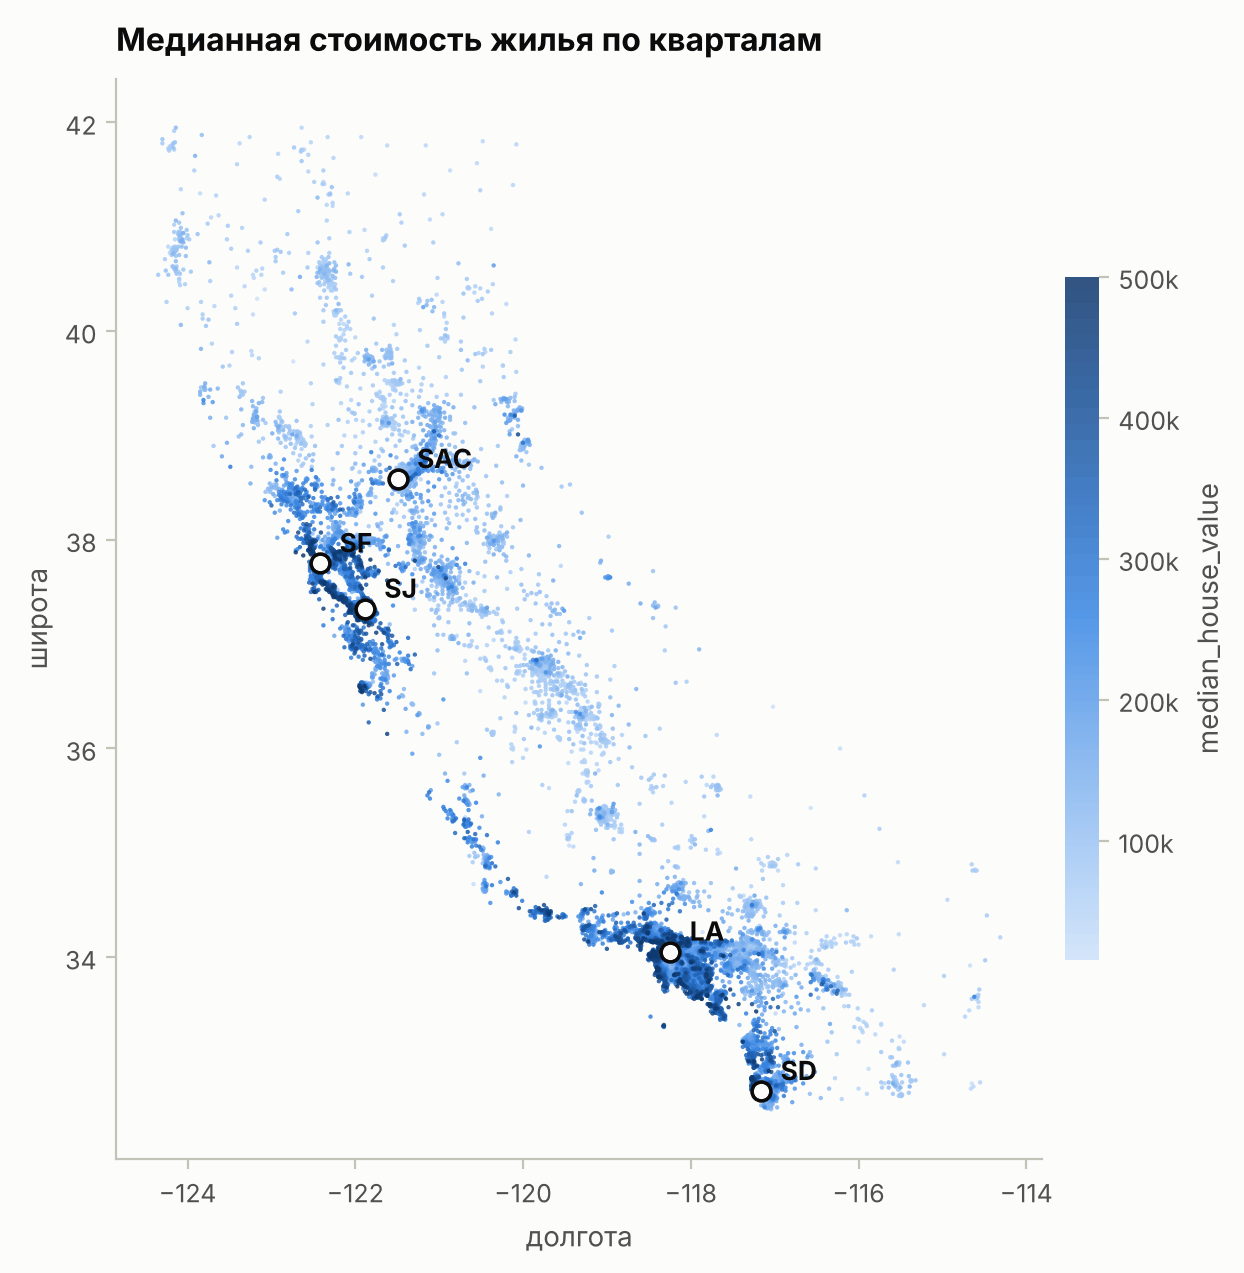

In [7]:
METRO_CENTERS = {  # (широта, долгота) центров крупнейших агломераций Калифорнии
    "SF": (37.7749, -122.4194),   # Сан-Франциско
    "SJ": (37.3382, -121.8863),   # Сан-Хосе (Кремниевая долина)
    "SAC": (38.5816, -121.4944),  # Сакраменто
    "LA": (34.0522, -118.2437),   # Лос-Анджелес
    "SD": (32.7157, -117.1611),   # Сан-Диего
}

data = raw.loc[~is_censored].reset_index(drop=True)  # область применимости модели

fig, ax = plt.subplots(figsize=(7.2, 7.4))
order = np.argsort(data["median_house_value"].values)  # дорогие точки рисуем поверх
sc = ax.scatter(data.longitude.values[order], data.latitude.values[order],
                c=data.median_house_value.values[order], cmap=CMAP_SEQ, s=2.5, alpha=0.85, linewidths=0)
for name, (lat, lon) in METRO_CENTERS.items():
    ax.scatter(lon, lat, s=46, facecolor=SURFACE, edgecolor=INK, linewidths=1.3, zorder=3)
    ax.annotate(name, (lon, lat), xytext=(7, 4), textcoords="offset points", fontsize=9.5,
                fontweight="bold", color=INK, zorder=4)
ax.set_aspect(1 / np.cos(np.radians(36.5)))  # равные расстояния по осям на широте Калифорнии
ax.set(title="Медианная стоимость жилья по кварталам", xlabel="долгота", ylabel="широта")
ax.grid(False)
cb = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02, format=mpl.ticker.FuncFormatter(thousands))
cb.outline.set_visible(False)
cb.set_label("median_house_value", color=INK2)
plt.show()

Цена нелинейно зависит от локации: максимумы на побережье у SF/SJ, LA и SD. Географию кодируем двумя способами: лог-расстояния до пяти агломераций для интерпретируемой модели (раздел 7) и RBF-признаки вокруг центров KMeans для гибкой (раздел 8).

### 2.3. Доход и ранговые корреляции

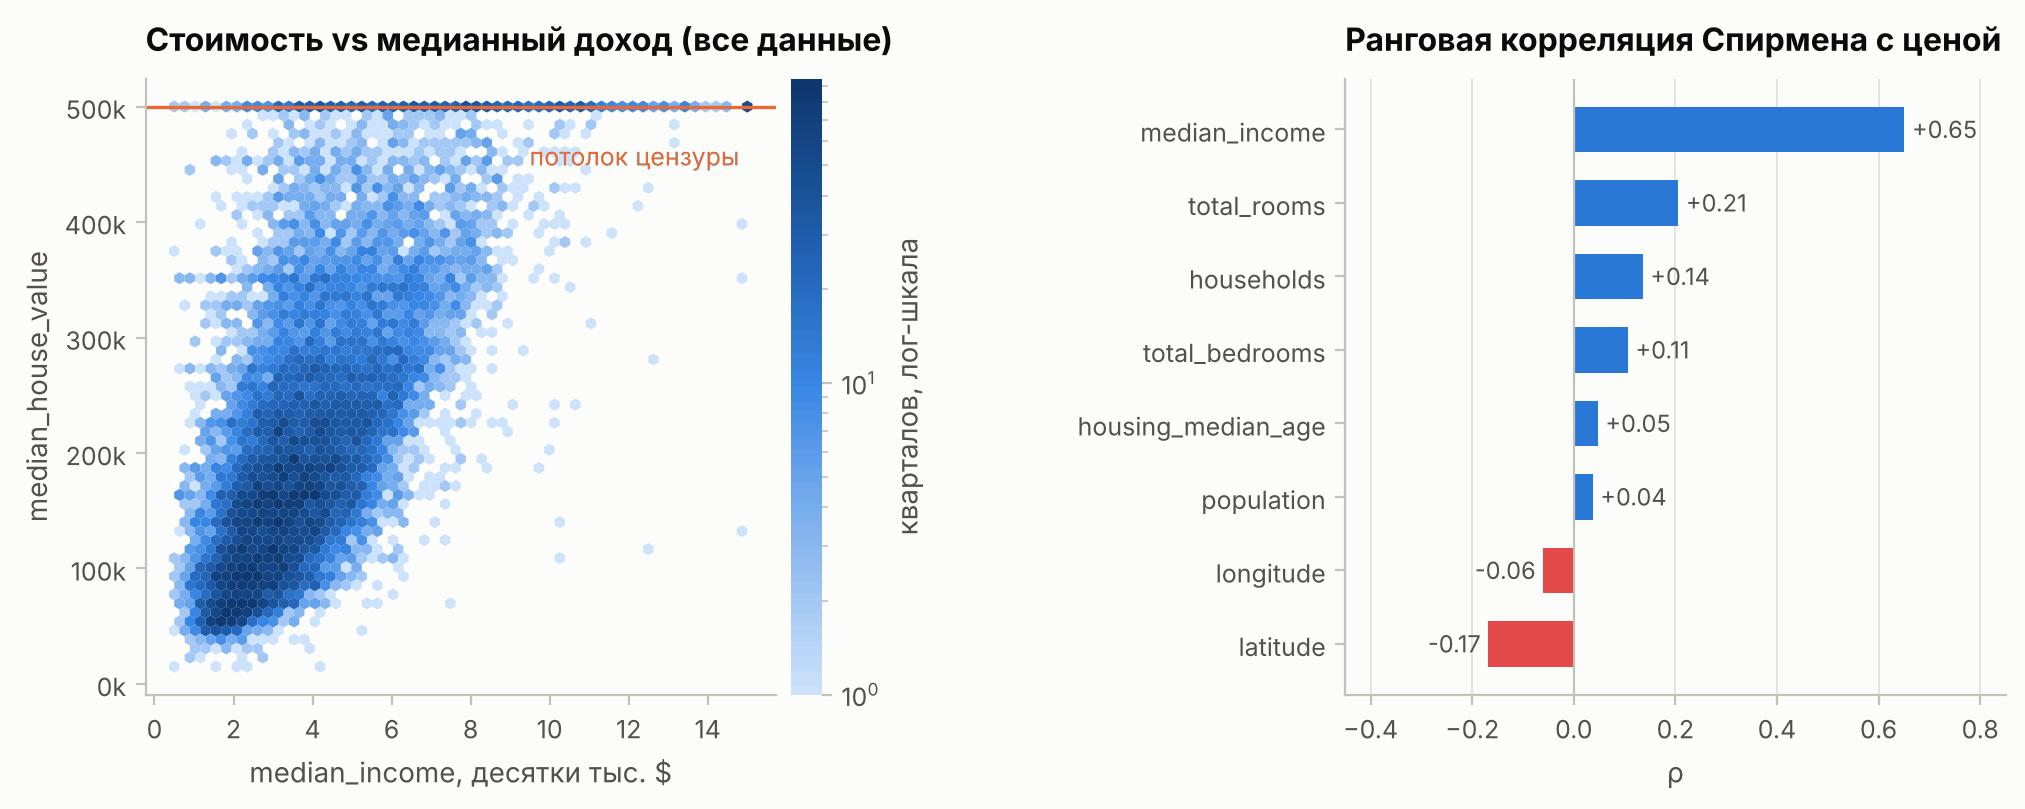

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.62})
ax = axes[0]
hb = ax.hexbin(raw.median_income, raw.median_house_value, gridsize=55, cmap=CMAP_SEQ, bins="log", mincnt=1, linewidths=0)
ax.axhline(500_001, color=C["orange"], lw=1.2)
ax.text(14.8, 470_000, "потолок цензуры", color=C["orange"], ha="right", va="top", fontsize=9)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.set(title="Стоимость vs медианный доход (все данные)", xlabel="median_income, десятки тыс. $", ylabel="median_house_value")
ax.grid(False)
cb = fig.colorbar(hb, ax=ax, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("кварталов, лог-шкала", color=INK2)

ax = axes[1]
num_cols = ["median_income", "housing_median_age", "total_rooms", "total_bedrooms",
            "population", "households", "latitude", "longitude"]
rho = data[num_cols].corrwith(data["median_house_value"], method="spearman").sort_values()
colors = [C["red"] if v < 0 else C["blue"] for v in rho.values]
ax.barh(rho.index, rho.values, color=colors, height=0.62)
for i, v in enumerate(rho.values):
    ax.text(v + (0.015 if v >= 0 else -0.015), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax.axvline(0, color=BASELINE, lw=0.8)
ax.set_xlim(-0.45, 0.85)
ax.set(title="Ранговая корреляция Спирмена с ценой", xlabel="ρ")
ax.grid(axis="y", visible=False)
plt.show()

Доход — сильнейший предиктор (ρ = 0,65), разброс цены растёт с доходом. Суммарные признаки квартала описывают его размер и с ценой почти не связаны, поэтому дальше используются удельные версии.

### 2.4. Пропуски в `total_bedrooms`

Проверка MCAR: KS-тест по числовым признакам между объектами с пропуском и без, χ² по `ocean_proximity`.

In [9]:
miss = data["total_bedrooms"].isna()
cols = ["median_house_value", "median_income", "housing_median_age", "total_rooms",
        "population", "households", "latitude", "longitude"]
ks_p = pd.Series({col: stats.ks_2samp(data.loc[miss, col], data.loc[~miss, col]).pvalue for col in cols})
ct = pd.crosstab(miss, data["ocean_proximity"])
_, p_chi2, *_ = stats.chi2_contingency(ct.loc[:, ct.sum() >= 5])
print(f"Пропусков: {miss.sum()} ({100 * miss.mean():.1f}%)")
print(f"KS: минимальный p = {ks_p.min():.3f} ({ks_p.idxmin()}), с поправкой Бонферрони {min(1, ks_p.min() * len(ks_p)):.2f}")
print(f"χ² по ocean_proximity: p = {p_chi2:.2f}")

Пропусков: 200 (1.0%)
KS: минимальный p = 0.069 (total_rooms), с поправкой Бонферрони 0.55
χ² по ocean_proximity: p = 0.41


Свидетельств против MCAR нет. Заполняем медианой и добавляем индикатор пропуска; его значимость проверяется в 7.6.

### 2.5. Мультиколлинеарность

$\mathrm{VIF}_j=1/(1-R_j^2)=[\mathrm{Corr}(X)^{-1}]_{jj}$. Объёмные признаки (`total_rooms`, `total_bedrooms`, `population`, `households`) заменяем удельными и логарифмами.

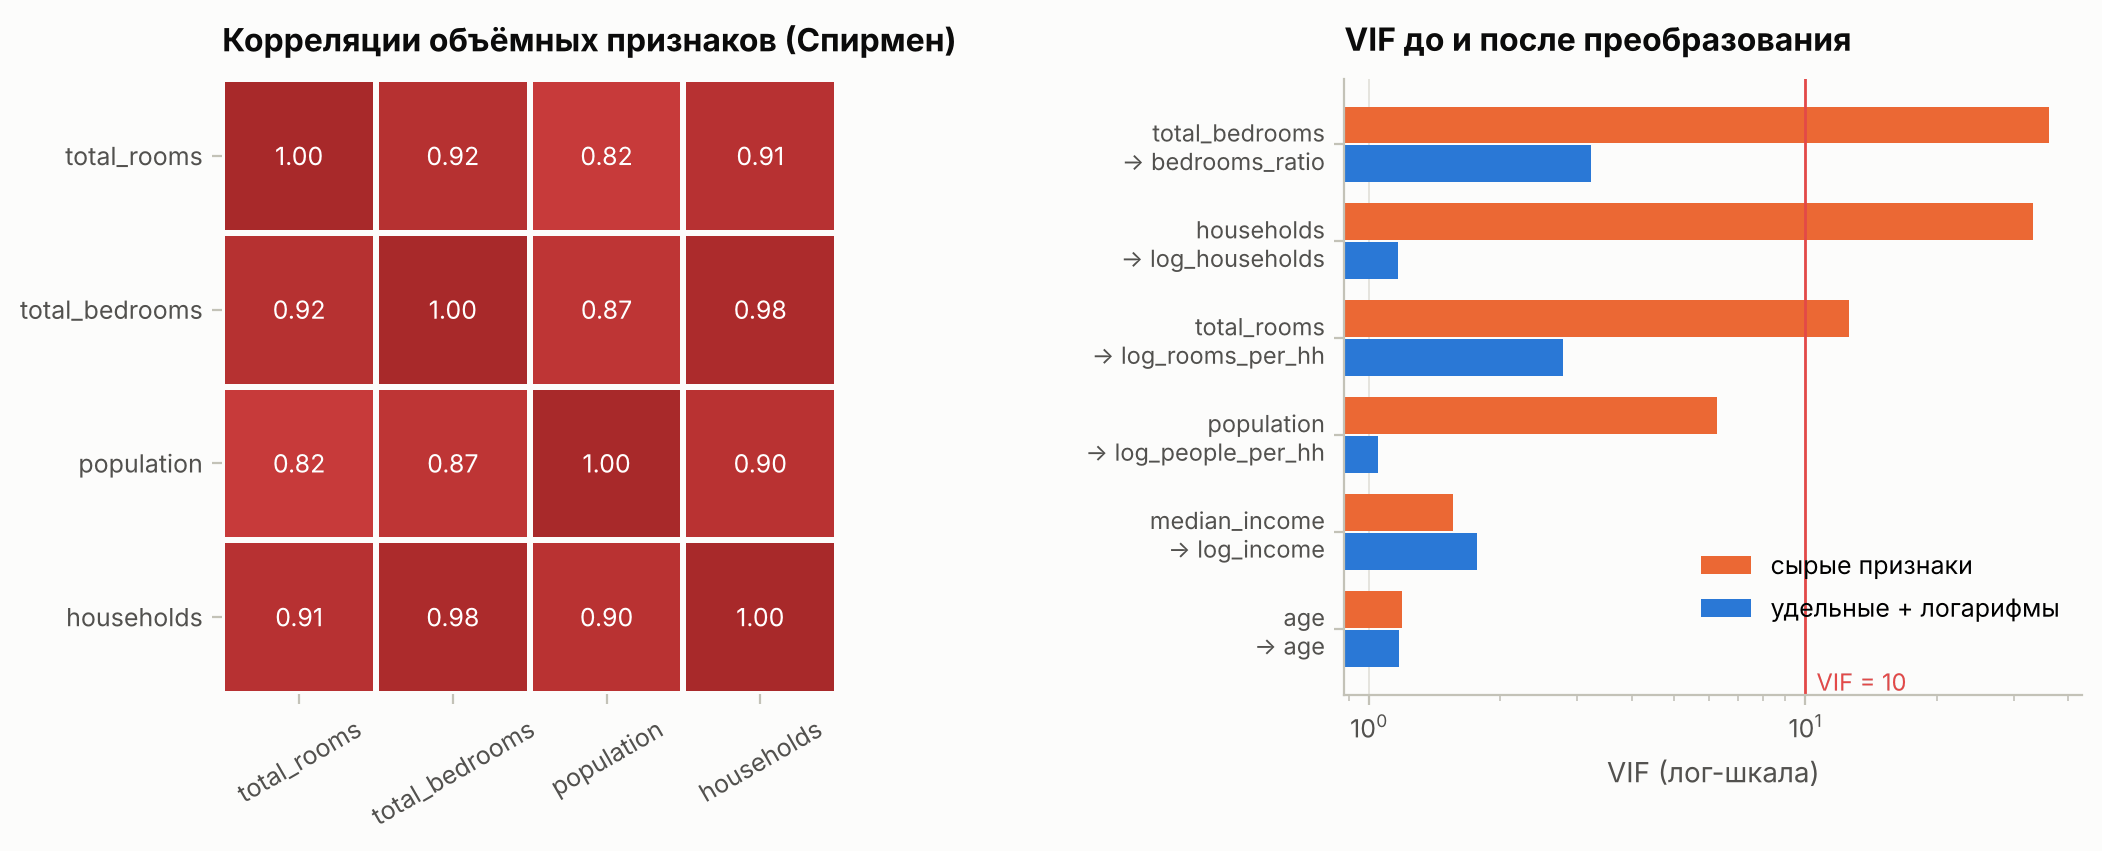

In [10]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Расстояние по дуге большого круга между точками (градусы) в километрах."""
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = phi2 - phi1, np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlmb / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Детерминированные построчные преобразования (не используют статистики выборки,
    поэтому их можно применять до разбиения — утечки нет)."""
    out = df.copy()
    out["ocean_proximity"] = out["ocean_proximity"].replace({"ISLAND": "NEAR OCEAN"})  # см. 2.7
    out["rooms_per_household"] = out["total_rooms"] / out["households"]
    out["people_per_household"] = out["population"] / out["households"]
    out["bedrooms_ratio"] = out["total_bedrooms"] / out["total_rooms"]  # NaN там, где пропуск
    out["log_income"] = np.log(out["median_income"])
    out["log_rooms_per_hh"] = np.log(out["rooms_per_household"])
    out["log_people_per_hh"] = np.log(out["people_per_household"])
    out["log_households"] = np.log(out["households"])
    out["age_capped"] = (out["housing_median_age"] >= 52).astype(float)
    for name, (lat, lon) in METRO_CENTERS.items():
        out[f"log_dist_{name}"] = np.log1p(haversine_km(out["latitude"], out["longitude"], lat, lon))
    return out


def vif(frame: pd.DataFrame) -> pd.Series:
    """VIF как диагональ обратной корреляционной матрицы."""
    corr = np.corrcoef(frame.dropna().to_numpy(), rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(corr)), index=frame.columns)


data = add_features(data)
vif_raw = vif(data[["total_rooms", "total_bedrooms", "population", "households",
                    "median_income", "housing_median_age"]])
vif_new = vif(data[["log_rooms_per_hh", "bedrooms_ratio", "log_people_per_hh", "log_households",
                    "log_income", "housing_median_age"]])

labels = [f"{a} → {b}" for a, b in zip(
    ["total_rooms", "total_bedrooms", "population", "households", "median_income", "age"],
    ["log_rooms_per_hh", "bedrooms_ratio", "log_people_per_hh", "log_households", "log_income", "age"])]
vif_table = pd.DataFrame({"VIF: сырые": vif_raw.values, "VIF: новые": vif_new.values}, index=labels)
vif_table = vif_table.sort_values("VIF: сырые")  # самые проблемные — наверху графика

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw={"width_ratios": [1, 1.2], "wspace": 0.75})
ax = axes[0]
vol = ["total_rooms", "total_bedrooms", "population", "households"]
corr = data[vol].corr(method="spearman")
sns.heatmap(corr, ax=ax, cmap=CMAP_DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", cbar=False,
            linewidths=2, linecolor=SURFACE, annot_kws={"fontsize": 9}, square=True)
ax.set_title("Корреляции объёмных признаков (Спирмен)")
ax.tick_params(axis="x", rotation=30)

ax = axes[1]
ypos = np.arange(len(vif_table))
ax.barh(ypos + 0.2, vif_table["VIF: сырые"], height=0.38, color=C["orange"], label="сырые признаки")
ax.barh(ypos - 0.2, vif_table["VIF: новые"], height=0.38, color=C["blue"], label="удельные + логарифмы")
ax.set_yticks(ypos, [s.replace(" → ", "\n→ ") for s in vif_table.index], fontsize=8.5)
ax.axvline(10, color=C["red"], lw=1)
ax.text(10.6, -0.55, "VIF = 10", color=C["red"], fontsize=8.5, va="center")
ax.set_xscale("log")
ax.set(title="VIF до и после преобразования", xlabel="VIF (лог-шкала)")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.08))
ax.grid(axis="y", visible=False)
plt.show()

Максимальный VIF снижается с 36 до 3,2. Размер квартала остаётся в одном признаке `log_households`.

### 2.6. Выбросы в удельных признаках

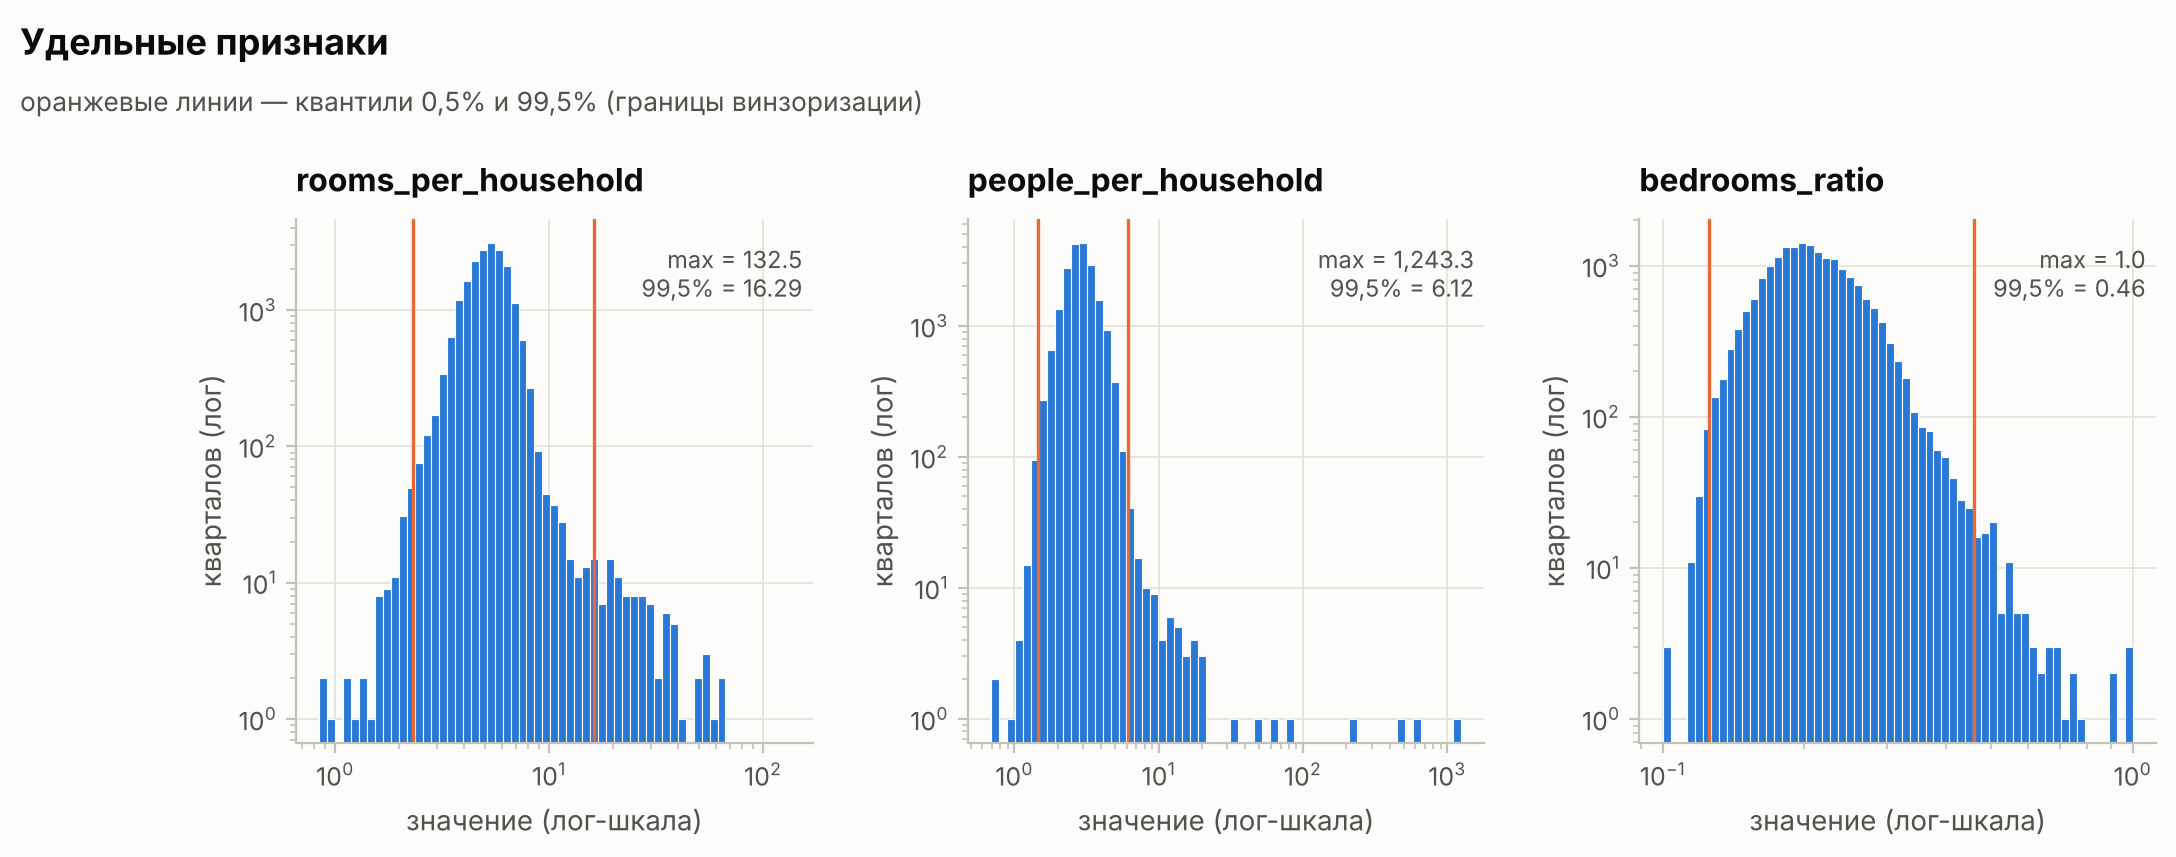

,households,population,total_rooms,people_per_household,rooms_per_household,median_income,median_house_value,ocean_proximity
4199,6.0000,"7,460.0000",19.0000,"1,243.3333",3.1667,10.2264,"137,500.0000",INLAND
13193,7.0000,"4,198.0000",36.0000,599.7143,5.1429,5.5179,"67,500.0000",INLAND
3806,13.0000,"6,532.0000",118.0000,502.4615,9.0769,4.2639,"350,000.0000",NEAR OCEAN


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"wspace": 0.3})
for ax, col in zip(axes, ["rooms_per_household", "people_per_household", "bedrooms_ratio"]):
    v = data[col].dropna()
    lo, hi = v.quantile([0.005, 0.995])
    log_bins = np.logspace(np.log10(v.min()), np.log10(v.max()), 60)
    ax.hist(v, bins=log_bins, color=C["blue"], edgecolor=SURFACE, linewidth=0.4)
    for q in (lo, hi):
        ax.axvline(q, color=C["orange"], lw=1.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(title=col, xlabel="значение (лог-шкала)", ylabel="кварталов (лог)")
    ax.text(0.98, 0.95, f"max = {v.max():,.1f}\n99,5% = {hi:,.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8.5, color=INK2)
suptitle(fig, "Удельные признаки", "оранжевые линии — квантили 0,5% и 99,5% (границы винзоризации)")
plt.show()

cols_show = ["households", "population", "total_rooms", "people_per_household",
             "rooms_per_household", "median_income", "median_house_value", "ocean_proximity"]
data.nlargest(3, "people_per_household")[cols_show]

Хвосты дают единичные кварталы с нежилой структурой: 6 домохозяйств на 7 460 жителей. Удалять их нельзя, модель должна оценивать любой объект портфеля, поэтому признаки логарифмируются и винзоризуются по квантилям 0,5% и 99,5% обучающей выборки (эффект — в абляции 8.6). Категория `ISLAND` (5 кварталов) объединена с `NEAR OCEAN`.

### 2.7. Решения по данным

| Проблема | Решение |
|---|---|
| цензура таргета, 4,7% | исключение; применимость до 500 тыс. долл. |
| возраст обрезан на 52 | флаг `age_capped` |
| пропуски `total_bedrooms`, 1% | медиана + индикатор |
| VIF объёмных признаков до 36 | удельные признаки, логарифмы |
| экстремальные удельные признаки | логарифм + винзоризация 0,5%/99,5% |
| нелинейная география | лог-расстояния до центров; RBF |
| `ISLAND`, 5 объектов | объединение с `NEAR OCEAN` |

## 3. Разбиение и признаки

Тест (20%) используется только в разделах 10–11. Спецификация и гиперпараметры выбираются по 5-fold CV на обучающей выборке. Статистики препроцессинга (медианы, квантили, параметры стандартизации, центры KMeans) обучаются внутри пайплайна.

In [12]:
TARGET = "median_house_value"

train_df, test_df = train_test_split(data, test_size=0.2, random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
y_train, y_test = train_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()
ly_train, ly_test = np.log(y_train), np.log(y_test)

pd.DataFrame({
    "объектов": [len(train_df), len(test_df)],
    "средняя цена, $": [y_train.mean(), y_test.mean()],
    "медиана, $": [np.median(y_train), np.median(y_test)],
    "доля INLAND, %": [100 * (train_df.ocean_proximity == "INLAND").mean(), 100 * (test_df.ocean_proximity == "INLAND").mean()],
    "пропусков bedrooms": [train_df.bedrooms_ratio.isna().sum(), test_df.bedrooms_ratio.isna().sum()],
}, index=["train", "test"])

,объектов,"средняя цена, $","медиана, $","доля INLAND, %",пропусков bedrooms
train,15740,"192,448.9260","173,850.0000",33.0686,153
test,3935,"192,593.9009","173,600.0000",33.5197,47


`Winsorizer` обрезает признаки по квантилям обучающей выборки и не трогает бинарные. `GeoRBF` строит признаки $\exp(-\gamma\lVert x-c_k\rVert^2)$ для центров KMeans по координатам.

In [13]:
class Winsorizer(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Обрезка значений по квантилям [q, 1 - q], оценённым на обучающей выборке."""

    def __init__(self, q=0.005):
        self.q = q

    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.n_features_in_ = X_arr.shape[1]
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        lo = np.nanquantile(X_arr, self.q, axis=0)
        hi = np.nanquantile(X_arr, 1 - self.q, axis=0)
        is_binary = np.array([np.unique(col[~np.isnan(col)]).size <= 2 for col in X_arr.T])
        self.lower_ = np.where(is_binary, -np.inf, lo)
        self.upper_ = np.where(is_binary, np.inf, hi)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)


class GeoRBF(TransformerMixin, BaseEstimator):
    """RBF-признаки близости к центрам кластеров KMeans по (широта, долгота)."""

    def __init__(self, n_centers=100, gamma=3.0, random_state=SEED):
        self.n_centers = n_centers
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None):
        coords = np.asarray(X, dtype=float)
        self.n_features_in_ = coords.shape[1]
        km = KMeans(n_clusters=self.n_centers, n_init=4, random_state=self.random_state).fit(coords)
        self.centers_ = km.cluster_centers_
        return self

    def transform(self, X):
        return rbf_kernel(np.asarray(X, dtype=float), self.centers_, gamma=self.gamma)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"geo_rbf_{k}" for k in range(self.n_centers)], dtype=object)

| Пространство | Модели | Состав |
|---|---|---|
| сырое | M1 | 8 исходных признаков + дамми `ocean_proximity` |
| интерпретируемое | M2 | 12 инженерных признаков, индикатор пропуска, дамми; без стандартизации |
| расширенное | M3–M6 | инженерные признаки, дамми и их попарные взаимодействия; флаги; B-сплайн дохода; 100 RBF; стандартизация |

Точная коллинеарность исключена конструкцией: базовая категория дамми удалена, у сплайнов нет свободного члена, B-сплайн строится только по `median_income` при линейном `log_income` (сплайн возраста воспроизвёл бы линейный возраст), флаги входят только линейно (`age_capped × возраст` выражается через флаг, возраст и константу).

In [14]:
NUM_FEATURES = [
    "log_income", "housing_median_age", "age_capped", "log_rooms_per_hh", "bedrooms_ratio",
    "log_people_per_hh", "log_households",
    "log_dist_SF", "log_dist_SJ", "log_dist_SAC", "log_dist_LA", "log_dist_SD",
]
CAT_FEATURES = ["ocean_proximity"]
RAW_FEATURES = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
                "population", "households", "median_income"]
BASE_CATEGORY = ["<1H OCEAN"]


def make_raw_preprocessor():
    """M1: исходные признаки — только заполнение пропусков и дамми-кодирование."""
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), RAW_FEATURES),
        ("cat", OneHotEncoder(drop=BASE_CATEGORY, sparse_output=False), CAT_FEATURES),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


def make_interpretable_preprocessor():
    """M2: инженерные признаки без стандартизации (для интерпретации в исходных единицах)."""
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("winsorize", Winsorizer(q=0.005)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("cat", OneHotEncoder(drop=BASE_CATEGORY, sparse_output=False), CAT_FEATURES),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


CONT_FEATURES = [f for f in NUM_FEATURES if f != "age_capped"]  # непрерывные инженерные признаки


def make_extended_preprocessor(n_centers=100, gamma=3.0, winsorize=True):
    """M3–M6: попарные взаимодействия непрерывных признаков и дамми, флаги, сплайн дохода,
    RBF-география; всё стандартизовано. Флаги (age_capped, индикатор пропуска) входят только
    линейно: их произведения со «своими» признаками линейно зависимы с ними (точная коллинеарность)."""
    numeric = [("impute", SimpleImputer(strategy="median"))]
    if winsorize:
        numeric.append(("winsorize", Winsorizer(q=0.005)))
    numeric.append(("scale", StandardScaler()))
    base = ColumnTransformer([
        ("num", Pipeline(numeric), CONT_FEATURES),
        ("cat", OneHotEncoder(drop=BASE_CATEGORY, sparse_output=False), CAT_FEATURES),
    ], verbose_feature_names_out=False)
    interactions = Pipeline([
        ("base", base),
        ("pairs", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ])
    flags = ColumnTransformer([
        ("age_capped", "passthrough", ["age_capped"]),
        ("missing", MissingIndicator(features="all"), ["bedrooms_ratio"]),
    ], verbose_feature_names_out=False)
    splines = ColumnTransformer([
        ("spl", SplineTransformer(n_knots=8, degree=3, knots="quantile", include_bias=False), ["median_income"]),
    ], verbose_feature_names_out=False)
    geo = ColumnTransformer([("geo", GeoRBF(n_centers, gamma), ["latitude", "longitude"])],
                            verbose_feature_names_out=False)
    return Pipeline([
        ("features", FeatureUnion([("inter", interactions), ("flags", flags), ("splines", splines), ("geo", geo)])),
        ("drop_constant", VarianceThreshold(threshold=1e-12)),  # произведения взаимоисключающих дамми = 0
        ("scale", StandardScaler()),
    ])


pre_m2 = make_interpretable_preprocessor().fit(train_df)
X2_train, X2_test = pre_m2.transform(train_df), pre_m2.transform(test_df)
print(f"Интерпретируемое пространство: {X2_train.shape[1]} признаков")
print(list(X2_train.columns))

Интерпретируемое пространство: 16 признаков
['log_income', 'housing_median_age', 'age_capped', 'log_rooms_per_hh', 'bedrooms_ratio', 'log_people_per_hh', 'log_households', 'log_dist_SF', 'log_dist_SJ', 'log_dist_SAC', 'log_dist_LA', 'log_dist_SD', 'missingindicator_bedrooms_ratio', 'ocean_proximity_INLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


## 4. Оценки МНК

$\hat\beta=(X^\top X)^{-1}X^\top y$ считается через QR-разложение: $\kappa(R)=\kappa(X)$, у $X^\top X$ — $\kappa(X)^2$.

Ковариация оценок в общем случае — сэндвич $(X^\top X)^{-1}X^\top\Omega X(X^\top X)^{-1}$. Классическая $\hat\sigma^2(X^\top X)^{-1}$ верна только при $\Omega=\sigma^2I$. Робастные оценки:

$$\widehat V_{\mathrm{HC}}=(X^\top X)^{-1}\Big(\sum_i\omega_ix_ix_i^\top\Big)(X^\top X)^{-1},\qquad \omega_i^{\mathrm{HC0}}=e_i^2,\quad \omega_i^{\mathrm{HC1}}=\tfrac{n}{n-k}e_i^2,\quad \omega_i^{\mathrm{HC3}}=\tfrac{e_i^2}{(1-h_{ii})^2}.$$

HC3 учитывает $\mathsf E e_i^2=\sigma^2(1-h_{ii})$. Кластерная оценка заменяет сумму по объектам на $\sum_g(X_g^\top e_g)(X_g^\top e_g)^\top$ по кластерам.

Тест Вальда для $H_0:R\beta=r$: $F=\frac1q(R\hat\beta-r)^\top(R\hat VR^\top)^{-1}(R\hat\beta-r)\approx F_{q,\,n-k}$, с любой оценкой $\hat V$.

Интервалы в точке $x_0$: для среднего $x_0^\top\hat\beta\pm t\sqrt{x_0^\top\hat Vx_0}$, для нового наблюдения $x_0^\top\hat\beta\pm z\sqrt{\hat\sigma^2(x_0)+x_0^\top\hat Vx_0}$.

При лог-таргете $\exp(x^\top\hat\beta)$ оценивает условную медиану; для среднего нужен множитель $\mathsf Ee^{\varepsilon}$ (smearing Дуана).

## 5. Реализация МНК-вывода

Класс `OLS` совместим со scikit-learn: SE (nonrobust, HC0/HC1/HC3, cluster), t-тесты, ДИ, тест Вальда, ДИ для прогноза.

In [15]:
class OLS(RegressorMixin, BaseEstimator):
    """Линейная регрессия МНК со статистическим выводом.

    Параметры
    ---------
    cov_type : {'nonrobust', 'HC0', 'HC1', 'HC3', 'cluster'}
        Оценка ковариационной матрицы коэффициентов по умолчанию.
    fit_intercept : bool
        Добавлять ли константу.
    alpha : float
        Уровень значимости для доверительных интервалов.
    """

    COV_TYPES = ("nonrobust", "HC0", "HC1", "HC3", "cluster")

    def __init__(self, cov_type="HC3", fit_intercept=True, alpha=0.05):
        self.cov_type = cov_type
        self.fit_intercept = fit_intercept
        self.alpha = alpha

    # ---------- обучение ----------
    def _design(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X[:, None]
        return np.column_stack([np.ones(len(X)), X]) if self.fit_intercept else X

    def fit(self, X, y, groups=None):
        names = list(X.columns) if hasattr(X, "columns") else [f"x{j}" for j in range(np.shape(X)[1] if np.ndim(X) > 1 else 1)]
        self.param_names_ = (["const"] if self.fit_intercept else []) + names
        Xd, y = self._design(X), np.asarray(y, dtype=float)
        n, k = Xd.shape
        Q, R = np.linalg.qr(Xd)                       # X = QR, Q: n×k, R: k×k
        diag = np.abs(np.diag(R))
        if diag.min() < 1e-10 * diag.max():
            raise np.linalg.LinAlgError("X вырождена: точная мультиколлинеарность")
        self.params_ = solve_triangular(R, Q.T @ y)   # β = R⁻¹Qᵀy
        R_inv = solve_triangular(R, np.eye(k))
        self._xtx_inv = R_inv @ R_inv.T                # (XᵀX)⁻¹ = R⁻¹R⁻ᵀ
        self._Xd = Xd
        self.leverage_ = np.einsum("ij,ij->i", Q, Q)  # h_ii = ‖Q_i‖²
        self.fittedvalues_ = Xd @ self.params_
        self.resid_ = y - self.fittedvalues_
        self.nobs_, self.k_ = n, k
        self.df_resid_ = n - k
        self.ssr_ = float(self.resid_ @ self.resid_)
        self.sigma2_ = self.ssr_ / self.df_resid_
        tss = np.sum((y - y.mean()) ** 2) if self.fit_intercept else float(y @ y)
        self.rsquared_ = 1 - self.ssr_ / tss
        self.rsquared_adj_ = 1 - (1 - self.rsquared_) * (n - self.fit_intercept) / self.df_resid_
        loglik = -n / 2 * (np.log(2 * np.pi) + np.log(self.ssr_ / n) + 1)
        self.loglik_, self.aic_, self.bic_ = loglik, -2 * loglik + 2 * k, -2 * loglik + k * np.log(n)
        self.cond_number_ = np.linalg.cond(R)
        self._groups = None if groups is None else np.asarray(groups)
        self.cov_params_, self.df_inf_ = self.cov(self.cov_type, self._groups)
        self.bse_ = np.sqrt(np.diag(self.cov_params_))
        self.intercept_ = self.params_[0] if self.fit_intercept else 0.0
        self.coef_ = self.params_[1:] if self.fit_intercept else self.params_
        return self

    # ---------- ковариация оценок ----------
    def cov(self, cov_type, groups=None):
        """Ковариационная матрица β̂ и число степеней свободы для t-распределения."""
        Xd, e, h, B = self._Xd, self.resid_, self.leverage_, self._xtx_inv
        n, k = Xd.shape
        if cov_type == "nonrobust":
            return self.sigma2_ * B, n - k
        if cov_type in ("HC0", "HC1", "HC3"):
            w = e ** 2
            if cov_type == "HC1":
                w = w * n / (n - k)
            elif cov_type == "HC3":
                w = w / (1 - h) ** 2
            meat = (Xd * w[:, None]).T @ Xd
            return B @ meat @ B, n - k
        if cov_type == "cluster":
            groups = self._groups if groups is None else np.asarray(groups)
            if groups is None:
                raise ValueError("Для cov_type='cluster' нужны groups")
            g = pd.factorize(groups)[0]
            G = g.max() + 1
            scores = np.zeros((G, k))
            np.add.at(scores, g, Xd * e[:, None])     # Σ_{i∈g} x_i e_i
            correction = G / (G - 1) * (n - 1) / (n - k)
            return correction * B @ (scores.T @ scores) @ B, G - 1
        raise ValueError(f"Неизвестный cov_type: {cov_type}")

    # ---------- вывод ----------
    def summary(self, cov_type=None, groups=None):
        """Таблица коэффициентов: оценка, SE, t, p-value, доверительный интервал."""
        V, df = (self.cov_params_, self.df_inf_) if cov_type is None else self.cov(cov_type, groups)
        se = np.sqrt(np.diag(V))
        t = self.params_ / se
        crit = stats.t.ppf(1 - self.alpha / 2, df)
        return pd.DataFrame({
            "coef": self.params_, "std_err": se, "t": t, "p_value": 2 * stats.t.sf(np.abs(t), df),
            "ci_low": self.params_ - crit * se, "ci_high": self.params_ + crit * se,
        }, index=self.param_names_)

    def wald_test(self, restrictions, r=None, cov_type=None, groups=None):
        """Тест Вальда H0: Rβ = r. restrictions — матрица R или список имён коэффициентов (= 0)."""
        if isinstance(restrictions[0], str):
            idx = [self.param_names_.index(nm) for nm in restrictions]
            Rm = np.eye(len(self.params_))[idx]
        else:
            Rm = np.atleast_2d(np.asarray(restrictions, dtype=float))
        r = np.zeros(len(Rm)) if r is None else np.asarray(r, dtype=float)
        V, df = (self.cov_params_, self.df_inf_) if cov_type is None else self.cov(cov_type, groups)
        diff = Rm @ self.params_ - r
        W = float(diff @ np.linalg.solve(Rm @ V @ Rm.T, diff))
        q = len(Rm)
        return {"F": W / q, "df_num": q, "df_den": df, "p_value": stats.f.sf(W / q, q, df)}

    def predict(self, X, return_ci=False, cov_type=None):
        Xd = self._design(X)
        pred = Xd @ self.params_
        if not return_ci:
            return pred
        V, df = (self.cov_params_, self.df_inf_) if cov_type is None else self.cov(cov_type)
        se_mean = np.sqrt(np.einsum("ij,jk,ik->i", Xd, V, Xd))  # sqrt(x₀ᵀ V x₀)
        crit = stats.t.ppf(1 - self.alpha / 2, df)
        return pred, se_mean, pred - crit * se_mean, pred + crit * se_mean

Диагностика: тест Бройша–Пагана в форме Кёнкера ($LM=nR^2$ регрессии $e^2$ на признаки, устойчив к ненормальности ошибок) и средние остатков по квантильным корзинам.

In [16]:
def breusch_pagan(resid, Z):
    """Тест Бройша–Пагана (Кёнкер): LM = n·R² регрессии e² на Z; LM ~ χ²(q) при H0."""
    aux = OLS(cov_type="nonrobust").fit(np.asarray(Z, dtype=float), np.asarray(resid) ** 2)
    lm = len(resid) * aux.rsquared_
    q = np.shape(Z)[1]
    return {"LM": lm, "df": q, "p_value": stats.chi2.sf(lm, q)}


def binned_stats(x, r, n_bins=20):
    """Среднее, SE среднего и SD остатков r в квантильных корзинах x."""
    bins = pd.qcut(pd.Series(np.asarray(x)).rank(method="first"), n_bins, labels=False)
    g = pd.DataFrame({"x": np.asarray(x), "r": np.asarray(r), "b": bins}).groupby("b")
    out = g.agg(x=("x", "median"), mean=("r", "mean"), sd=("r", "std"), n=("r", "size"))
    out["se"] = out["sd"] / np.sqrt(out["n"])
    return out

In [17]:
ols_check = OLS().fit(X2_train, ly_train)
lr_check = LinearRegression().fit(X2_train, ly_train)
max_diff = np.max(np.abs(ols_check.params_ - np.r_[lr_check.intercept_, lr_check.coef_]))
print(f"max |β_OLS − β_sklearn| = {max_diff:.2e}")

max |β_OLS − β_sklearn| = 4.09e-14


### Проверка SE симуляцией

$y=1+2x+\sigma(x)\,\xi$, $x,\xi\sim\mathcal N(0,1)$, $\sigma\equiv1$ или $\sigma(x)=0{,}5+|x|$. Для $n\in\{30,100,1000\}$ по 2 000 повторов, доля накрытий истинного наклона 95%-ным ДИ. Ошибка Монте-Карло ±1 п. п.

In [18]:
def coverage_experiment(n, heteroscedastic, n_rep=2000, seed=SEED):
    """Доля накрытий истинного наклона 95%-ным ДИ для разных оценок ковариации."""
    rs = np.random.default_rng(seed + n + 7 * heteroscedastic)
    cov_types = ["nonrobust", "HC0", "HC1", "HC3"]
    hits = dict.fromkeys(cov_types, 0)
    slopes, se_classic, se_hc3 = [], [], []
    for _ in range(n_rep):
        x = rs.normal(size=n)
        sigma = 0.5 + np.abs(x) if heteroscedastic else np.ones(n)
        y = 1 + 2 * x + sigma * rs.normal(size=n)
        m = OLS(cov_type="nonrobust").fit(x[:, None], y)
        slopes.append(m.params_[1])
        for ct in cov_types:
            V, df = m.cov(ct)
            se = np.sqrt(V[1, 1])
            crit = stats.t.ppf(0.975, df)
            hits[ct] += abs(m.params_[1] - 2) <= crit * se
            if n == 100 and ct in ("nonrobust", "HC3"):
                (se_classic if ct == "nonrobust" else se_hc3).append(se)
    res = {ct: hits[ct] / n_rep for ct in cov_types}
    return res, np.array(slopes), np.array(se_classic), np.array(se_hc3)


t0 = time.time()
cov_rows, sims = [], {}
for hetero in (False, True):
    for n in (30, 100, 1000):
        res, slopes, se_c, se_h = coverage_experiment(n, hetero)
        cov_rows.append({"сценарий": "гетероскедастичный" if hetero else "гомоскедастичный", "n": n, **res})
        if n == 100:
            sims[hetero] = (slopes, se_c, se_h)
coverage = pd.DataFrame(cov_rows).set_index(["сценарий", "n"])
print(f"Симуляция: {time.time() - t0:.1f} с")
display((100 * coverage).round(1))

Симуляция: 5.2 с


nonrobust     HC0     HC1     HC3
сценарий           n                                      
гомоскедастичный   30      95.2000 92.0000 92.8000 94.7000
                   100     94.8000 93.5000 93.7000 94.2000
                   1000    95.2000 95.0000 95.0000 95.0000
гетероскедастичный 30      81.5000 90.0000 91.1000 94.4000
                   100     79.8000 93.6000 94.0000 95.0000
                   1000    80.8000 94.7000 94.7000 94.8000

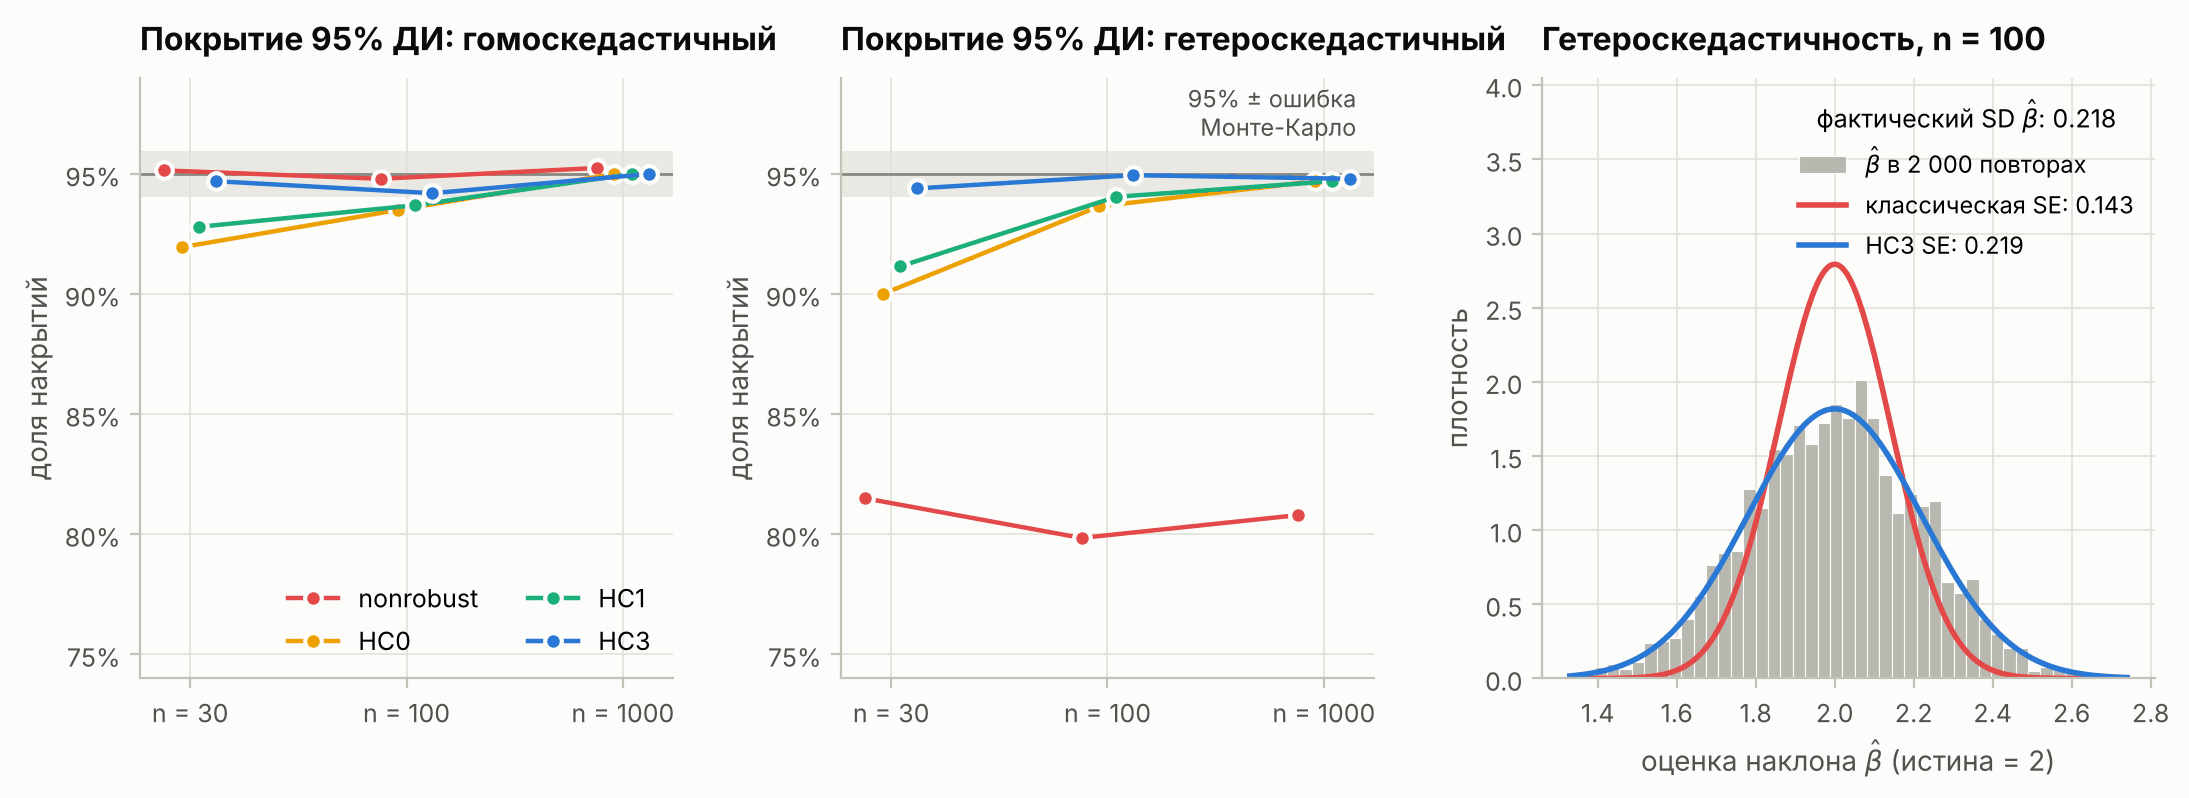

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"wspace": 0.3, "width_ratios": [1, 1, 1.15]})
mc = 1.96 * np.sqrt(0.95 * 0.05 / 2000)
styles = {"nonrobust": C["red"], "HC0": C["yellow"], "HC1": C["aqua"], "HC3": C["blue"]}
for ax, scen in zip(axes[:2], ["гомоскедастичный", "гетероскедастичный"]):
    sub = coverage.loc[scen]
    ax.axhspan(0.95 - mc, 0.95 + mc, color=GRID, alpha=0.7, lw=0)
    ax.axhline(0.95, color=MUTED, lw=1)
    for j, ct in enumerate(styles):
        xs = np.arange(len(sub)) + (j - 1.5) * 0.08
        ax.plot(xs, sub[ct].values, "-o", color=styles[ct], lw=1.6, ms=6, label=ct,
                markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.set_xticks(range(len(sub)), [f"n = {n}" for n in sub.index])
    ax.set_ylim(0.74, 0.99)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
    ax.set(title=f"Покрытие 95% ДИ: {scen}", ylabel="доля накрытий")
axes[0].legend(loc="lower right", ncol=2)
axes[1].text(2.15, 0.95 + mc + 0.004, "95% ± ошибка\nМонте-Карло", fontsize=8.5, color=INK2, ha="right", va="bottom")

ax = axes[2]
slopes, se_c, se_h = sims[True]
grid = np.linspace(slopes.min(), slopes.max(), 300)
ax.hist(slopes, bins=45, density=True, color=NEUTRAL, edgecolor=SURFACE, linewidth=0.4, label=r"$\hat\beta$ в 2 000 повторах")
ax.plot(grid, stats.norm.pdf(grid, 2, se_c.mean()), color=C["red"], lw=2, label=f"классическая SE: {se_c.mean():.3f}")
ax.plot(grid, stats.norm.pdf(grid, 2, se_h.mean()), color=C["blue"], lw=2, label=f"HC3 SE: {se_h.mean():.3f}")
ax.set(title="Гетероскедастичность, n = 100", xlabel=r"оценка наклона $\hat\beta$ (истина = 2)", ylabel="плотность")
ax.set_ylim(0, 1.45 * stats.norm.pdf(0, 0, se_c.mean()))
ax.legend(loc="upper right", fontsize=8.5, title=rf"фактический SD $\hat\beta$: {slopes.std():.3f}")
plt.show()

* Гомоскедастичность: все оценки около 95%; HC0 и HC1 при n = 30 дают 92–93% из-за $\mathsf Ee_i^2=\sigma^2(1-h_{ii})$, HC3 — 94,7%.
* Гетероскедастичность: классическая SE даёт около 80% при любом n, смещение не уходит с ростом выборки; HC3 — 94,4–95,0%. При n = 100 фактический SD наклона 0,218, HC3 — 0,219, классическая — 0,143.
* Дальше по умолчанию HC3.

## 6. Базовая модель M1

МНК для стоимости в долларах на исходные признаки. Качество — 5-fold CV на обучающей выборке.

In [20]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_oof(make_model, X_df, y, target="raw", groups=None):
    """Out-of-fold прогнозы в долларах.
    target: 'raw' — модель на y; 'log' — модель на log y, прогноз exp(·) (условная медиана);
            'log_smear' — то же, умноженное на фактор смешивания Дуана (условное среднее)."""
    oof = np.empty(len(y))
    for tr_idx, va_idx in CV.split(X_df):
        model = make_model()
        if target == "raw":
            model.fit(X_df.iloc[tr_idx], y[tr_idx])
            oof[va_idx] = model.predict(X_df.iloc[va_idx])
        else:
            model.fit(X_df.iloc[tr_idx], np.log(y[tr_idx]))
            pred = np.exp(model.predict(X_df.iloc[va_idx]))
            if target == "log_smear":
                resid = np.log(y[tr_idx]) - model.predict(X_df.iloc[tr_idx])
                pred *= np.mean(np.exp(resid))
            oof[va_idx] = pred
    return oof


def make_m1():
    """M1: МНК на сырых признаках (таргет — стоимость в долларах)."""
    return Pipeline([("pre", make_raw_preprocessor()), ("ols", OLS(cov_type="HC3"))])

m1 = make_m1().fit(train_df, y_train)
ols_m1 = m1.named_steps["ols"]
X1_train = m1.named_steps["pre"].transform(train_df)

print(f"R² = {ols_m1.rsquared_:.3f},  R²adj = {ols_m1.rsquared_adj_:.3f},  "
      f"число обусловленности = {ols_m1.cond_number_:,.0f}")
ols_m1.summary()

R² = 0.610,  R²adj = 0.609,  число обусловленности = 718,953


,coef,std_err,t,p_value,ci_low,ci_high
const,"-2,133,111.7989","92,557.3490",-23.0464,0.0000,"-2,314,534.8311","-1,951,688.7667"
longitude,"-24,926.2046","1,094.0670",-22.7831,0.0000,"-27,070.7015","-22,781.7077"
latitude,"-22,881.8811","1,107.4633",-20.6615,0.0000,"-25,052.6363","-20,711.1259"
housing_median_age,906.0456,54.3472,16.6714,0.0000,799.5188,"1,012.5724"
total_rooms,-6.0875,1.3555,-4.4909,0.0000,-8.7445,-3.4305
total_bedrooms,71.8389,13.0171,5.5188,0.0000,46.3240,97.3538
population,-29.8518,4.8327,-6.1771,0.0000,-39.3245,-20.3792
households,58.6151,17.4509,3.3588,0.0008,24.4092,92.8209
median_income,"37,827.5500",672.3271,56.2636,0.0000,"36,509.7117","39,145.3883"
ocean_proximity_INLAND,"-38,368.5825","1,764.0809",-21.7499,0.0000,"-41,826.3835","-34,910.7814"


In [21]:
oof_m1 = cv_oof(make_m1, train_df, y_train, target="raw")
bp_m1 = breusch_pagan(ols_m1.resid_, X1_train)
print(f"Тест Бройша–Пагана: LM = {bp_m1['LM']:,.0f}, df = {bp_m1['df']}, p-value = {bp_m1['p_value']:.1e}")
print(f"Отрицательных прогнозов стоимости (OOF): {(oof_m1 < 0).sum()}")
pd.DataFrame({"M1 (CV)": regression_report(y_train, oof_m1)}).T

Тест Бройша–Пагана: LM = 545, df = 11, p-value = 7.5e-110
Отрицательных прогнозов стоимости (OOF): 19


,"MAPE, %","MdAPE, %","PE10, %","PE20, %","OVR20, %","RMSE, $","MAE, $",R2
M1 (CV),27.2952,20.0609,26.3532,49.8602,31.6900,"60,915.8679","44,663.0677",0.6081


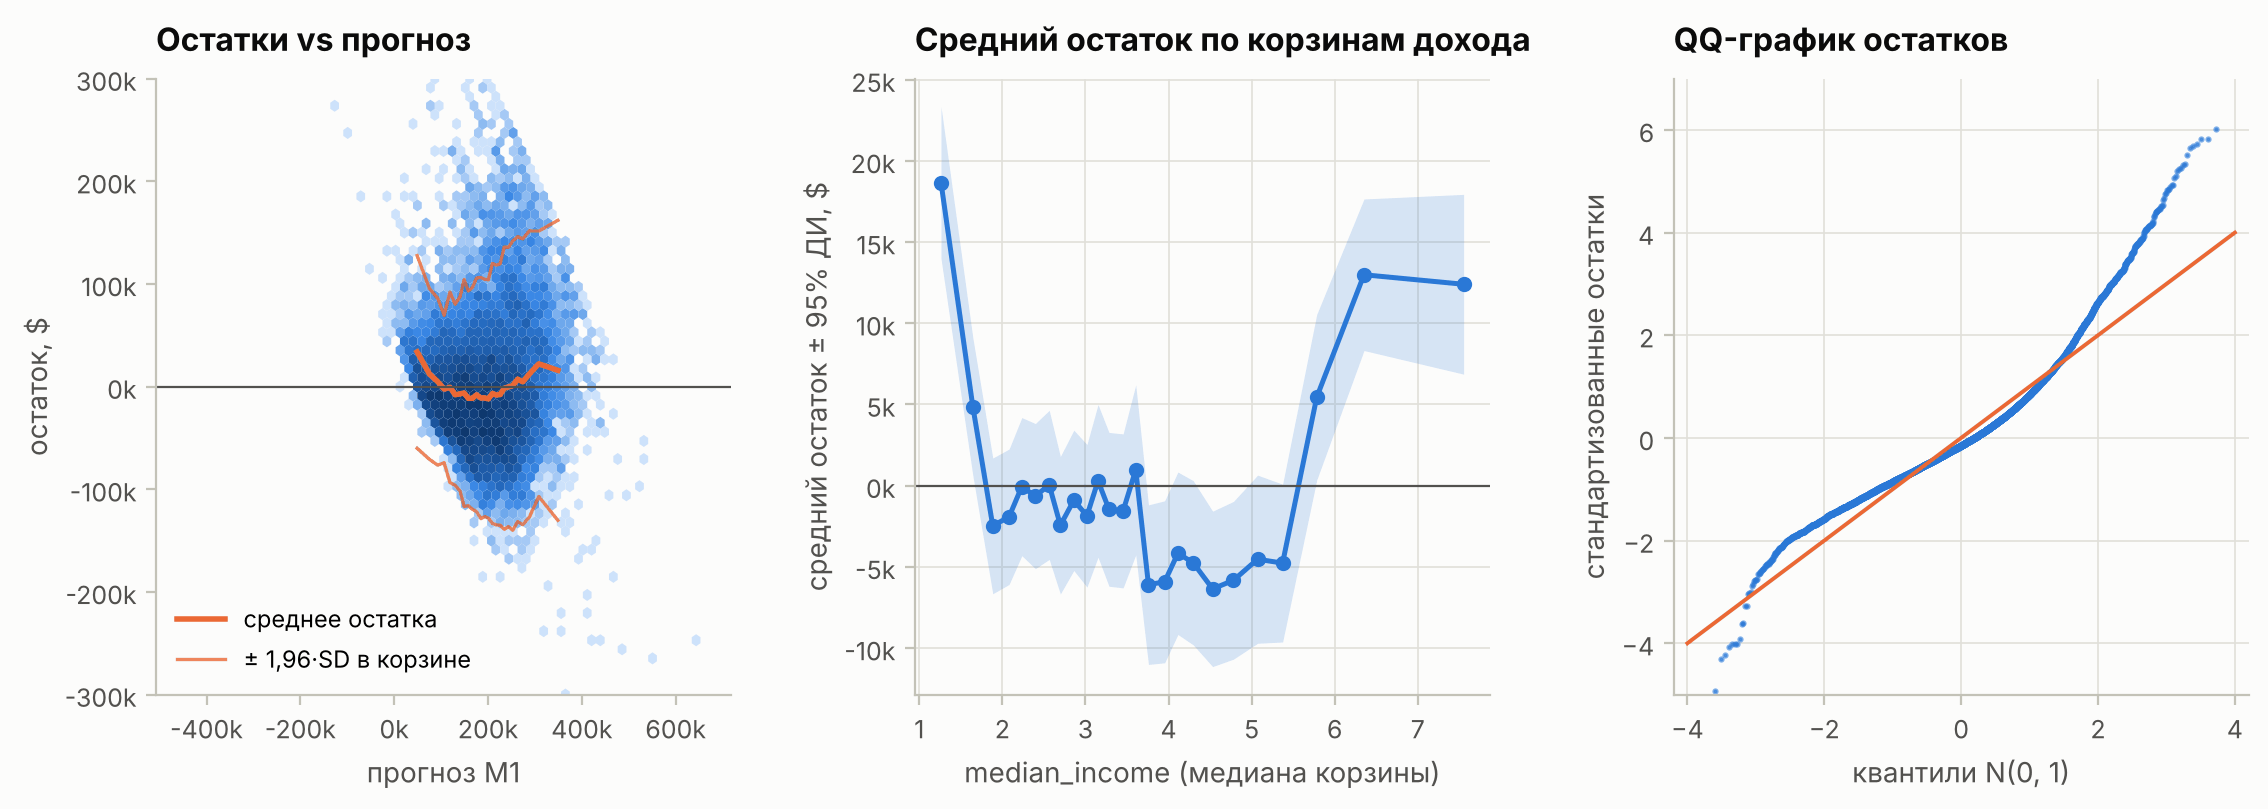

In [22]:
fitted, resid = ols_m1.fittedvalues_, ols_m1.resid_
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), gridspec_kw={"wspace": 0.32})

ax = axes[0]
ax.hexbin(fitted, resid, gridsize=60, cmap=CMAP_SEQ, bins="log", mincnt=1, linewidths=0,
          extent=(fitted.min(), fitted.max(), -300_000, 300_000))
b = binned_stats(fitted, resid, n_bins=25)
ax.plot(b.x, b["mean"], color=C["orange"], lw=2, label="среднее остатка")
ax.plot(b.x, b["mean"] + 1.96 * b.sd, color=C["orange"], lw=1.2, alpha=0.8, label="± 1,96·SD в корзине")
ax.plot(b.x, b["mean"] - 1.96 * b.sd, color=C["orange"], lw=1.2, alpha=0.8)
ax.axhline(0, color=INK2, lw=0.8)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.set(title="Остатки vs прогноз", xlabel="прогноз M1", ylabel="остаток, $", ylim=(-300_000, 300_000))
ax.legend(loc="lower left", fontsize=8.5)
ax.grid(False)

ax = axes[1]
b = binned_stats(train_df.median_income, resid, n_bins=25)
ax.fill_between(b.x, b["mean"] - 1.96 * b.se, b["mean"] + 1.96 * b.se, color=C["blue"], alpha=0.18, lw=0)
ax.plot(b.x, b["mean"], "-o", color=C["blue"], ms=4.5, lw=1.8)
ax.axhline(0, color=INK2, lw=0.8)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.set(title="Средний остаток по корзинам дохода", xlabel="median_income (медиана корзины)", ylabel="средний остаток ± 95% ДИ, $")

ax = axes[2]
z = np.sort((resid - resid.mean()) / resid.std())
q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
ax.plot(q, z, ".", color=C["blue"], ms=2.5, alpha=0.6)
ax.plot([-4, 4], [-4, 4], color=C["orange"], lw=1.4)
ax.set(title="QQ-график остатков", xlabel="квантили N(0, 1)", ylabel="стандартизованные остатки", xlim=(-4.2, 4.2), ylim=(-5, 7))
plt.show()

* Гетероскедастичность: разброс остатков растёт с прогнозом; Бройш–Паган LM = 545, p < 10⁻¹⁰⁰.
* Нелинейность по доходу: занижение при доходе < 1,7 и > 5,5, завышение при 3,8–5,4.
* Правый хвост остатков тяжелее нормального; 19 отрицательных прогнозов на CV.
* CV: MAPE 27,3%, PE20 49,9%, OVR20 31,7%.

## 7. Интерпретируемая модель M2

### 7.1. Преобразование таргета

Профильное правдоподобие Бокса–Кокса для регрессии: $\ell_p(\lambda)=-\frac n2\log\frac{\mathrm{RSS}(\lambda)}n+(\lambda-1)\sum_i\log y_i$; 95% ДИ по LR-критерию.

In [23]:
def boxcox_transform(y, lmbda):
    return np.log(y) if abs(lmbda) < 1e-12 else (y ** lmbda - 1) / lmbda


def boxcox_inverse(z, lmbda):
    return np.exp(z) if abs(lmbda) < 1e-12 else np.clip(lmbda * z + 1, 1e-12, None) ** (1 / lmbda)


X2_np = X2_train.to_numpy()
sum_log_y = np.log(y_train).sum()


def profile_loglik(lmbda):
    m = OLS(cov_type="nonrobust").fit(X2_np, boxcox_transform(y_train, lmbda))
    return -len(y_train) / 2 * np.log(m.ssr_ / len(y_train)) + (lmbda - 1) * sum_log_y


lambdas = np.round(np.arange(-0.3, 1.101, 0.01), 3)
prof = np.array([profile_loglik(l) for l in lambdas])
lam_hat = lambdas[prof.argmax()]
ci_mask = 2 * (prof.max() - prof) <= stats.chi2.ppf(0.95, 1)
lam_ci = lambdas[ci_mask][[0, -1]]
lam_marginal = stats.boxcox(y_train)[1]
lr_log = 2 * (prof.max() - profile_loglik(0.0))
print(f"λ̂ (по регрессии) = {lam_hat:.2f}, 95% ДИ [{lam_ci[0]:.2f}; {lam_ci[1]:.2f}];  "
      f"λ̂ по маргинальному распределению y = {lam_marginal:.2f}")
print(f"LR-статистика для H0: λ = 0 (логарифм): {lr_log:.1f}, p-value = {stats.chi2.sf(lr_log, 1):.1e}")

# Практическая значимость: качество по кросс-валидации для трёх шкал
bc_rows = {}
for name, lmbda in [("λ = 1 (исходная шкала)", 1.0), (f"λ = {lam_hat:.2f} (оптимум)", lam_hat), ("λ = 0 (логарифм)", 0.0)]:
    oof = np.empty(len(y_train))
    for tr_idx, va_idx in CV.split(X2_np):
        m = OLS(cov_type="nonrobust").fit(X2_np[tr_idx], boxcox_transform(y_train[tr_idx], lmbda))
        oof[va_idx] = boxcox_inverse(m.predict(X2_np[va_idx]), lmbda)
    bc_rows[name] = regression_report(y_train, oof)
bc_table = pd.DataFrame(bc_rows).T[["MAPE, %", "MdAPE, %", "PE20, %", "RMSE, $"]]
display(bc_table)

λ̂ (по регрессии) = 0.07, 95% ДИ [0.06; 0.09];  λ̂ по маргинальному распределению y = 0.23
LR-статистика для H0: λ = 0 (логарифм): 49.0, p-value = 2.5e-12


,"MAPE, %","MdAPE, %","PE20, %","RMSE, $"
λ = 1 (исходная шкала),27.3709,19.9643,50.0635,"58,979.5147"
λ = 0.07 (оптимум),22.0972,16.7049,57.6493,"56,965.1042"
λ = 0 (логарифм),21.9559,16.5960,57.9288,"57,079.1581"


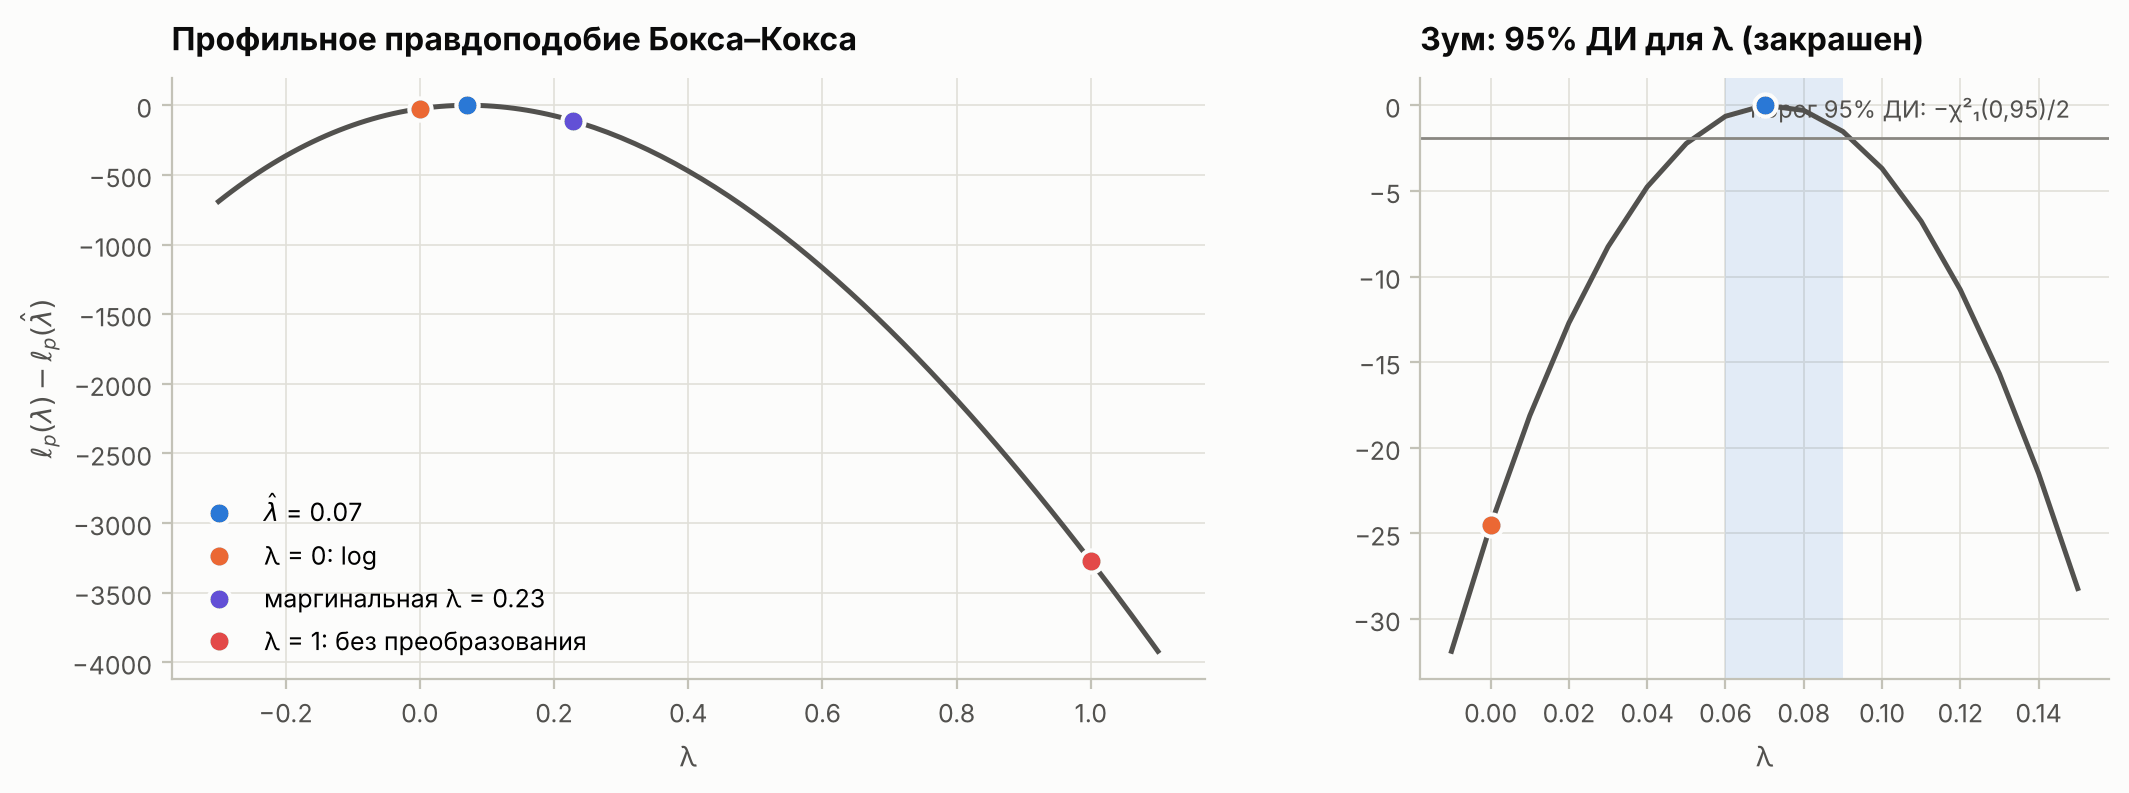

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.25})
rel = prof - prof.max()
crit = stats.chi2.ppf(0.95, 1) / 2
marks = [(lam_hat, r"$\hat\lambda$" + f" = {lam_hat:.2f}", C["blue"]), (0.0, "λ = 0: log", C["orange"]),
         (lam_marginal, f"маргинальная λ = {lam_marginal:.2f}", C["violet"]), (1.0, "λ = 1: без преобразования", C["red"])]
ax = axes[0]
ax.plot(lambdas, rel, color=INK2, lw=1.8)
for x0, label, col in marks:
    y0 = profile_loglik(x0) - prof.max()
    ax.plot(x0, y0, "o", color=col, ms=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3, label=label)
ax.set(title="Профильное правдоподобие Бокса–Кокса", xlabel="λ", ylabel=r"$\ell_p(\lambda) - \ell_p(\hat\lambda)$")
ax.legend(loc="lower left")

ax = axes[1]
zoom = (lambdas >= -0.01) & (lambdas <= 0.15)
ax.plot(lambdas[zoom], rel[zoom], color=INK2, lw=1.8)
ax.axhline(-crit, color=MUTED, lw=1)
ax.axvspan(lam_ci[0], lam_ci[1], color=C["blue"], alpha=0.12, lw=0)
ax.text(0.148, -crit + 1.2, "порог 95% ДИ: −χ²₁(0,95)/2", ha="right", fontsize=8.5, color=INK2)
for x0, label, col in marks[:2]:
    ax.plot(x0, profile_loglik(x0) - prof.max(), "o", color=col, ms=8, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
ax.set(title="Зум: 95% ДИ для λ (закрашен)", xlabel="λ")
plt.show()

$\hat\lambda=0{,}07$, 95% ДИ [0,06; 0,09]; по маргинальному распределению $y$ получилось бы 0,23. При n ≈ 16 тыс. λ = 0 формально отвергается (LR = 49), но по CV логарифм не хуже оптимума: MAPE 21,96% против 22,10%. Берём log ради интерпретации в процентах.

### 7.2. Оценка M2 (HC3)

In [25]:
ols_m2 = OLS(cov_type="HC3").fit(X2_train, ly_train)
global_f = ols_m2.wald_test(ols_m2.param_names_[1:])
bp_m2 = breusch_pagan(ols_m2.resid_, X2_train)
print(f"R² = {ols_m2.rsquared_:.3f}, R²adj = {ols_m2.rsquared_adj_:.3f}, n = {ols_m2.nobs_}, k = {ols_m2.k_}")
print(f"Совместная значимость (Вальд, HC3): F = {global_f['F']:,.0f}, p-value = {global_f['p_value']:.1e}")
print(f"Бройш–Паган: LM = {bp_m2['LM']:,.0f}, p-value = {bp_m2['p_value']:.1e}")
summary_m2 = ols_m2.summary()
summary_m2

R² = 0.711, R²adj = 0.711, n = 15740, k = 17
Совместная значимость (Вальд, HC3): F = 2,289, p-value = 0.0e+00
Бройш–Паган: LM = 1,074, p-value = 1.7e-218


,coef,std_err,t,p_value,ci_low,ci_high
const,13.5805,0.1142,118.9427,0.0000,13.3567,13.8043
log_income,0.6437,0.0114,56.5684,0.0000,0.6213,0.6660
housing_median_age,-0.0028,0.0003,-9.3718,0.0000,-0.0034,-0.0022
age_capped,0.1295,0.0141,9.1800,0.0000,0.1019,0.1572
log_rooms_per_hh,0.2613,0.0228,11.4367,0.0000,0.2165,0.3061
bedrooms_ratio,0.9956,0.1299,7.6653,0.0000,0.7410,1.2502
log_people_per_hh,-0.4584,0.0135,-33.8957,0.0000,-0.4849,-0.4319
log_households,0.0132,0.0049,2.7139,0.0067,0.0037,0.0228
log_dist_SF,-0.1596,0.0065,-24.6586,0.0000,-0.1722,-0.1469
log_dist_SJ,-0.0596,0.0045,-13.2711,0.0000,-0.0684,-0.0508


### 7.3. Остатки M1 и M2

Остатки нормированы на свой SD, по оси x — перцентиль прогноза.

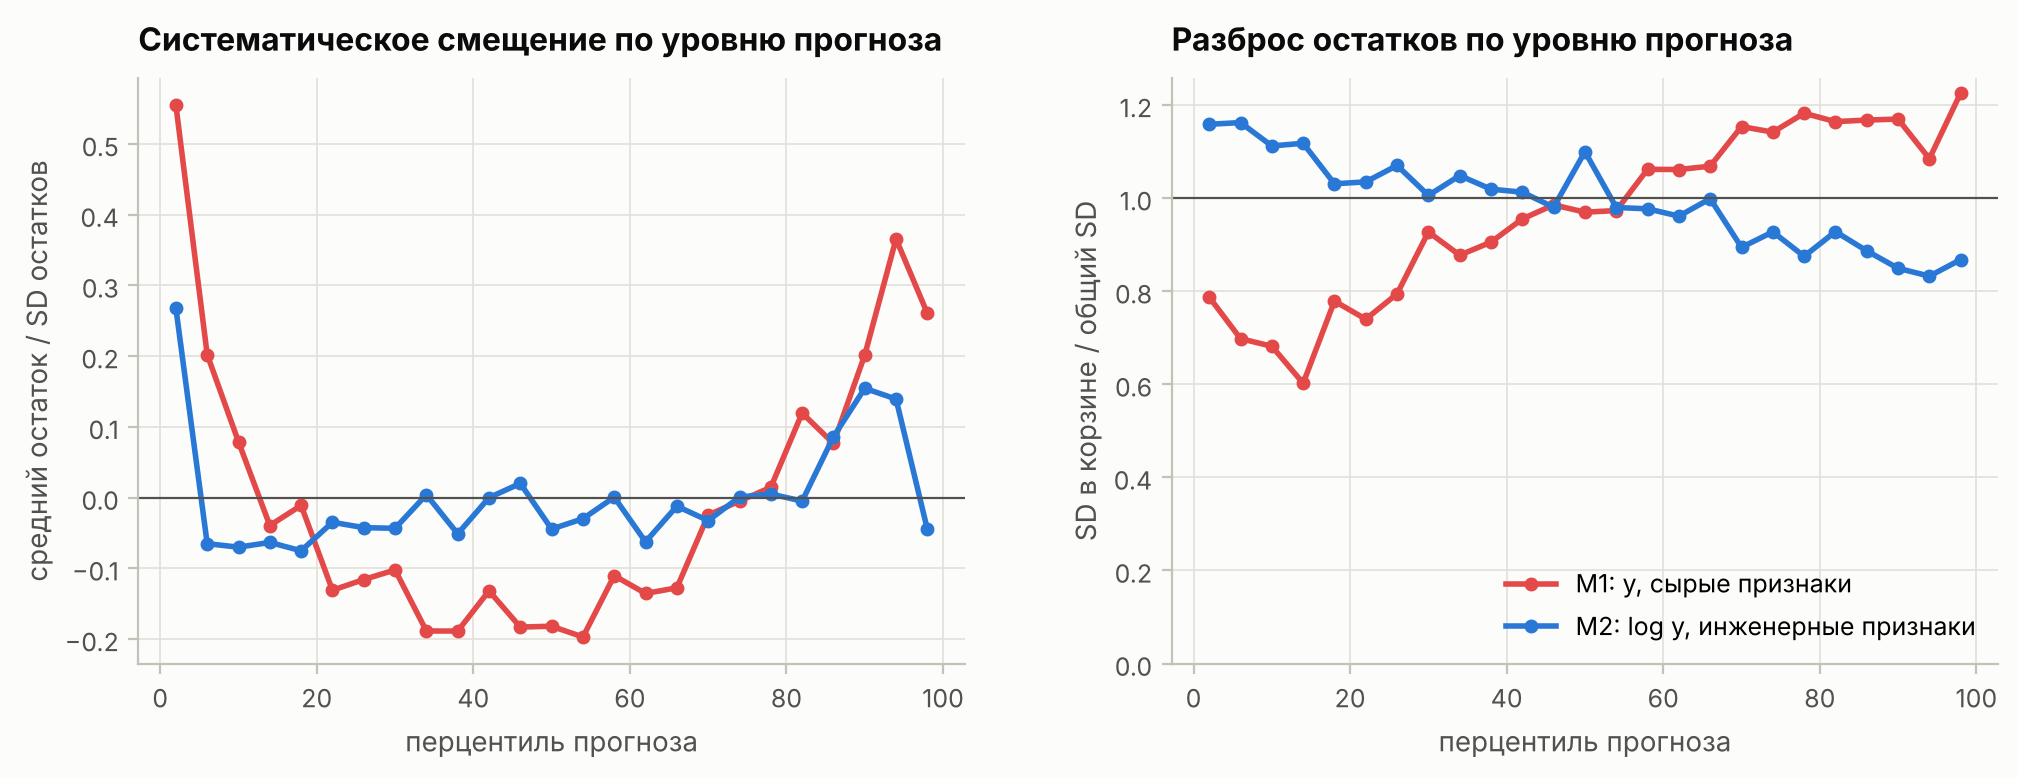

In [26]:
def relative_bins(fitted, resid, n_bins=25):
    pct = stats.rankdata(fitted) / len(fitted) * 100
    b = binned_stats(pct, resid / resid.std(), n_bins)
    return b

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"wspace": 0.25})
for model, name, col in [(ols_m1, "M1: y, сырые признаки", C["red"]), (ols_m2, "M2: log y, инженерные признаки", C["blue"])]:
    b = relative_bins(model.fittedvalues_, model.resid_)
    axes[0].plot(b.x, b["mean"], "-o", ms=4, color=col, label=name)
    axes[1].plot(b.x, b["sd"], "-o", ms=4, color=col, label=name)
axes[0].axhline(0, color=INK2, lw=0.8)
axes[0].set(title="Систематическое смещение по уровню прогноза", xlabel="перцентиль прогноза",
            ylabel="средний остаток / SD остатков")
axes[1].axhline(1, color=INK2, lw=0.8)
axes[1].set(title="Разброс остатков по уровню прогноза", xlabel="перцентиль прогноза",
            ylabel="SD в корзине / общий SD", ylim=(0, None))
axes[1].legend(loc="lower right")
plt.show()

На 5–85-м перцентилях средний остаток M2 в пределах ±0,08 SD; у M1 от −0,2 до +0,2, на краях до +0,55. Отношение локального SD к общему: 0,83–1,16 у M2 против 0,60–1,23 у M1. Гетероскедастичность сохраняется (Бройш–Паган p ≈ 10⁻²¹⁸): выводы по M2 делаются с HC3, для интервалов в разделе 10 нужна модель дисперсии.

### 7.4. Частные остатки

$e_i+\hat\beta_jx_{ij}$ против $x_{ij}$; при линейной зависимости среднее по корзинам совпадает с прямой $\hat\beta_jx_j$.

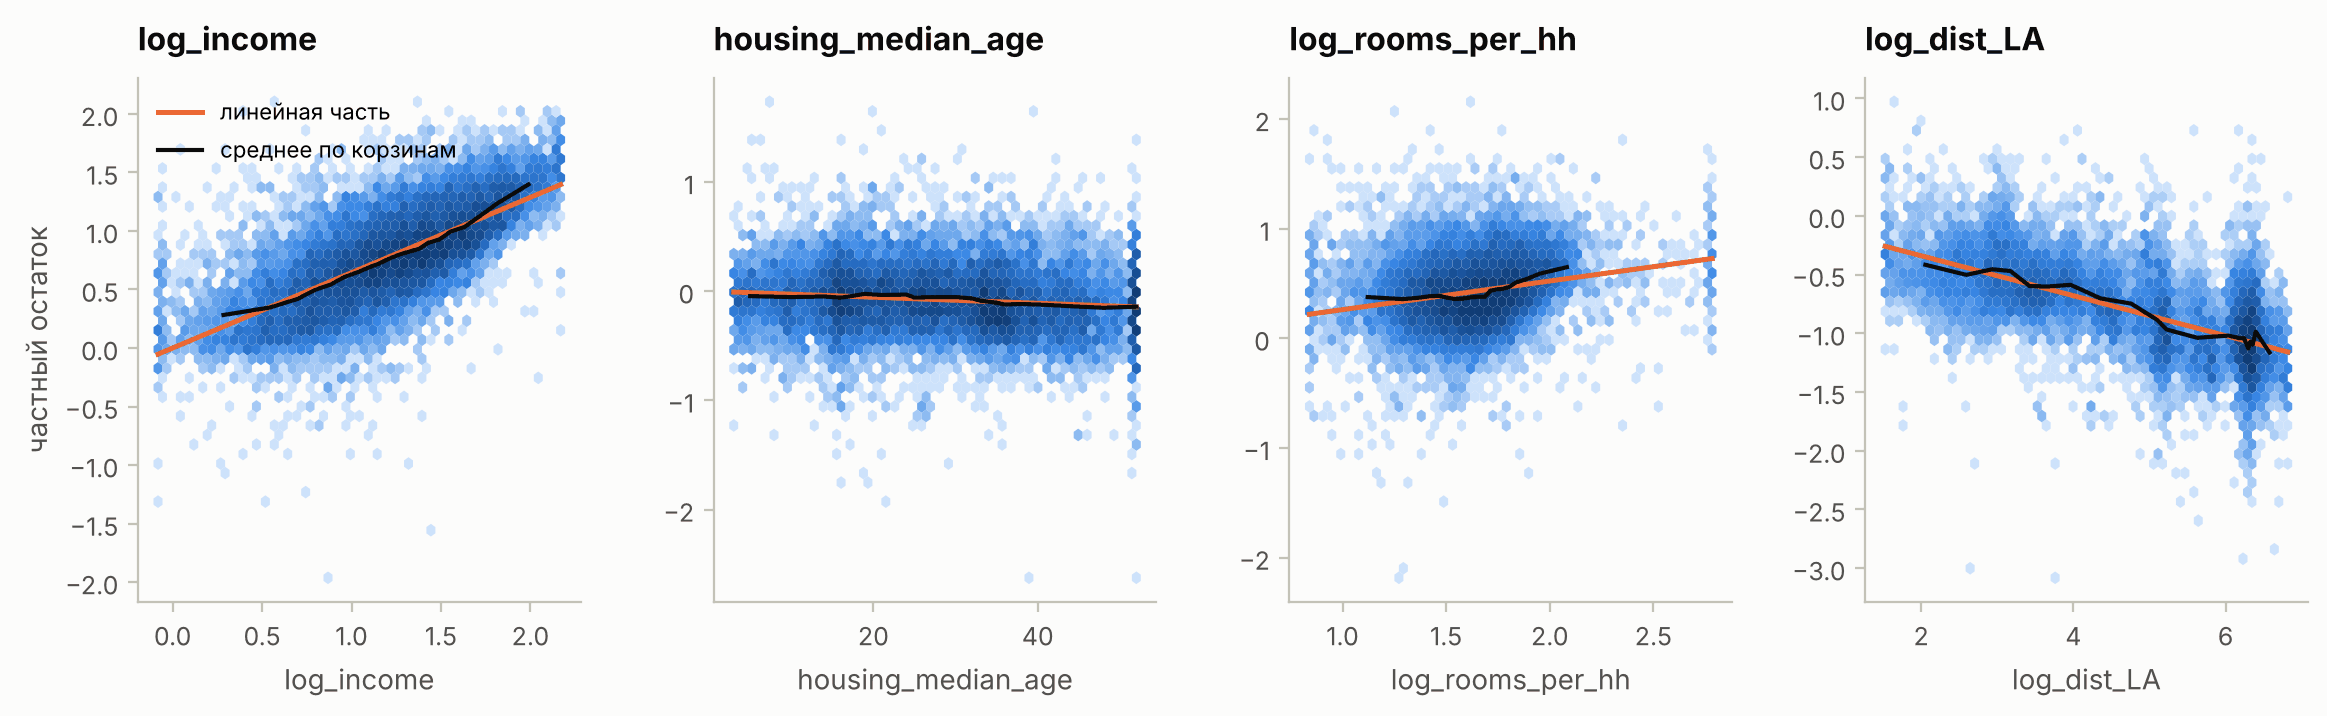

In [27]:
partial = ["log_income", "housing_median_age", "log_rooms_per_hh", "log_dist_LA"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), gridspec_kw={"wspace": 0.3})
for ax, feat in zip(axes, partial):
    x = X2_train[feat].to_numpy()
    beta = ols_m2.params_[ols_m2.param_names_.index(feat)]
    comp = ols_m2.resid_ + beta * x
    ax.hexbin(x, comp, gridsize=45, cmap=CMAP_SEQ, bins="log", mincnt=1, linewidths=0)
    xx = np.linspace(x.min(), x.max(), 50)
    ax.plot(xx, beta * xx, color=C["orange"], lw=1.8, label="линейная часть")
    b = binned_stats(x, comp, n_bins=20)
    ax.plot(b.x, b["mean"], "-", color=INK, lw=1.5, label="среднее по корзинам")
    ax.set(title=feat, xlabel=feat, ylabel="частный остаток" if feat == partial[0] else None)
    ax.grid(False)
axes[0].legend(loc="upper left", fontsize=8)
plt.show()

Линейная форма адекватна. Слабая выпуклость у `log_income` при низком доходе и у `log_rooms_per_hh` в правом хвосте учтена сплайном в расширенной модели.

### 7.5. Классические, HC3 и кластерные SE

Кластеры — ячейки сетки 0,25° × 0,25° (около 28 × 22 км): у соседних кварталов общие ненаблюдаемые факторы.

In [28]:
def spatial_cells(df, size=0.25):
    """Идентификатор ячейки географической сетки для кластерных SE."""
    return (np.floor(df.latitude / size).astype(int).astype(str) + "_" +
            np.floor(df.longitude / size).astype(int).astype(str)).to_numpy()


cells_train = spatial_cells(train_df)
sizes = pd.Series(cells_train).value_counts()
print(f"Кластеров: {sizes.size}; размер: медиана {sizes.median():.0f}, максимум {sizes.max()}")

se_table = pd.DataFrame({
    "classic": ols_m2.summary("nonrobust")["std_err"],
    "HC3": ols_m2.summary("HC3")["std_err"],
    "cluster": ols_m2.summary("cluster", cells_train)["std_err"],
})
se_table["HC3 / classic"] = se_table["HC3"] / se_table["classic"]
se_table["cluster / HC3"] = se_table["cluster"] / se_table["HC3"]
p_cluster = ols_m2.summary("cluster", cells_train)["p_value"]
se_table["p (HC3)"] = summary_m2["p_value"]
se_table["p (cluster)"] = p_cluster
se_table

Кластеров: 475; размер: медиана 4, максимум 1049


,classic,HC3,cluster,HC3 / classic,cluster / HC3,p (HC3),p (cluster)
const,0.0876,0.1142,0.3242,1.3032,2.8397,0.0000,0.0000
log_income,0.0087,0.0114,0.0323,1.3097,2.8368,0.0000,0.0000
housing_median_age,0.0003,0.0003,0.0007,1.1695,2.4797,0.0000,0.0002
age_capped,0.0118,0.0141,0.0319,1.1925,2.2585,0.0000,0.0001
log_rooms_per_hh,0.0169,0.0228,0.0406,1.3528,1.7752,0.0000,0.0000
bedrooms_ratio,0.0883,0.1299,0.3071,1.4709,2.3643,0.0000,0.0013
log_people_per_hh,0.0100,0.0135,0.0418,1.3532,3.0927,0.0000,0.0000
log_households,0.0035,0.0049,0.0084,1.3918,1.7279,0.0067,0.1169
log_dist_SF,0.0060,0.0065,0.0272,1.0773,4.2071,0.0000,0.0000
log_dist_SJ,0.0046,0.0045,0.0211,0.9787,4.6976,0.0000,0.0049


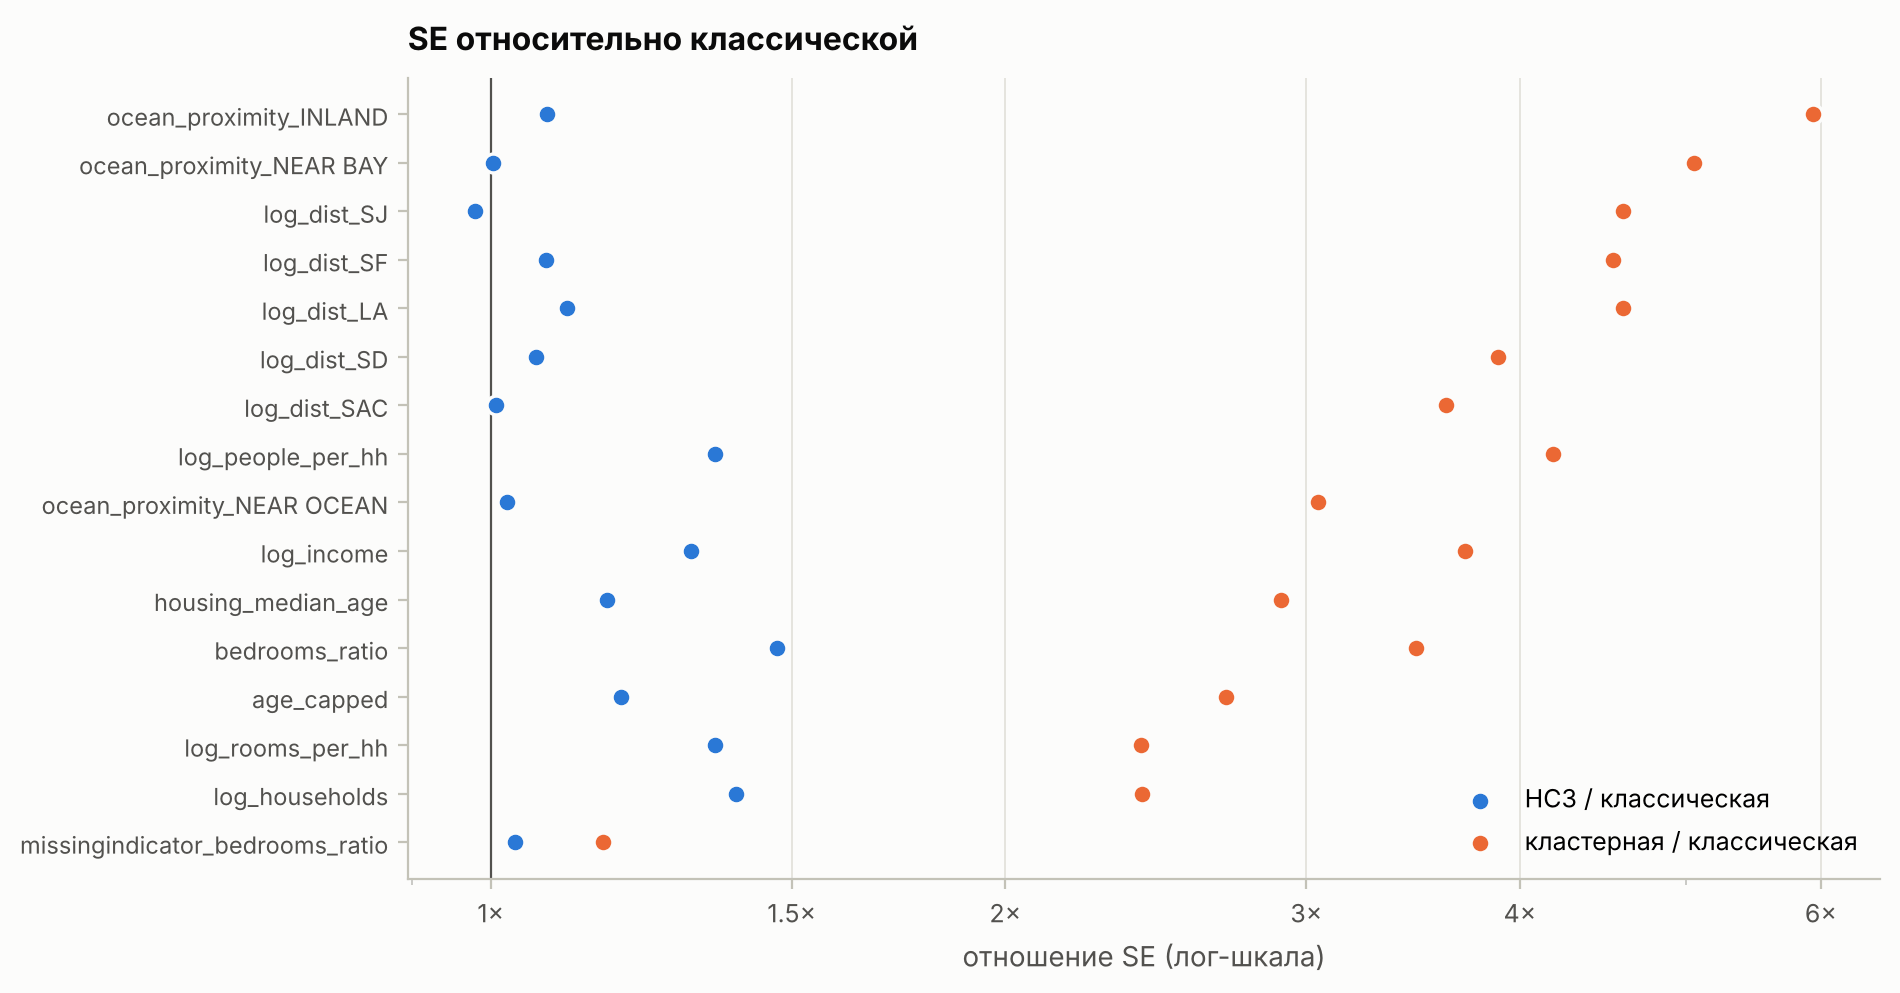

In [29]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
order = se_table.drop(index="const").sort_values("cluster / HC3").index
ypos = np.arange(len(order))
ax.scatter(se_table.loc[order, "HC3 / classic"], ypos, color=C["blue"], s=46, zorder=3, label="HC3 / классическая",
           edgecolor=SURFACE, linewidth=1.2)
ax.scatter(se_table.loc[order, "cluster"] / se_table.loc[order, "classic"], ypos, color=C["orange"], s=46, zorder=3,
           label="кластерная / классическая", edgecolor=SURFACE, linewidth=1.2)
ax.axvline(1, color=INK2, lw=0.8)
ax.set_yticks(ypos, order, fontsize=8.5)
ax.set_xscale("log")
ax.set_xticks([1, 1.5, 2, 3, 4, 6])
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v:g}×"))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set(title="SE относительно классической", xlabel="отношение SE (лог-шкала)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

* HC3 больше классических SE не более чем в 1,5 раза.
* Кластерные SE больше HC3 в 1,1–5,5 раза, сильнее всего у географии: дамми близости к океану в 3–5,5 раза, расстояния в 3,6–4,7 раза.
* С кластерными SE незначимы `log_households` (p = 0,12) и `log_dist_SAC` (p = 0,15).
* Кластеры несбалансированы (медиана 4 квартала, максимум 1 049 в центре LA), поэтому кластерная оценка — верхняя граница неопределённости, HC3 — нижняя.

### 7.6. Тест Вальда

In [30]:
dist_cols = [f"log_dist_{c}" for c in METRO_CENTERS]
ocean_cols = [c for c in X2_train.columns if c.startswith("ocean_proximity_")]
hypotheses = {
    "география: 5 расстояний = 0": dist_cols,
    "близость к океану: 3 дамми = 0": ocean_cols,
    "индикатор пропуска bedrooms = 0": ["missingindicator_bedrooms_ratio"],
    "индикатор age_capped = 0": ["age_capped"],
}
rows = []
for name, cols in hypotheses.items():
    w_h = ols_m2.wald_test(cols)
    w_c = ols_m2.wald_test(cols, cov_type="cluster", groups=cells_train)
    rows.append({"гипотеза H0": name, "q": w_h["df_num"], "F (HC3)": w_h["F"], "p (HC3)": w_h["p_value"],
                 "F (cluster)": w_c["F"], "p (cluster)": w_c["p_value"]})
pd.DataFrame(rows).set_index("гипотеза H0")

,q,F (HC3),p (HC3),F (cluster),p (cluster)
гипотеза H0,,,,,
география: 5 расстояний = 0,5,466.0146,0.0000,34.9934,0.0000
близость к океану: 3 дамми = 0,3,787.3962,0.0000,41.4330,0.0000
индикатор пропуска bedrooms = 0,1,0.2767,0.5989,0.2184,0.6404
индикатор age_capped = 0,1,84.2723,0.0000,16.5213,0.0001


География и близость к океану значимы совместно при любой оценке ковариации. Индикатор пропуска незначим (p = 0,60 и 0,64), что согласуется с MCAR. `age_capped` значим (p < 0,001): обрезанное значение 52 скрывает старую застройку центров.

### 7.7. Эффекты

Для лог-признаков рост на 10% умножает цену на $1{,}1^{\beta}$, для возраста — на $e^{\beta\Delta}$, для дамми эффект $e^{\beta}-1$. ДИ эффектов — преобразование границ ДИ для $\beta$.

In [31]:
effect_spec = {  # признак: (тип, приращение, подпись)
    "log_income": ("log", 0.10, "доход +10%"),
    "log_rooms_per_hh": ("log", 0.10, "комнат на домохозяйство +10%"),
    "log_people_per_hh": ("log", 0.10, "жителей на домохозяйство +10%"),
    "log_households": ("log", 0.10, "размер квартала (домохозяйств) +10%"),
    "bedrooms_ratio": ("lin", 0.05, "доля спален +5 п. п."),
    "housing_median_age": ("lin", 10, "возраст домов +10 лет"),
    "log_dist_SF": ("log", 0.10, "расстояние до SF +10%"),
    "log_dist_SJ": ("log", 0.10, "расстояние до SJ +10%"),
    "log_dist_SAC": ("log", 0.10, "расстояние до SAC +10%"),
    "log_dist_LA": ("log", 0.10, "расстояние до LA +10%"),
    "log_dist_SD": ("log", 0.10, "расстояние до SD +10%"),
    "ocean_proximity_INLAND": ("dummy", 1, "INLAND vs <1H OCEAN"),
    "ocean_proximity_NEAR BAY": ("dummy", 1, "NEAR BAY vs <1H OCEAN"),
    "ocean_proximity_NEAR OCEAN": ("dummy", 1, "NEAR OCEAN vs <1H OCEAN"),
    "age_capped": ("dummy", 1, "возраст «52+» vs ровно 52"),
}


def effect_pct(beta, kind, delta):
    """Изменение цены в % при приращении признака (модель для log y)."""
    if kind == "log":
        return 100 * ((1 + delta) ** beta - 1)
    return 100 * (np.exp(beta * delta) - 1)


summ_cl = ols_m2.summary("cluster", cells_train)
eff_rows = []
for feat, (kind, delta, label) in effect_spec.items():
    s_h, s_c = summary_m2.loc[feat], summ_cl.loc[feat]
    eff_rows.append({
        "эффект": label, "изменение цены, %": effect_pct(s_h.coef, kind, delta),
        "95% ДИ HC3: от": effect_pct(s_h.ci_low, kind, delta), "до": effect_pct(s_h.ci_high, kind, delta),
        "95% ДИ cluster: от": effect_pct(s_c.ci_low, kind, delta), "до ": effect_pct(s_c.ci_high, kind, delta),
        "p (cluster)": s_c.p_value,
    })
effects = pd.DataFrame(eff_rows).set_index("эффект")
effects

,"изменение цены, %",95% ДИ HC3: от,до,95% ДИ cluster: от,до,p (cluster)
эффект,,,,,,
доход +10%,6.3267,6.1010,6.5530,5.6859,6.9714,0.0000
комнат на домохозяйство +10%,2.5215,2.0849,2.9600,1.7458,3.3032,0.0000
жителей на домохозяйство +10%,-4.2752,-4.5167,-4.0330,-5.0221,-3.5224,0.0000
размер квартала (домохозяйств) +10%,0.1260,0.0350,0.2171,-0.0316,0.2838,0.1169
доля спален +5 п. п.,5.1039,3.7745,6.4504,1.9802,8.3233,0.0013
возраст домов +10 лет,-2.7331,-3.2953,-2.1678,-4.1245,-1.3216,0.0002
расстояние до SF +10%,-1.5092,-1.6282,-1.3901,-2.0101,-1.0058,0.0000
расстояние до SJ +10%,-0.5661,-0.6495,-0.4827,-0.9580,-0.1727,0.0049
расстояние до SAC +10%,-0.2146,-0.2963,-0.1329,-0.5087,0.0803,0.1532


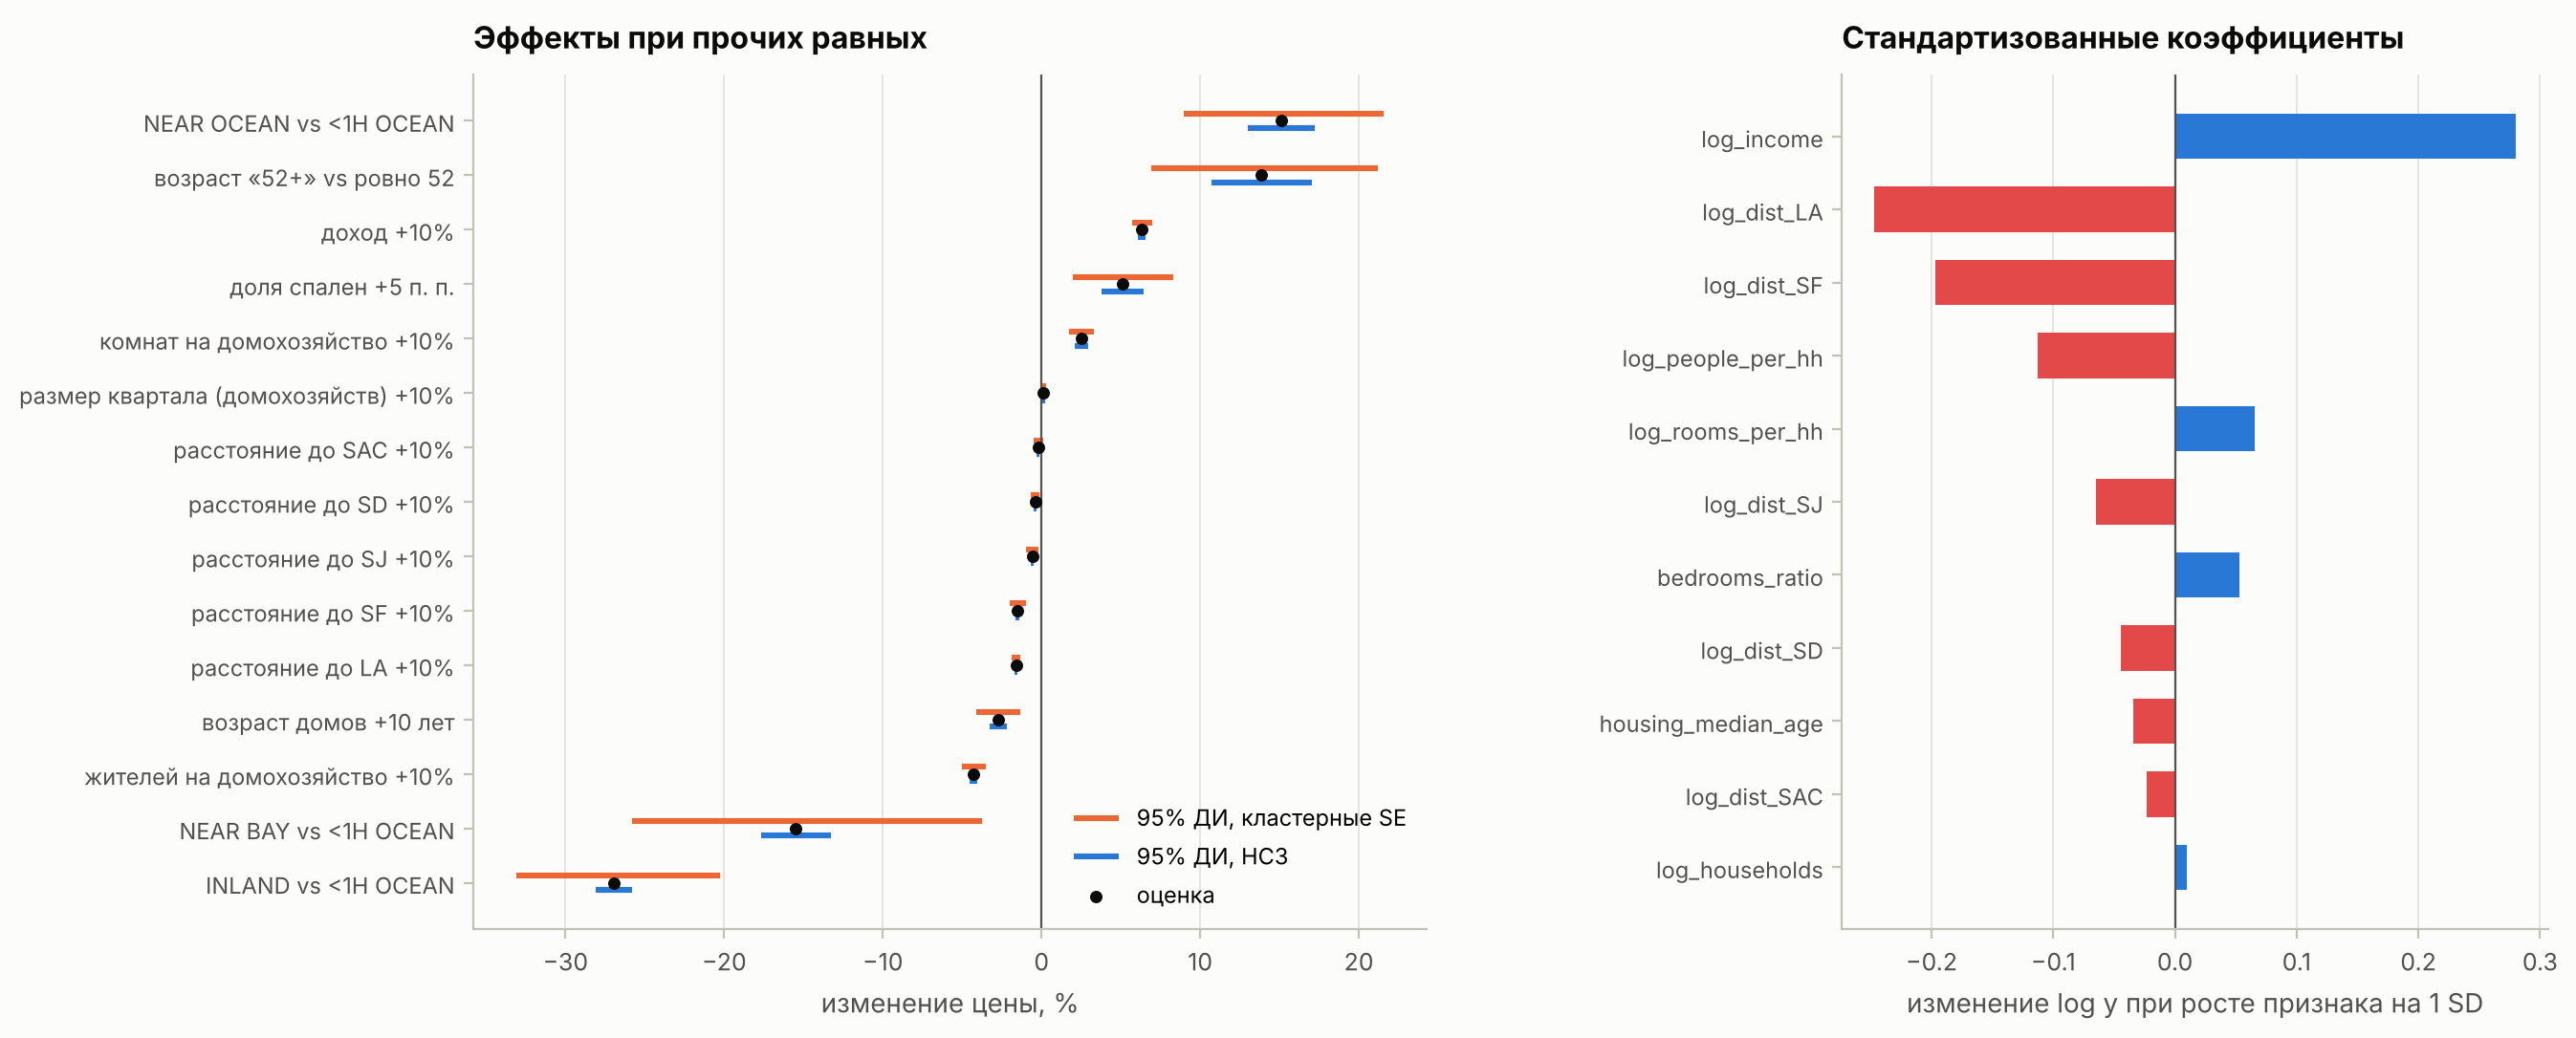

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.35, 1], "wspace": 0.5})
ax = axes[0]
eff_plot = effects.sort_values("изменение цены, %")
ypos = np.arange(len(eff_plot))
ax.hlines(ypos + 0.13, eff_plot["95% ДИ cluster: от"], eff_plot["до "], color=C["orange"], lw=2.2, label="95% ДИ, кластерные SE")
ax.hlines(ypos - 0.13, eff_plot["95% ДИ HC3: от"], eff_plot["до"], color=C["blue"], lw=2.2, label="95% ДИ, HC3")
ax.scatter(eff_plot["изменение цены, %"], ypos, color=INK, s=22, zorder=3, label="оценка")
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(ypos, eff_plot.index, fontsize=8.5)
ax.set(title="Эффекты при прочих равных", xlabel="изменение цены, %")
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(axis="y", visible=False)

ax = axes[1]
cont = [f for f in NUM_FEATURES if f != "age_capped"]
std_coef = pd.Series({f: summary_m2.loc[f, "coef"] * X2_train[f].std() for f in cont})
std_coef = std_coef.reindex(std_coef.abs().sort_values().index)
ax.barh(std_coef.index, std_coef.values, color=[C["blue"] if v > 0 else C["red"] for v in std_coef.values], height=0.62)
ax.axvline(0, color=INK2, lw=0.8)
ax.set(title="Стандартизованные коэффициенты", xlabel="изменение log y при росте признака на 1 SD")
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="y", visible=False)
plt.show()

* Доход +10%: цена +6,3% (кластерный ДИ [5,7; 7,0]).
* INLAND: −27% к `<1H OCEAN` (ДИ [−33; −20]), NEAR OCEAN: +15%. Расстояние до LA или SF +10%: −1,5…−1,6%.
* Жителей на домохозяйство +10%: −4,3%; комнат на домохозяйство +10%: +2,5%.
* Возраст: −2,7% за 10 лет; у «52+» премия 14%.
* NEAR BAY: −15,5% при фиксированных расстояниях до центров; это условный эффект, а не разница средних по группам.
* По стандартизованным коэффициентам основные драйверы — доход, расстояния до LA и SF, плотность населения.

### 7.8. Ретрансформация

$\exp(\widehat{\log y})$ оценивает условную медиану; для среднего — множитель Дуана $\overline{e^{e_i}}$.

In [33]:
def make_m2():
    """M2: МНК на интерпретируемых признаках (таргет — log стоимости)."""
    return Pipeline([("pre", make_interpretable_preprocessor()), ("ols", OLS(cov_type="HC3"))])


oof_m2_med = cv_oof(make_m2, train_df, y_train, target="log")
oof_m2_mean = cv_oof(make_m2, train_df, y_train, target="log_smear")
smear = np.mean(np.exp(ols_m2.resid_))
retr = report_table({"M1: МНК, y": oof_m1, "M2: exp(прогноз) — медиана": oof_m2_med,
                     "M2: × smearing — среднее": oof_m2_mean}, y_train)
retr["средний сдвиг, %"] = [100 * (p.mean() - y_train.mean()) / y_train.mean() for p in (oof_m1, oof_m2_med, oof_m2_mean)]
print(f"Фактор смешивания Дуана: {smear:.4f}")
retr[["MAPE, %", "MdAPE, %", "PE20, %", "OVR20, %", "RMSE, $", "R2", "средний сдвиг, %"]]

Фактор смешивания Дуана: 1.0428


,"MAPE, %","MdAPE, %","PE20, %","OVR20, %","RMSE, $",R2,"средний сдвиг, %"
"M1: МНК, y",27.2952,20.0609,49.8602,31.6900,"60,915.8679",0.6081,-0.0095
M2: exp(прогноз) — медиана,21.9553,16.6267,57.9352,23.3482,"57,077.4644",0.6559,-3.8340
M2: × smearing — среднее,23.3615,17.6817,55.3431,29.4282,"56,569.5283",0.6620,0.2767


Медиана лучше по MAPE (21,96% против 23,36%) и OVR20 (23,3% против 29,4%), но занижает средний уровень на 3,8%. Smearing (×1,043) убирает сдвиг и немного улучшает RMSE. Для оценки отдельных залогов используется медиана, для агрегатов портфеля — smearing.

M2 против M1 (CV): MAPE 27,3% → 22,0%, PE20 49,9% → 57,9%, OVR20 31,7% → 23,3%.

## 8. Регуляризация

| | Функционал (параметризация scikit-learn) |
|---|---|
| Ridge | $\lVert y-Xw\rVert_2^2+\alpha\lVert w\rVert_2^2$ |
| Lasso | $\frac1{2n}\lVert y-Xw\rVert_2^2+\alpha\lVert w\rVert_1$ |
| ElasticNet | $\frac1{2n}\lVert y-Xw\rVert_2^2+\alpha\rho\lVert w\rVert_1+\frac{\alpha(1-\rho)}2\lVert w\rVert_2^2$ |

Ridge: $\hat w=(X^\top X+\alpha I)^{-1}X^\top y$, $\kappa(X^\top X+\alpha I)=\frac{d_{\max}^2+\alpha}{d_{\min}^2+\alpha}$. Lasso решается покоординатным спуском с мягким порогом $S_\alpha(z)=\operatorname{sign}(z)\max(|z|-\alpha,0)$. Признаки стандартизованы, свободный член не штрафуется.

### 8.1. Расширенное пространство и кросс-валидация

Препроцессор (центры KMeans, квантили, скейлер) обучается заново в каждом фолде. α выбирается по правилу одной стандартной ошибки: максимальное α с CV-ошибкой не выше минимума + 1 SE.

In [34]:
def clean_name(name):
    """Читаемые имена признаков расширенного пространства."""
    for prefix in ("inter__", "flags__", "splines__", "geo__"):
        name = name.replace(prefix, "")
    return name.replace("ocean_proximity_", "ocean=").replace(" ", " × ")


ext_pre = make_extended_preprocessor().fit(train_df)
Xe_train, Xe_test = ext_pre.transform(train_df), ext_pre.transform(test_df)
ext_names = np.array([clean_name(n) for n in ext_pre.get_feature_names_out()])
eig_xtx = np.linalg.eigvalsh(Xe_train.T @ Xe_train)
print(f"Расширенное пространство: {Xe_train.shape[1]} признаков, ранг {np.linalg.matrix_rank(Xe_train)}")
print(f"κ(X) = {np.sqrt(eig_xtx.max() / eig_xtx.min()):,.0f},  κ(XᵀX) = {eig_xtx.max() / eig_xtx.min():.2e}")

t0 = time.time()
ext_folds = []
for tr_idx, va_idx in CV.split(train_df):
    pre_f = make_extended_preprocessor().fit(train_df.iloc[tr_idx])
    ext_folds.append({"Xtr": pre_f.transform(train_df.iloc[tr_idx]), "ytr": ly_train[tr_idx],
                      "Xva": pre_f.transform(train_df.iloc[va_idx]), "yva": ly_train[va_idx], "va": va_idx})
print(f"Признаки для 5 фолдов построены за {time.time() - t0:.1f} с")

Расширенное пространство: 213 признаков, ранг 213
κ(X) = 133,542,  κ(XᵀX) = 1.78e+10
Признаки для 5 фолдов построены за 2.0 с


In [35]:
def ridge_path(X, y, alphas):
    """Коэффициенты Ridge для сетки α через спектральное разложение XᵀX (X центрирована)."""
    evals, V = np.linalg.eigh(X.T @ X)
    Xty = V.T @ (X.T @ (y - y.mean()))
    return np.stack([V @ (Xty / (evals + a)) for a in alphas], axis=1)


def l1_path(X, y, alphas, l1_ratio=1.0):
    """Коэффициенты Lasso/ElasticNet для сетки α (в порядке переданной сетки)."""
    order = np.argsort(alphas)[::-1]
    _, coefs, _ = enet_path(X, y - y.mean(), l1_ratio=l1_ratio, alphas=np.asarray(alphas)[order], max_iter=50_000)
    out = np.empty_like(coefs)
    out[:, order] = coefs
    return out


def cv_curve(path_fn, alphas, folds=None):
    """RMSE в лог-шкале на валидации и обучении для каждого α и фолда, плюс OOF-прогнозы."""
    folds = ext_folds if folds is None else folds
    val, trn = np.empty((len(folds), len(alphas))), np.empty((len(folds), len(alphas)))
    oof = np.empty((len(ly_train), len(alphas)))
    for i, f in enumerate(folds):
        W = path_fn(f["Xtr"], f["ytr"], alphas)          # p × n_alphas
        pred_va = f["ytr"].mean() + f["Xva"] @ W
        pred_tr = f["ytr"].mean() + f["Xtr"] @ W
        val[i] = np.sqrt(np.mean((f["yva"][:, None] - pred_va) ** 2, axis=0))
        trn[i] = np.sqrt(np.mean((f["ytr"][:, None] - pred_tr) ** 2, axis=0))
        oof[f["va"]] = pred_va
    mean, se = val.mean(0), val.std(0, ddof=1) / np.sqrt(len(folds))
    i_min = int(np.argmin(mean))
    i_1se = int(np.max(np.where(mean <= mean[i_min] + se[i_min])[0]))  # наибольшее α в пределах 1 SE
    return {"alphas": np.asarray(alphas), "val": mean, "val_se": se, "train": trn.mean(0),
            "i_min": i_min, "i_1se": i_1se, "alpha_min": alphas[i_min], "alpha_1se": alphas[i_1se], "oof": oof}


t0 = time.time()
ridge_alphas = np.logspace(-4, 5.5, 39)
l1_alphas = np.logspace(-4, -0.5, 29)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    cv_ridge = cv_curve(ridge_path, ridge_alphas)
    cv_lasso = cv_curve(lambda X, y, a: l1_path(X, y, a, 1.0), l1_alphas)
    cv_enet = {r: cv_curve(lambda X, y, a, r=r: l1_path(X, y, a, r), l1_alphas) for r in (0.2, 0.5, 0.8)}
n_conv = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
best_ratio = min(cv_enet, key=lambda r: cv_enet[r]["val"][cv_enet[r]["i_min"]])
cv_en = cv_enet[best_ratio]
cv_ols = cv_curve(lambda X, y, a: ridge_path(X, y, [1e-10]), [0.0])  # МНК без штрафа
print(f"Кросс-валидация путей: {time.time() - t0:.1f} с; предупреждений о несходимости координатного спуска: {n_conv}")
a1 = cv_ridge["alpha_1se"]
print(f"Ridge α_1SE = {a1:.3g}: κ(XᵀX + αI) = {(eig_xtx.max() + a1) / (eig_xtx.min() + a1):.1e}")

rows = {"МНК без штрафа": (cv_ols, 0)}
for label, cv in [("Ridge", cv_ridge), ("Lasso", cv_lasso), (f"ElasticNet ρ={best_ratio}", cv_en)]:
    rows[f"{label}: α_min = {cv['alpha_min']:.2g}"] = (cv, cv["i_min"])
    rows[f"{label}: α_1SE = {cv['alpha_1se']:.2g}"] = (cv, cv["i_1se"])
reg_table = pd.DataFrame({name: {"RMSE log (CV)": cv["val"][i], "± SE": cv["val_se"][i],
                                 **regression_report(y_train, np.exp(cv["oof"][:, i]))}
                          for name, (cv, i) in rows.items()}).T
reg_table.loc["M2: интерпретируемая"] = {"RMSE log (CV)": np.nan, "± SE": np.nan, **regression_report(y_train, oof_m2_med)}
reg_table[["RMSE log (CV)", "± SE", "MAPE, %", "MdAPE, %", "PE20, %", "OVR20, %", "RMSE, $"]]

Кросс-валидация путей: 17.4 с; предупреждений о несходимости координатного спуска: 12
Ridge α_1SE = 0.0178: κ(XᵀX + αI) = 2.3e+07


,RMSE log (CV),± SE,"MAPE, %","MdAPE, %","PE20, %","OVR20, %","RMSE, $"
МНК без штрафа,0.2302,0.0025,16.8404,12.2464,71.4231,15.8132,"46,624.2619"
Ridge: α_min = 0.0001,0.2305,0.0024,16.8648,12.2215,71.4676,15.6861,"46,659.7492"
Ridge: α_1SE = 0.018,0.2328,0.0024,17.1275,12.4165,70.7433,16.0165,"46,891.1361"
Lasso: α_min = 0.0001,0.2386,0.0024,17.6262,12.8648,69.2630,16.8551,"48,178.2928"
Lasso: α_1SE = 0.00042,0.2409,0.0024,17.8546,13.0157,68.3164,17.5858,"48,952.7240"
ElasticNet ρ=0.2: α_min = 0.0001,0.2374,0.0025,17.5213,12.6788,69.5108,16.7471,"47,772.4200"
ElasticNet ρ=0.2: α_1SE = 0.00075,0.2398,0.0024,17.7498,12.8924,68.7357,17.2046,"48,600.2181"
M2: интерпретируемая,NaN,NaN,21.9553,16.6267,57.9352,23.3482,"57,077.4644"


* Лучший по CV — МНК без штрафа: RMSE в лог-шкале 0,2302 ± 0,0025, MAPE 16,8%. Ошибка монотонно растёт с α: при ~60 объектах на параметр дисперсия оценок мала, и штраф добавляет только смещение.
* Ridge по 1SE: α = 0,018, MAPE 17,1%; κ(XᵀX + αI) снижается с 1,8·10¹⁰ до 2,3·10⁷.
* Lasso и ElasticNet хуже Ridge (MAPE 17,5–17,9%). Их минимум на нижней границе сетки 10⁻⁴; при меньших α координатный спуск не сходится из-за κ(X) ≈ 1,3·10⁵.
* Расширенное пространство против M2: MAPE 22,0% → 16,8%.

### 8.2. Пути регуляризации

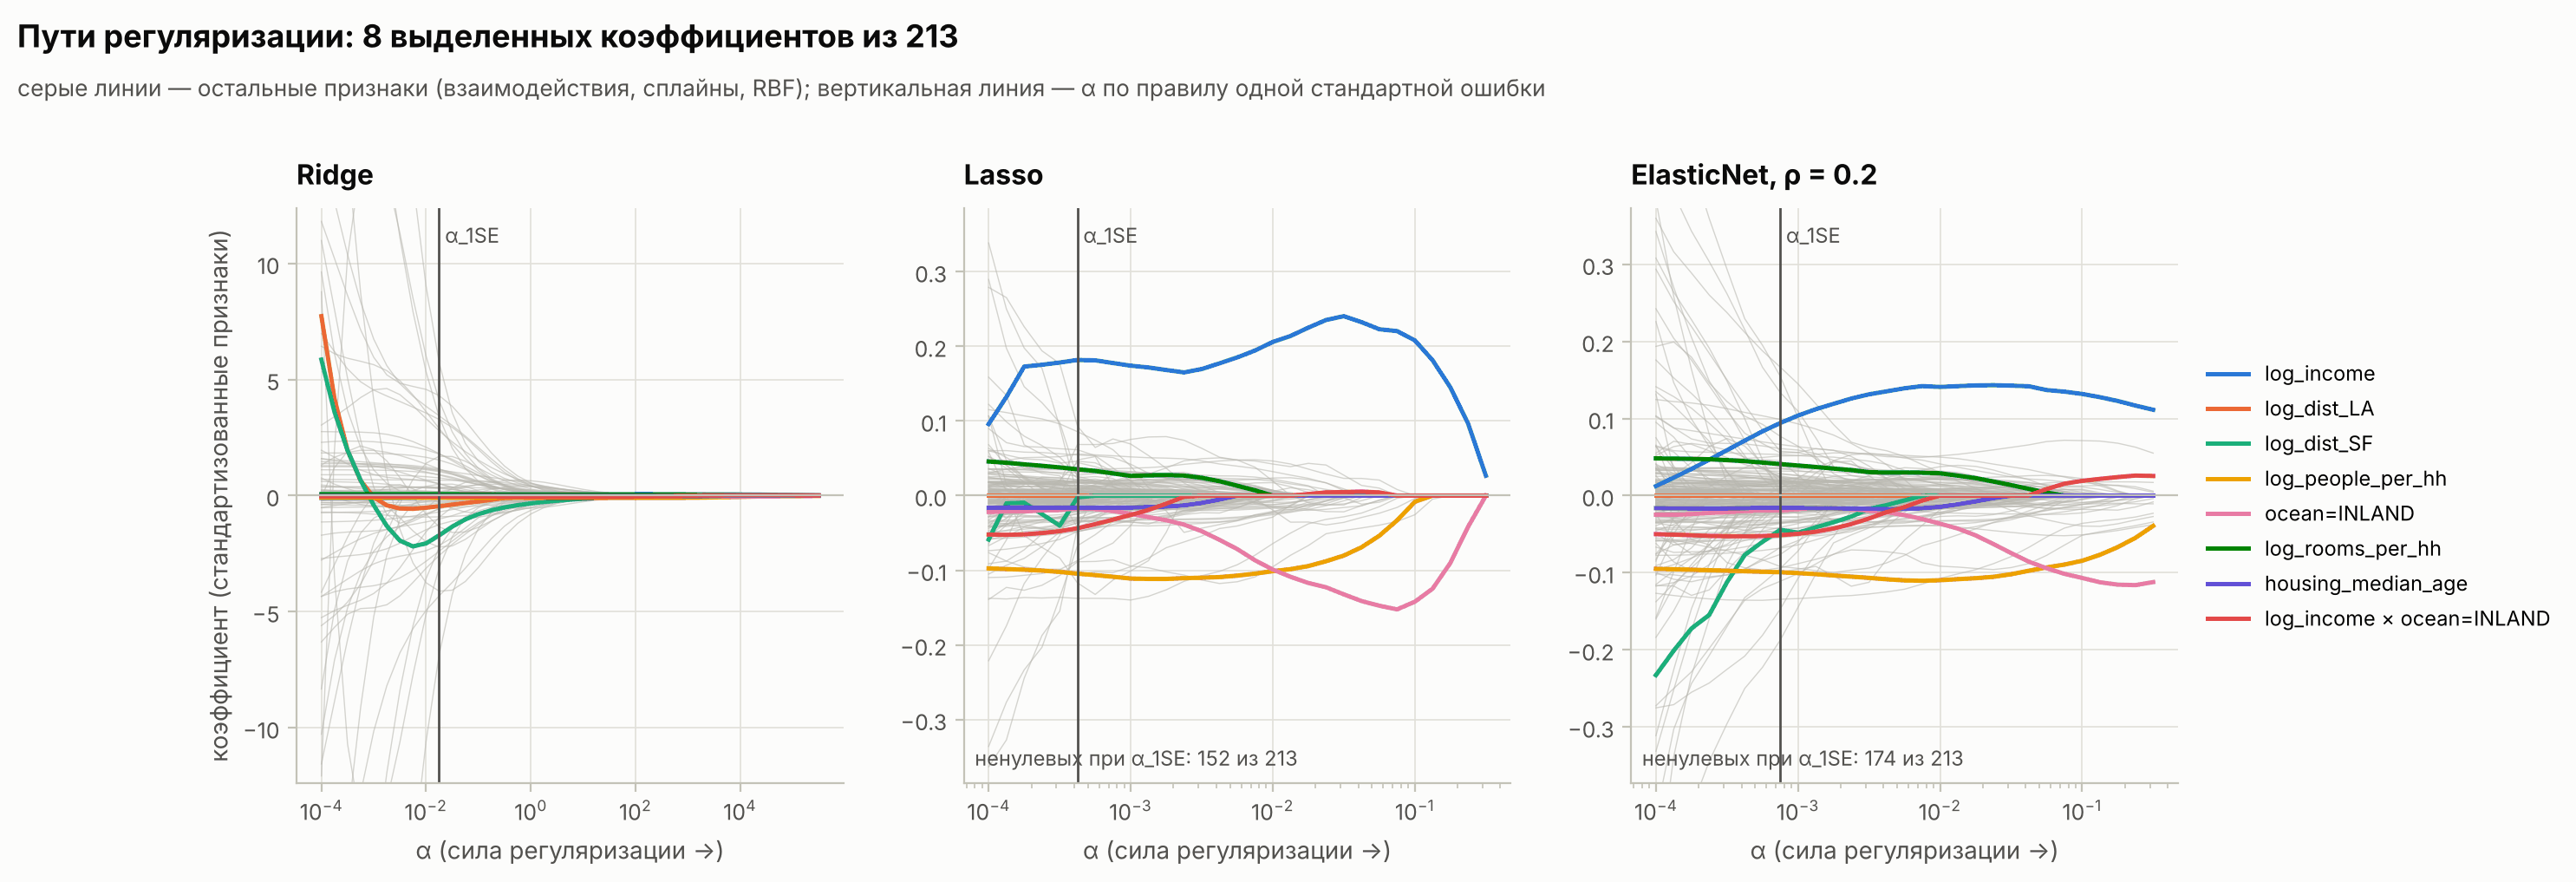

In [36]:
highlight = ["log_income", "log_dist_LA", "log_dist_SF", "log_people_per_hh", "ocean=INLAND",
             "log_rooms_per_hh", "housing_median_age", "log_income × ocean=INLAND"]
hl_idx = [int(np.where(ext_names == h)[0][0]) for h in highlight]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)  # учтены в счётчике выше; на выбранных α сходимость есть
    paths = {
        "Ridge": (ridge_alphas, ridge_path(Xe_train, ly_train, ridge_alphas), cv_ridge["alpha_1se"]),
        "Lasso": (l1_alphas, l1_path(Xe_train, ly_train, l1_alphas, 1.0), cv_lasso["alpha_1se"]),
        f"ElasticNet, ρ = {best_ratio}": (l1_alphas, l1_path(Xe_train, ly_train, l1_alphas, best_ratio), cv_en["alpha_1se"]),
    }
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), gridspec_kw={"wspace": 0.22})
for ax, (name, (alphas, W, a_best)) in zip(axes, paths.items()):
    ax.plot(alphas, W.T, color=NEUTRAL, lw=0.5, alpha=0.6)
    for j, (idx, col) in enumerate(zip(hl_idx, PALETTE)):
        ax.plot(alphas, W[idx], color=col, lw=1.8, label=highlight[j])
    ax.axvline(a_best, color=INK2, lw=1)
    ax.axhline(0, color=BASELINE, lw=0.8)
    lim = np.abs(W[hl_idx]).max() * 1.6
    ax.set(xscale="log", title=name, xlabel="α (сила регуляризации →)", ylim=(-lim, lim))
    ax.text(a_best, lim * 0.95, " α_1SE", fontsize=8.5, color=INK2, va="top")
    nnz = (np.abs(W) > 1e-10).sum(0)
    if name != "Ridge":
        ax2_text = f"ненулевых при α_1SE: {nnz[np.argmin(np.abs(alphas - a_best))]} из {W.shape[0]}"
        ax.text(0.02, 0.03, ax2_text, transform=ax.transAxes, fontsize=8.5, color=INK2)
axes[0].set_ylabel("коэффициент (стандартизованные признаки)")
axes[2].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8.5)
suptitle(fig, "Пути регуляризации: 8 выделенных коэффициентов из 213",
         "серые линии — остальные признаки (взаимодействия, сплайны, RBF); вертикальная линия — α по правилу одной стандартной ошибки")
plt.show()

При α = 10⁻⁴ коэффициенты при расстояниях до LA и SF равны 6–8 (у МНК — десятки) и компенсируют друг друга. Lasso при α_1SE оставляет 152 признака из 213; по мере обнуления взаимодействий их вклад переходит в основные эффекты (`log_income`, `ocean=INLAND`).

### 8.3. Кривые валидации

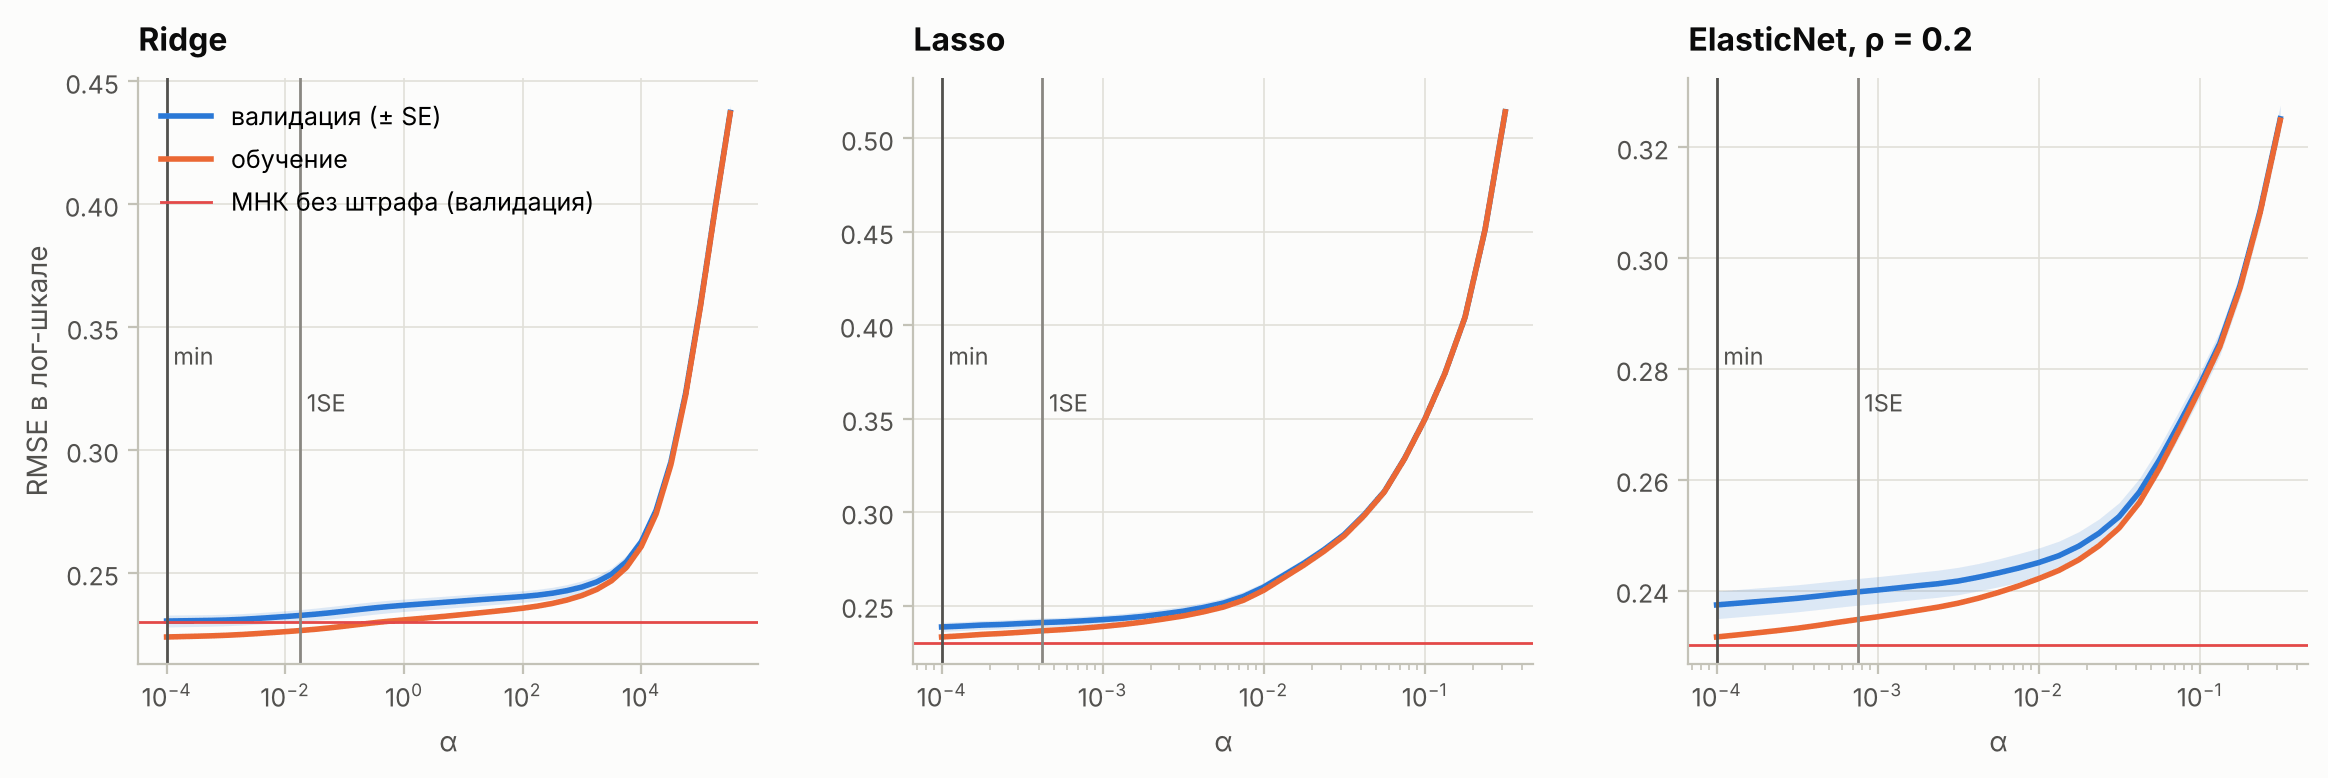

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"wspace": 0.25})
for ax, (name, cv) in zip(axes, [("Ridge", cv_ridge), ("Lasso", cv_lasso), (f"ElasticNet, ρ = {best_ratio}", cv_en)]):
    a = cv["alphas"]
    ax.fill_between(a, cv["val"] - cv["val_se"], cv["val"] + cv["val_se"], color=C["blue"], alpha=0.15, lw=0)
    ax.plot(a, cv["val"], color=C["blue"], lw=2, label="валидация (± SE)")
    ax.plot(a, cv["train"], color=C["orange"], lw=2, label="обучение")
    ax.axhline(cv_ols["val"][0], color=C["red"], lw=1, label="МНК без штрафа (валидация)")
    ax.axvline(cv["alpha_min"], color=INK2, lw=1)
    ax.axvline(cv["alpha_1se"], color=MUTED, lw=1)
    ax.text(cv["alpha_min"], 0.55, " min", fontsize=8.5, color=INK2, va="top", transform=ax.get_xaxis_transform())
    ax.text(cv["alpha_1se"], 0.47, " 1SE", fontsize=8.5, color=INK2, va="top", transform=ax.get_xaxis_transform())
    ax.set(xscale="log", title=name, xlabel="α")
axes[0].set_ylabel("RMSE в лог-шкале")
axes[0].legend(loc="upper left")
plt.show()

Разрыв между обучением и валидацией около 0,005 RMSE; с ростом α обе ошибки растут вместе.

### 8.4. Малые выборки

Подвыборки обучающей части первого фолда, оценка на его валидационной части, 3–5 повторов. Признаки фиксированы и построены без таргета.

Кривые обучения: 23.2 с; предупреждений о несходимости: 1


модель,Lasso (α по 3-fold CV),Ridge (α по 3-fold CV),МНК
n,,,
300,0.2920,0.2930,"6,730.2100"
600,0.2760,0.2770,2.6300
1200,0.2640,0.2650,1.7060
2500,0.2600,0.2560,0.2570
5000,0.2520,0.2430,0.2410
12592,0.2490,0.2390,0.2390


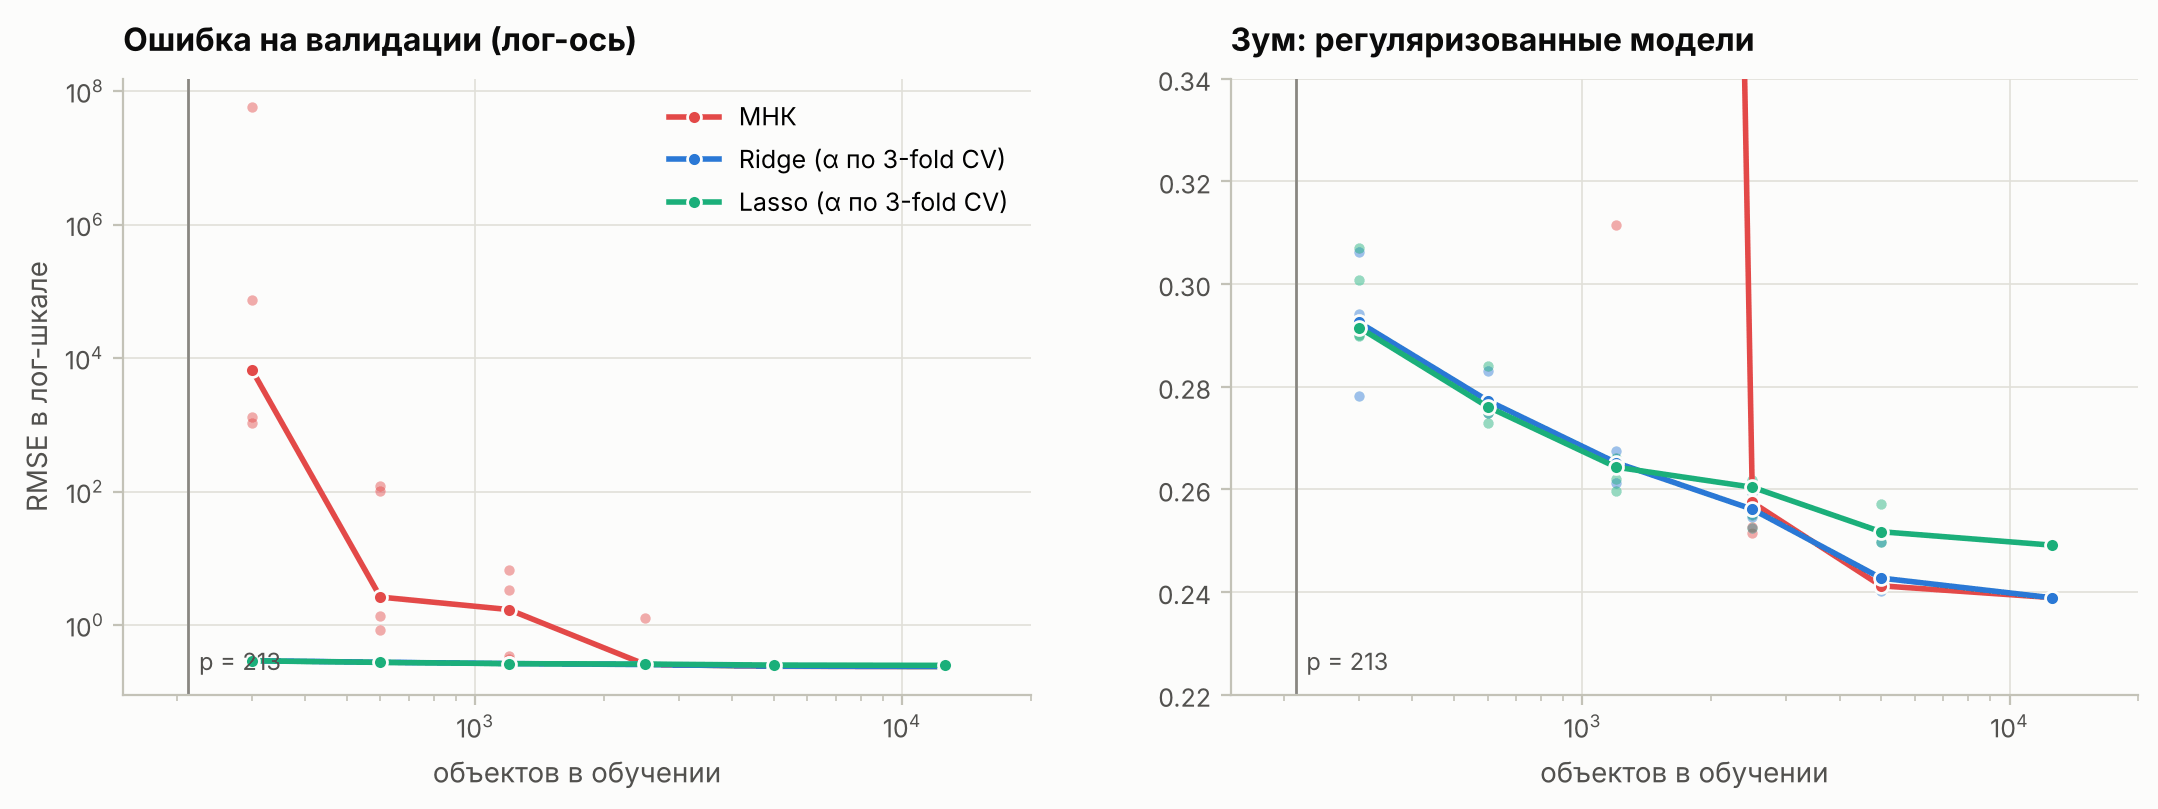

In [38]:
def ridge_kfold_predict(Xs, ys, Xv, alphas, k=3):
    """Ridge: α по k-кратной CV (вся сетка α — через одно спектральное разложение на фолд),
    затем обучение на всей подвыборке и прогноз для Xv."""
    def path_predict(Xa, ya, Xb):
        mu = Xa.mean(0)
        evals, V = np.linalg.eigh((Xa - mu).T @ (Xa - mu))
        Xty = V.T @ ((Xa - mu).T @ (ya - ya.mean()))
        W = np.stack([V @ (Xty / (evals + a)) for a in alphas], axis=1)
        return ya.mean() + (Xb - mu) @ W
    err = np.zeros(len(alphas))
    for tr, va in KFold(k, shuffle=True, random_state=SEED).split(Xs):
        err += np.mean((ys[va][:, None] - path_predict(Xs[tr], ys[tr], Xs[va])) ** 2, axis=0)
    return path_predict(Xs, ys, Xv)[:, int(np.argmin(err))]


f0 = ext_folds[0]
sizes = [300, 600, 1200, 2500, 5000, len(f0["ytr"])]
lc_rows = []
rs = np.random.default_rng(SEED)
t0 = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    for n_sub in sizes:
        for rep in range(1 if n_sub == len(f0["ytr"]) else 5 if n_sub <= 2500 else 3):
            idx = rs.choice(len(f0["ytr"]), n_sub, replace=False)
            Xs, ys = f0["Xtr"][idx], f0["ytr"][idx]
            b_ols = np.linalg.lstsq(np.column_stack([np.ones(n_sub), Xs]), ys, rcond=None)[0]
            lasso = LassoCV(alphas=np.logspace(-3.5, -1, 11), cv=3, max_iter=20_000).fit(Xs, ys)
            for name, pred in [("МНК", b_ols[0] + f0["Xva"] @ b_ols[1:]),
                               ("Ridge (α по 3-fold CV)", ridge_kfold_predict(Xs, ys, f0["Xva"], ridge_alphas)),
                               ("Lasso (α по 3-fold CV)", lasso.predict(f0["Xva"]))]:
                lc_rows.append({"n": n_sub, "модель": name, "rmse": np.sqrt(np.mean((f0["yva"] - pred) ** 2))})
lc = pd.DataFrame(lc_rows)
print(f"Кривые обучения: {time.time() - t0:.1f} с; предупреждений о несходимости: "
      f"{sum(issubclass(w.category, ConvergenceWarning) for w in caught)}")
lc_med = lc.groupby(["модель", "n"])["rmse"].median().unstack(0)
display(lc_med.round(3))

lc_colors = {"МНК": C["red"], "Ridge (α по 3-fold CV)": C["blue"], "Lasso (α по 3-fold CV)": C["aqua"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"wspace": 0.22})
for ax, zoom in zip(axes, [False, True]):
    for name, col in lc_colors.items():
        sub = lc[lc["модель"] == name]
        ax.scatter(sub["n"], sub["rmse"], color=col, s=14, alpha=0.45, lw=0)
        ax.plot(lc_med.index, lc_med[name], "-o", color=col, lw=2, ms=5, label=name, markeredgecolor=SURFACE)
    ax.axvline(Xe_train.shape[1], color=MUTED, lw=1)
    ax.set(xscale="log", xlabel="объектов в обучении", xlim=(150, 2e4))
    ax.text(Xe_train.shape[1] * 1.06, 0.04, f"p = {Xe_train.shape[1]}", fontsize=8.5, color=INK2,
            transform=ax.get_xaxis_transform())
axes[0].set(yscale="log", title="Ошибка на валидации (лог-ось)", ylabel="RMSE в лог-шкале")
axes[1].set(ylim=(0.22, 0.34), title="Зум: регуляризованные модели")
axes[0].legend(loc="upper right")
plt.show()

При n = 300 МНК почти интерполирует данные: медианный RMSE в лог-шкале около 6 700 против 0,29 у Ridge и Lasso. МНК догоняет регуляризованные модели с n ≈ 2 500, около 12 объектов на параметр. При сегментации портфеля (новый регион, редкий тип залога) объём данных на модель именно такого порядка, поэтому регуляризация остаётся в модели по умолчанию.

### 8.5. Стабильность коэффициентов

Бутстреп (60 выборок) для МНК и Ridge (α_1SE); для Lasso — частота отбора признака на 20 половинах выборки.

In [39]:
t0 = time.time()
B = 60
rs = np.random.default_rng(SEED)
Xc_full = np.column_stack([np.ones(len(Xe_train)), Xe_train])
coef_ols, coef_ridge = np.empty((B, Xe_train.shape[1])), np.empty((B, Xe_train.shape[1]))
for b in range(B):
    idx = rs.integers(0, len(ly_train), len(ly_train))
    coef_ols[b] = np.linalg.lstsq(Xc_full[idx], ly_train[idx], rcond=None)[0][1:]
    coef_ridge[b] = Ridge(alpha=cv_ridge["alpha_1se"], solver="cholesky").fit(Xe_train[idx], ly_train[idx]).coef_
sd_ratio = coef_ols.std(0) / coef_ridge.std(0)

sel = np.empty((20, Xe_train.shape[1]), dtype=bool)
for b in range(20):
    idx = rs.choice(len(ly_train), len(ly_train) // 2, replace=False)
    sel[b] = Lasso(alpha=cv_lasso["alpha_1se"], max_iter=50_000, precompute=True).fit(Xe_train[idx], ly_train[idx]).coef_ != 0
freq = sel.mean(0)
print(f"Бутстреп: {time.time() - t0:.1f} с")
print(f"SD(МНК) / SD(Ridge) по 213 коэффициентам: медиана {np.median(sd_ratio):.1f}, "
      f"максимум {sd_ratio.max():.0f}; у {np.mean(sd_ratio > 1):.0%} коэффициентов разброс МНК больше")
print(f"Lasso: признаков, отобранных всегда (100%): {(freq == 1).sum()}, никогда: {(freq == 0).sum()}, "
      f"нестабильных (от 10% до 90%): {((freq > 0.1) & (freq < 0.9)).sum()}")

Бутстреп: 15.7 с
SD(МНК) / SD(Ridge) по 213 коэффициентам: медиана 1.1, максимум 126; у 80% коэффициентов разброс МНК больше
Lasso: признаков, отобранных всегда (100%): 74, никогда: 23, нестабильных (от 10% до 90%): 70


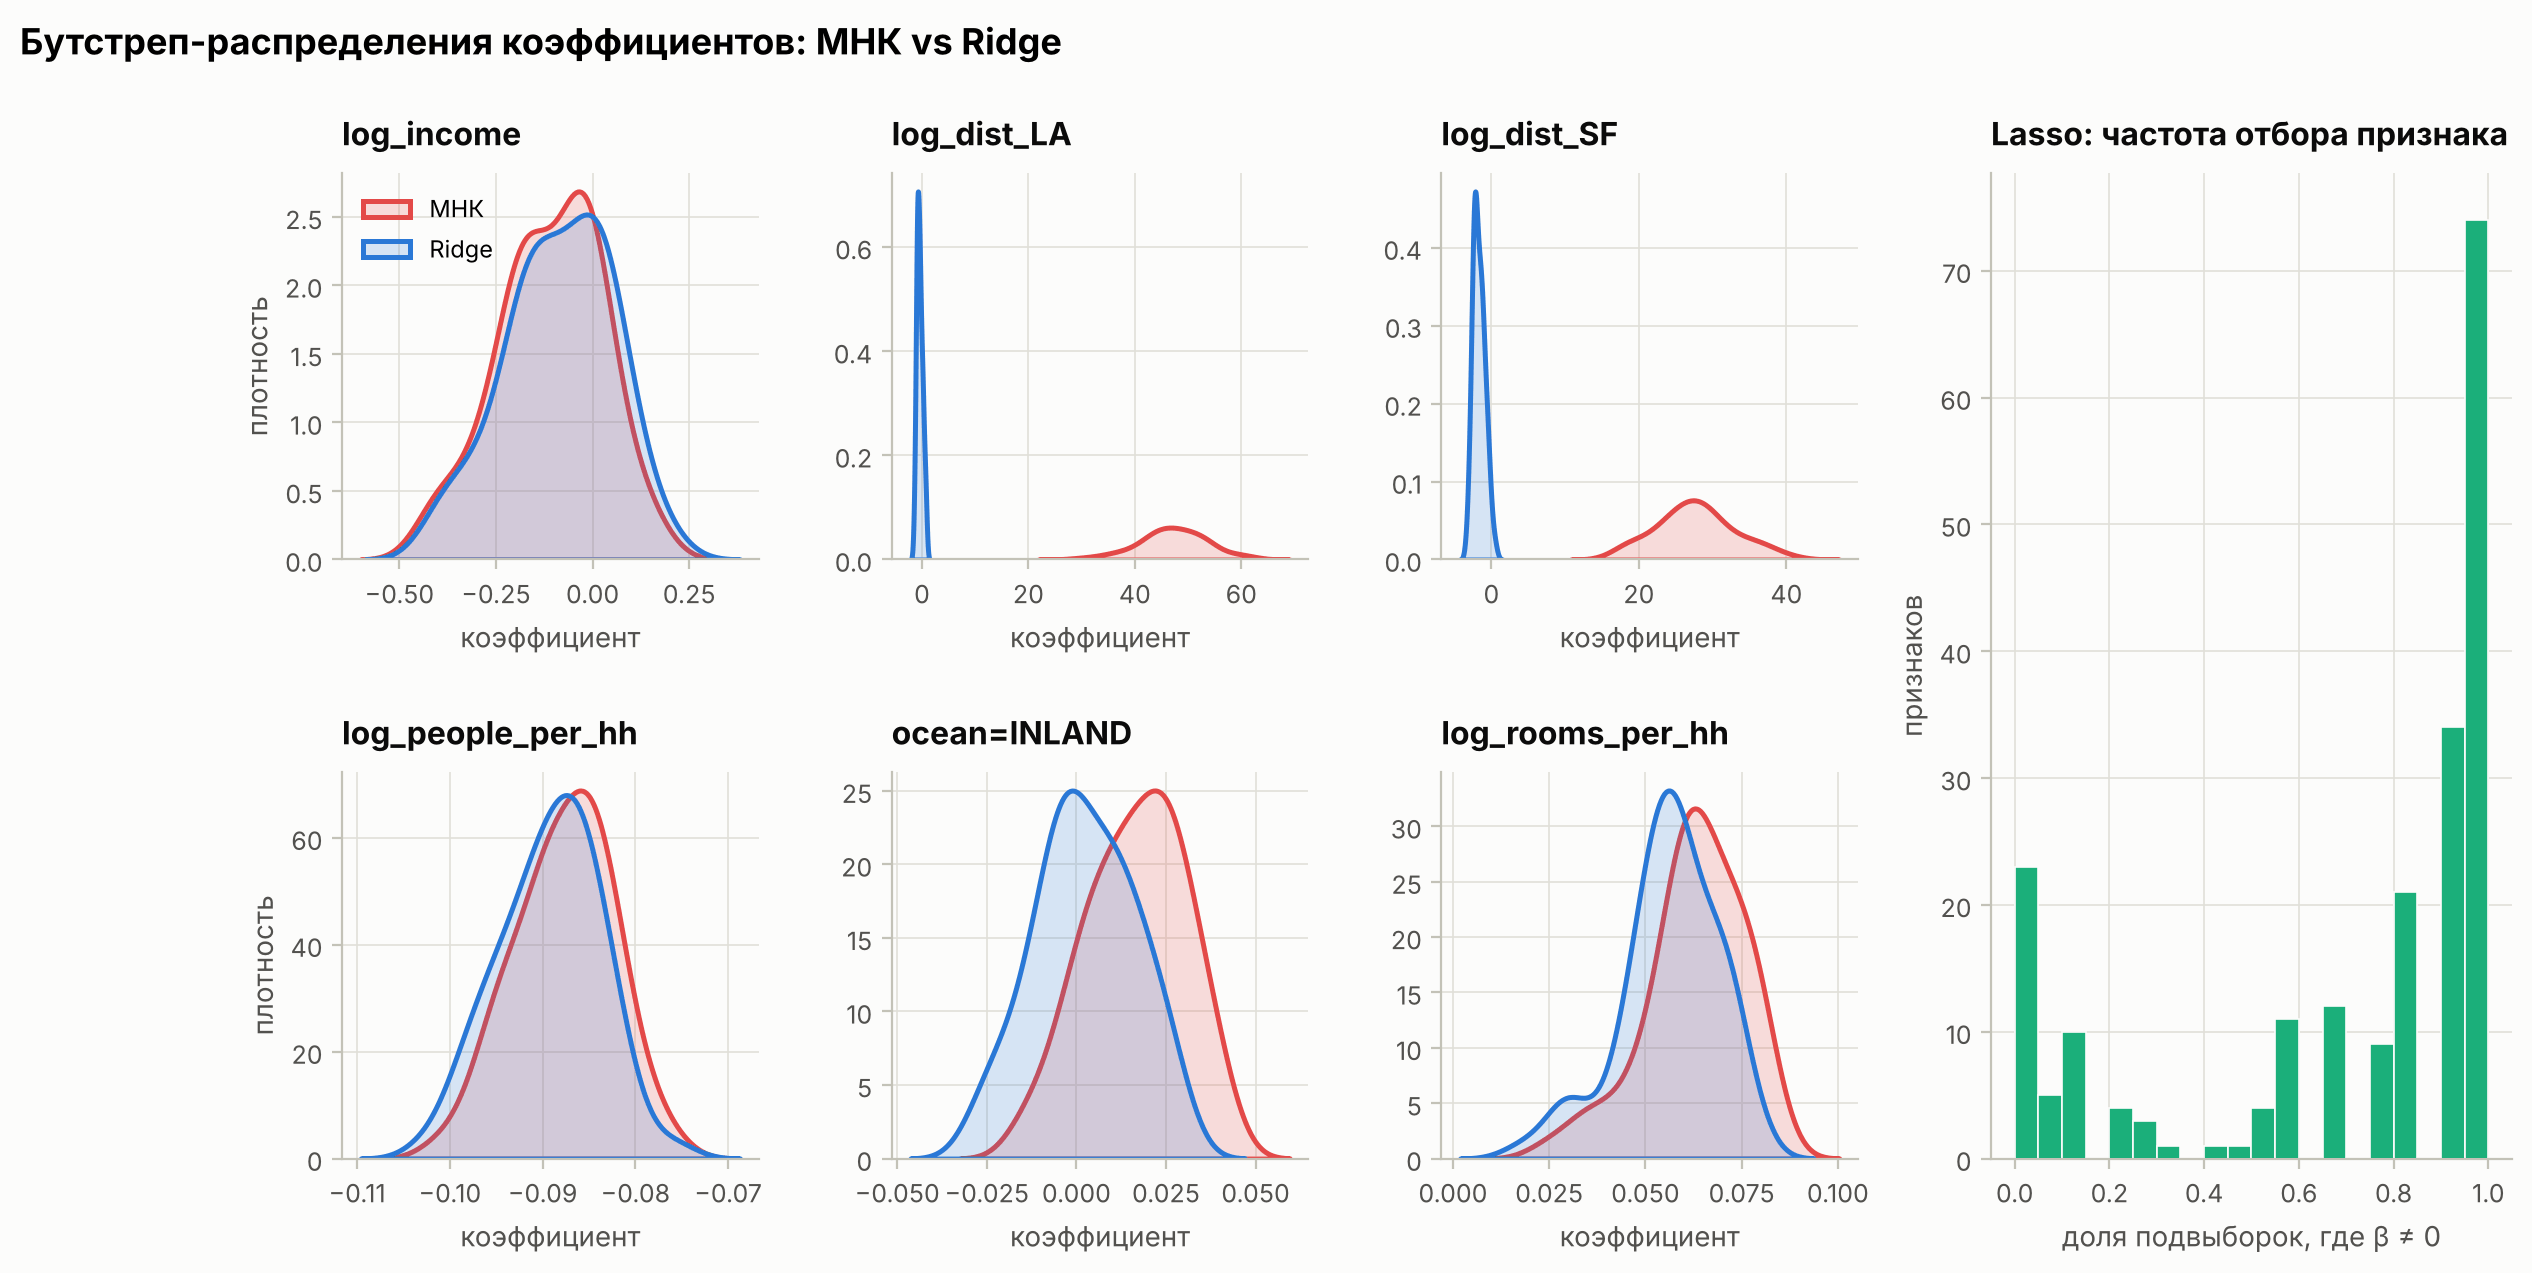

In [40]:
fig = plt.figure(figsize=(14, 6.4))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.25], wspace=0.3, hspace=0.55)
show = hl_idx[:6]
for k, idx in enumerate(show):
    ax = fig.add_subplot(gs[k // 3, k % 3])
    for coefs, col, label in [(coef_ols[:, idx], C["red"], "МНК"), (coef_ridge[:, idx], C["blue"], "Ridge")]:
        sns.kdeplot(coefs, ax=ax, color=col, fill=True, alpha=0.18, lw=1.8, label=label, warn_singular=False)
    ax.set(title=ext_names[idx], xlabel="коэффициент", ylabel="плотность" if k % 3 == 0 else "")
    ax.title.set_fontsize(10)
    if k == 0:
        ax.legend(loc="upper left", fontsize=8.5)
ax = fig.add_subplot(gs[:, 3])
ax.hist(freq, bins=np.linspace(0, 1, 21), color=C["aqua"], edgecolor=SURFACE, linewidth=0.6)
ax.set(title="Lasso: частота отбора признака", xlabel="доля подвыборок, где β ≠ 0", ylabel="признаков")
fig.suptitle("Бутстреп-распределения коэффициентов: МНК vs Ridge", x=0.01, ha="left", y=1.0)
plt.show()

Медианное отношение SD(МНК) / SD(Ridge) 1,1, максимум 126: коэффициенты МНК при расстояниях до LA и SF центрированы около 45 и 28, у Ridge около нуля. Lasso отбирает 74 признака всегда, 23 никогда, 70 — в 10–90% подвыборок; для выводов о факторах такой отбор не годится, для них используется M2.

### 8.6. Абляция винзоризации

In [41]:
t0 = time.time()
folds_nw = []
for tr_idx, va_idx in CV.split(train_df):
    pre_f = make_extended_preprocessor(winsorize=False).fit(train_df.iloc[tr_idx])
    folds_nw.append({"Xtr": pre_f.transform(train_df.iloc[tr_idx]), "ytr": ly_train[tr_idx],
                     "Xva": pre_f.transform(train_df.iloc[va_idx]), "yva": ly_train[va_idx], "va": va_idx})
abl = {}
for name, folds in [("с винзоризацией", ext_folds), ("без винзоризации", folds_nw)]:
    for model, fn in [("МНК", lambda X, y, a: ridge_path(X, y, [1e-10])), ("Ridge α_1SE", lambda X, y, a: ridge_path(X, y, [cv_ridge["alpha_1se"]]))]:
        oof = np.exp(cv_curve(fn, [0.0], folds)["oof"][:, 0])
        ape = np.abs(oof - y_train) / y_train
        abl[(model, name)] = {"MAPE, %": 100 * ape.mean(), "MdAPE, %": 100 * np.median(ape),
                              "max APE, %": 100 * ape.max(), "объектов с APE > 100%": int((ape > 1).sum())}
print(f"Абляция: {time.time() - t0:.1f} с")
pd.DataFrame(abl).T

Абляция: 2.1 с


,,"MAPE, %","MdAPE, %","max APE, %",объектов с APE > 100%
МНК,с винзоризацией,16.8404,12.2464,"1,082.5689",104.0000
Ridge α_1SE,с винзоризацией,17.1275,12.4165,"1,086.7059",106.0000
МНК,без винзоризации,17.1463,12.4940,"1,041.5388",116.0000
Ridge α_1SE,без винзоризации,17.4307,12.6250,"1,034.2312",115.0000


Винзоризация снижает MAPE на 0,3 п. п. и число объектов с ошибкой больше 100% со 116 до 104.

В сравнение (раздел 11) идут МНК (M3), Ridge (M4), Lasso (M5) и ElasticNet (M6) на расширенном пространстве, α по 1SE.

## 9. GD и SGD

$f(w)=\frac1n\lVert y-\tilde Xw\rVert^2$, $H=\frac2n\tilde X^\top\tilde X$, $L=\lambda_{\max}(H)$, $\mu=\lambda_{\min}(H)$, $\kappa=L/\mu$. GD сходится при $0<\eta<2/L$; при $\eta=1/L$ $f(w_t)-f^*\le(1-1/\kappa)^t(f(w_0)-f^*)$. SGD с постоянным шагом выходит на плато $\mathsf E f(w_t)-f^*=O(\eta)$. Эксперименты — на пространстве M2 (16 признаков), где известно точное решение.

In [42]:
class GDLinearRegression(RegressorMixin, BaseEstimator):
    """Линейная регрессия (MSE + опционально L2-штраф), обучаемая градиентным спуском.

    method        : 'gd' — полный градиент, 'sgd' — мини-батчи размера batch_size
    learning_rate : шаг η (для schedule='invscaling' — начальный шаг η₀)
    schedule      : 'constant' или 'invscaling' (η_t = η₀ / (1 + t / decay_steps))
    max_iter, tol : останов по числу итераций или по изменению функционала < tol
    record_every  : как часто записывать полный функционал в history_ (время записи не учитывается)
    """

    def __init__(self, method="gd", learning_rate=0.1, batch_size=64, max_iter=1000, tol=0.0, l2=0.0,
                 schedule="constant", decay_steps=1000, record_every=1, random_state=SEED):
        self.method, self.learning_rate, self.batch_size = method, learning_rate, batch_size
        self.max_iter, self.tol, self.l2 = max_iter, tol, l2
        self.schedule, self.decay_steps, self.record_every, self.random_state = schedule, decay_steps, record_every, random_state

    def _loss(self, X, y, w):
        r = X @ w - y
        return r @ r / len(y) + self.l2 * (w[1:] @ w[1:])

    def fit(self, X, y):
        X = np.column_stack([np.ones(len(X)), np.asarray(X, dtype=float)])
        y = np.asarray(y, dtype=float)
        n, k = X.shape
        rs = np.random.default_rng(self.random_state)
        w = np.zeros(k)
        history, train_time, prev = [(0, 0.0, self._loss(X, y, w))], 0.0, np.inf
        for it in range(1, self.max_iter + 1):
            t0 = time.perf_counter()
            if self.method == "gd":
                Xb, yb = X, y
            else:
                idx = rs.integers(0, n, self.batch_size)
                Xb, yb = X[idx], y[idx]
            grad = 2 * Xb.T @ (Xb @ w - yb) / len(yb)
            grad[1:] += 2 * self.l2 * w[1:]
            eta = self.learning_rate if self.schedule == "constant" else self.learning_rate / (1 + it / self.decay_steps)
            w = w - eta * grad
            train_time += time.perf_counter() - t0
            if it % self.record_every == 0 or it == self.max_iter:
                cur = self._loss(X, y, w)
                history.append((it, train_time, cur))
                if not np.isfinite(cur) or cur > 1e12:   # расходимость
                    break
                if self.tol and abs(prev - cur) < self.tol:
                    break
                prev = cur
        self.intercept_, self.coef_, self.n_iter_ = w[0], w[1:], it
        self.history_ = pd.DataFrame(history, columns=["iter", "time", "loss"])
        self.history_["epoch"] = self.history_["iter"] * (n if self.method == "gd" else self.batch_size) / n
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

In [43]:
Z_scaled = StandardScaler().fit_transform(X2_train)
Z_raw = X2_train.to_numpy()


def curvature(Z):
    """L, μ и κ гессиана H = 2/n · X̃ᵀX̃ (с константой)."""
    Zt = np.column_stack([np.ones(len(Z)), Z])
    ev = np.linalg.eigvalsh(2 * Zt.T @ Zt / len(Z))
    return ev.max(), ev.min(), ev.max() / ev.min()


def optimum(Z, y):
    Zt = np.column_stack([np.ones(len(Z)), Z])
    w = np.linalg.lstsq(Zt, y, rcond=None)[0]
    return w, np.mean((Zt @ w - y) ** 2)


L_s, mu_s, kappa_s = curvature(Z_scaled)
L_r, mu_r, kappa_r = curvature(Z_raw)
w_star, f_star = optimum(Z_scaled, ly_train)
print(f"Стандартизованные признаки: L = {L_s:.2f}, μ = {mu_s:.4f}, κ = {kappa_s:,.0f};  "
      f"исходные: L = {L_r:,.0f}, μ = {mu_r:.2e}, κ = {kappa_r:.2e}")

t0 = time.time()
runs = {
    "GD, η = 1/L": GDLinearRegression("gd", 1 / L_s, max_iter=600).fit(Z_scaled, ly_train),
    "SGD, η = 0.02": GDLinearRegression("sgd", 0.02, batch_size=64, max_iter=6000, record_every=25).fit(Z_scaled, ly_train),
    "SGD, η = 0.005": GDLinearRegression("sgd", 0.005, batch_size=64, max_iter=6000, record_every=25).fit(Z_scaled, ly_train),
    "SGD, η₀ = 0.05, убывающий": GDLinearRegression("sgd", 0.05, batch_size=64, max_iter=6000, record_every=25,
                                                    schedule="invscaling", decay_steps=300).fit(Z_scaled, ly_train),
}
print(f"Обучение: {time.time() - t0:.1f} с")
gd = runs["GD, η = 1/L"]
print(f"GD, η = 1/L: max |w − w*| = {np.max(np.abs(np.r_[gd.intercept_, gd.coef_] - w_star)):.1e} "
      f"после {gd.n_iter_} итераций; f − f* = {gd.history_['loss'].iloc[-1] - f_star:.1e}")

Стандартизованные признаки: L = 8.57, μ = 0.1378, κ = 62;  исходные: L = 2,242, μ = 8.19e-04, κ = 2.74e+06
Обучение: 0.6 с
GD, η = 1/L: max |w − w*| = 8.3e-06 после 600 итераций; f − f* = 6.7e-12


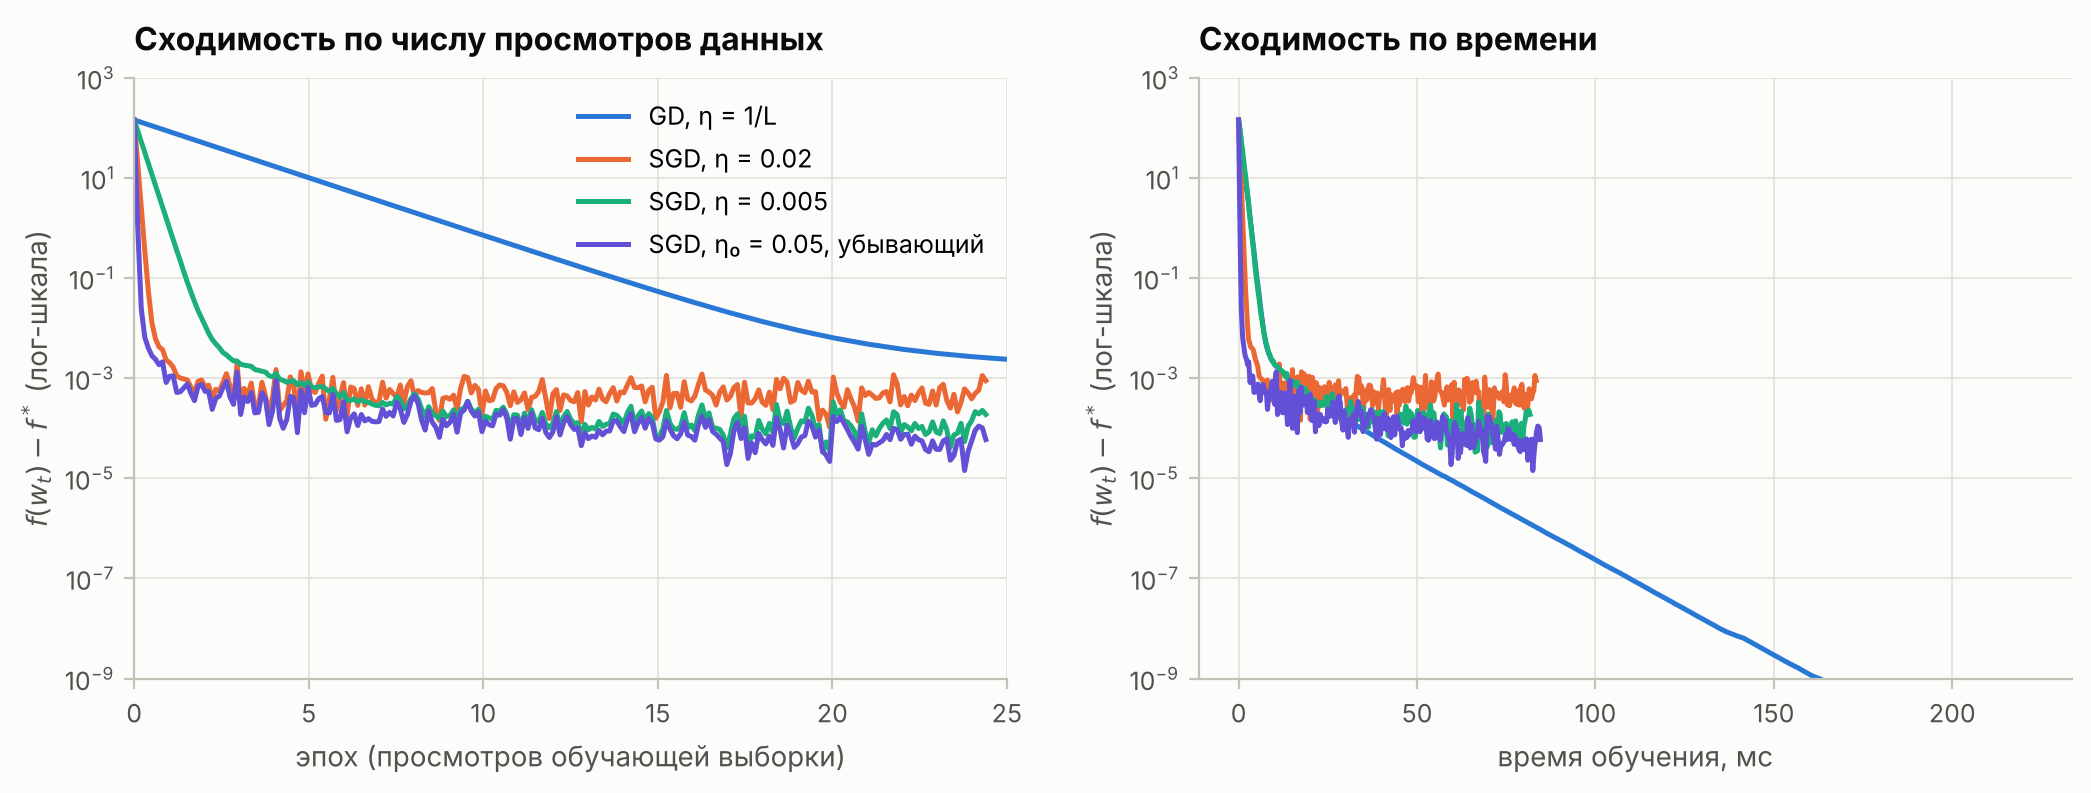

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"wspace": 0.22})
run_colors = dict(zip(runs, [C["blue"], C["orange"], C["aqua"], C["violet"]]))
for name, m in runs.items():
    h = m.history_
    gap = np.maximum(h["loss"] - f_star, 1e-16)
    axes[0].plot(h["epoch"], gap, color=run_colors[name], lw=1.8, label=name)
    axes[1].plot(h["time"] * 1000, gap, color=run_colors[name], lw=1.8, label=name)
for ax, xlabel in zip(axes, ["эпох (просмотров обучающей выборки)", "время обучения, мс"]):
    ax.set(yscale="log", xlabel=xlabel, ylabel=r"$f(w_t) - f^*$ (лог-шкала)", ylim=(1e-9, 1e3))
axes[0].set(title="Сходимость по числу просмотров данных", xlim=(0, 25))
axes[1].set(title="Сходимость по времени")
axes[0].legend(loc="upper right")
plt.show()

* GD, η = 1/L, 600 итераций: $\max|w-w^*|=8\cdot10^{-6}$.
* По эпохам SGD быстрее: $f-f^*\approx10^{-3}$ за 1–2 эпохи. С постоянным шагом плато около 5·10⁻⁴ при η = 0,02 и около 10⁻⁴ при η = 0,005; с убывающим шагом сходимость продолжается.
* По времени на 16 тыс. × 17 быстрее полный GD: машинная точность примерно за 200 мс.

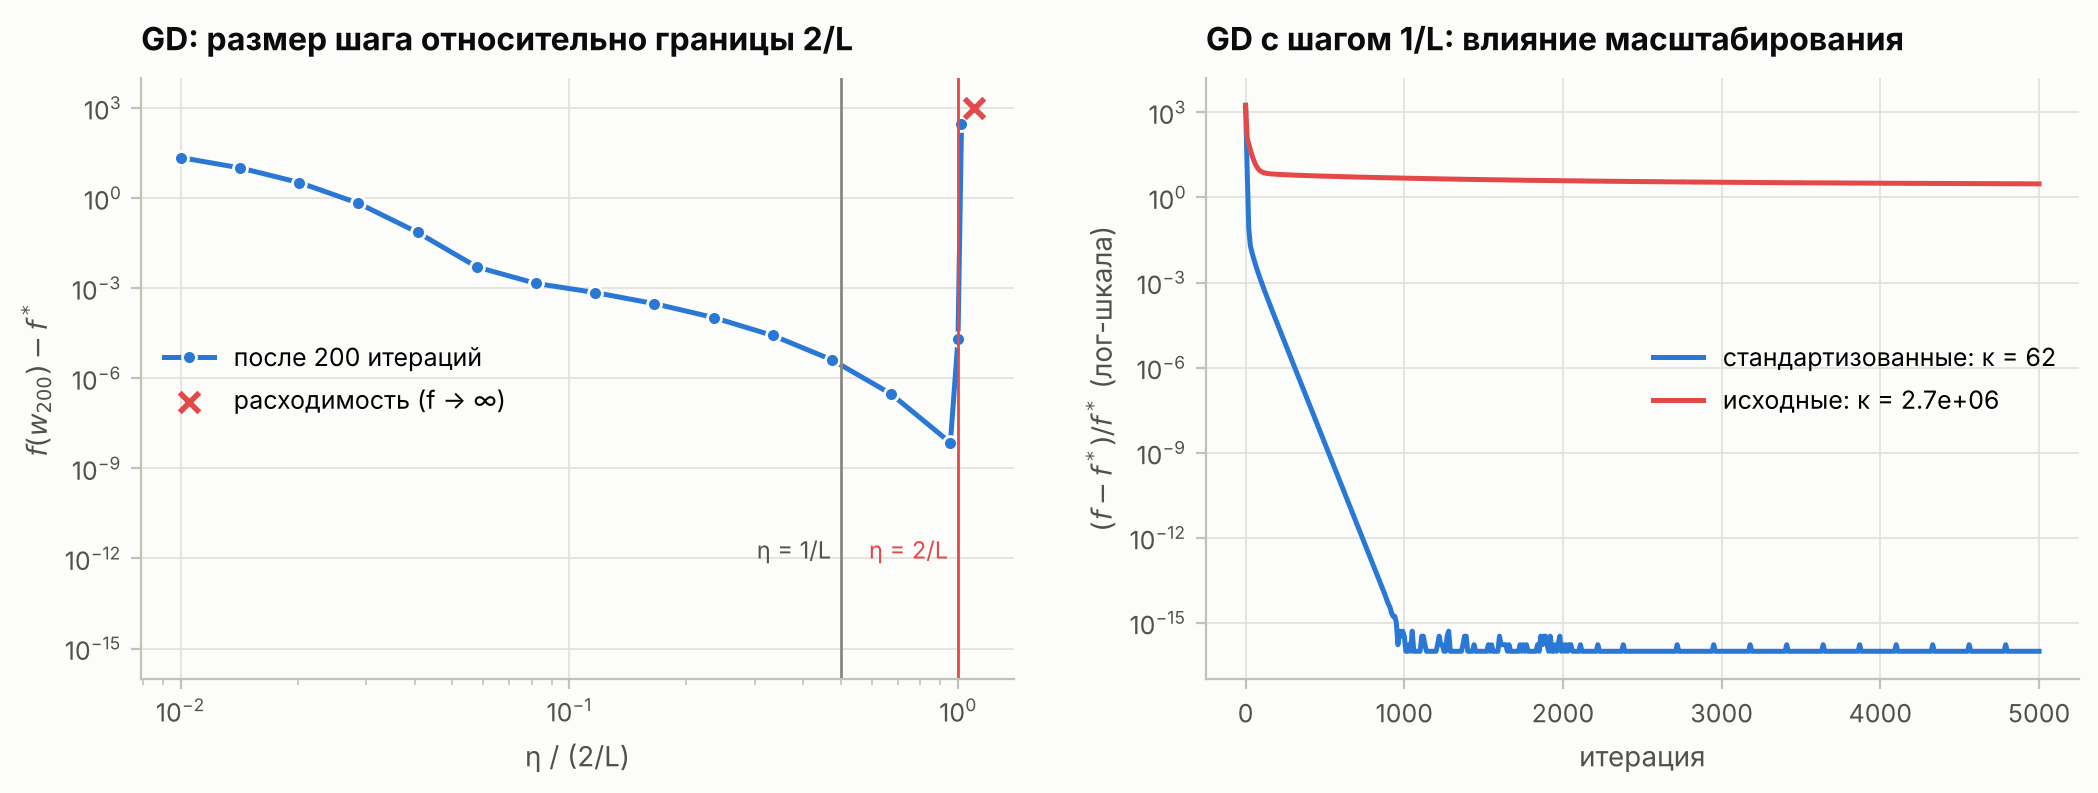

GD, шаг 1/L, 5 000 итераций: (f − f*)/f* = 1e-16 (стандартизованные), 3.03 (исходные)
f − f* после 200 итераций: 0.955·(2/L) → 7.2e-09 (минимум); 0.999·(2/L) → 2.0e-05; 1.02·(2/L) → 284; 1.1·(2/L) → расходимость за 104 итераций


In [45]:
# Размер шага: теоретическая граница устойчивости 2/L против эксперимента
ratios = np.r_[np.logspace(-2, -0.02, 14), 0.999, 1.02, 1.1]
lr_rows = []
for c in ratios:
    m = GDLinearRegression("gd", c * 2 / L_s, max_iter=200).fit(Z_scaled, ly_train)
    lr_rows.append({"η · L / 2": c, "f − f*": m.history_["loss"].iloc[-1] - f_star, "итераций": m.n_iter_})
lr_sweep = pd.DataFrame(lr_rows)

# Масштабирование: GD с шагом 1/L на исходных и стандартизованных признаках
w_star_raw, f_star_raw = optimum(Z_raw, ly_train)
gd_raw = GDLinearRegression("gd", 1 / L_r, max_iter=5000, record_every=10).fit(Z_raw, ly_train)
gd_scaled = GDLinearRegression("gd", 1 / L_s, max_iter=5000, record_every=10).fit(Z_scaled, ly_train)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"wspace": 0.22})
ax = axes[0]
ok = lr_sweep["итераций"] == 200
ax.plot(lr_sweep.loc[ok, "η · L / 2"], np.maximum(lr_sweep.loc[ok, "f − f*"], 1e-16), "-o", color=C["blue"], ms=5,
        lw=1.8, markeredgecolor=SURFACE, label="после 200 итераций")
ax.scatter(lr_sweep.loc[~ok, "η · L / 2"], np.full((~ok).sum(), 1e3), marker="x", color=C["red"], s=50, zorder=3,
           label="расходимость (f → ∞)")
ax.axvline(1, color=C["red"], lw=1)
ax.axvline(0.5, color=MUTED, lw=1)
ax.text(0.98, 1e-12, "η = 2/L ", ha="right", fontsize=8.5, color=C["red"])
ax.text(0.49, 1e-12, "η = 1/L ", ha="right", fontsize=8.5, color=INK2)
ax.set(xscale="log", yscale="log", title="GD: размер шага относительно границы 2/L", xlabel="η / (2/L)",
       ylabel=r"$f(w_{200}) - f^*$", ylim=(1e-16, 1e4))
ax.legend(loc="center left")

ax = axes[1]
for m, fs, name, col in [(gd_scaled, f_star, f"стандартизованные: κ = {kappa_s:,.0f}", C["blue"]),
                         (gd_raw, f_star_raw, f"исходные: κ = {kappa_r:.1e}", C["red"])]:
    h = m.history_
    ax.plot(h["iter"], np.maximum((h["loss"] - fs) / fs, 1e-16), color=col, lw=1.8, label=name)
ax.set(yscale="log", title="GD с шагом 1/L: влияние масштабирования", xlabel="итерация",
       ylabel=r"$(f - f^*)/f^*$ (лог-шкала)")
ax.legend(loc="center right")
plt.show()

gap_scaled = max((gd_scaled.history_["loss"].iloc[-1] - f_star) / f_star, 0.0)
gap_raw = (gd_raw.history_["loss"].iloc[-1] - f_star_raw) / f_star_raw
print(f"GD, шаг 1/L, 5 000 итераций: (f − f*)/f* = {max(gap_scaled, 1e-16):.0e} (стандартизованные), "
      f"{gap_raw:.2f} (исходные)")
r = lr_sweep.set_index("η · L / 2")
best = r["f − f*"].idxmin()
print(f"f − f* после 200 итераций: {best:.3f}·(2/L) → {r.loc[best, 'f − f*']:.1e} (минимум); "
      f"0.999·(2/L) → {r.loc[0.999, 'f − f*']:.1e}; 1.02·(2/L) → {r.loc[1.02, 'f − f*']:.0f}; "
      f"1.1·(2/L) → расходимость за {r.loc[1.1, 'итераций']} итераций")

* При 0,999·(2/L) GD сходится, при 1,02·(2/L) расходится: граница совпадает с теорией.
* Лучший шаг 0,96·(2/L), $f-f^*=7\cdot10^{-9}$ за 200 итераций; теоретический оптимум 2/(L + μ) = 0,98·(2/L).
* Без стандартизации κ = 2,7·10⁶ вместо 62. За 5 000 итераций $(f-f^*)/f^*=3{,}0$, а на стандартизованных признаках машинная точность достигается примерно за 1 000 итераций.

## 10. Интервалы и консервативная стоимость залога

90%-ные предсказательные интервалы (PI) для M2 в лог-шкале. Нижняя граница PI — консервативная стоимость залога.

| Метод | Интервал | Допущения |
|---|---|---|
| гомоскедастичный | $\hat y\pm z\sqrt{\hat\sigma^2+x^\top\hat Vx}$ | нормальный шум постоянной дисперсии |
| гетероскедастичный | $\hat y\pm z\sqrt{\hat\sigma^2(x)+x^\top\hat Vx}$ | нормальный шум, модель $\sigma^2(x)$ |
| квантильная регрессия | квантили 5% и 95%, pinball loss | линейность квантилей |
| конформный | $\hat y\pm\hat q\,\hat\sigma(x)$, $\hat q$ — квантиль $\lvert e\rvert/\hat\sigma$ на калибровке | exchangeability |

Модели обучаются на 80% обучающей выборки, остальные 20% — калибровка конформного метода, оценка — на тесте.

In [46]:
ALPHA = 0.10                      # 90%-ные интервалы → нижняя граница = квантиль 5%
Z_CRIT = stats.norm.ppf(1 - ALPHA / 2)

fit_idx, cal_idx = train_test_split(np.arange(len(train_df)), test_size=0.2, random_state=SEED)
pre_iv = make_interpretable_preprocessor().fit(train_df.iloc[fit_idx])
Xf, Xc, Xt = (pre_iv.transform(d) for d in (train_df.iloc[fit_idx], train_df.iloc[cal_idx], test_df))
yf, yc = ly_train[fit_idx], ly_train[cal_idx]

mean_model = OLS(cov_type="HC3").fit(Xf, yf)
print(f"Модель среднего: n = {mean_model.nobs_}, R² = {mean_model.rsquared_:.3f}, σ̂ = {np.sqrt(mean_model.sigma2_):.3f} (в лог-шкале)")

Модель среднего: n = 12592, R² = 0.714, σ̂ = 0.283 (в лог-шкале)


### 10.1. Модель дисперсии

$\log e^2=z^\top\gamma+v$, $\hat\sigma^2(x)=c\,e^{z^\top\hat\gamma}$, $c=\overline{e^2/e^{z^\top\hat\gamma}}$. Без множителя $c$ дисперсия занижена: для нормального шума $\mathsf E\log\xi^2=-1{,}27$, то есть $c=3{,}56$.

Модель дисперсии: R² = 0.042;  дисперсия её остатков = 4.95 (неустранимый шум log ξ² при нормальном ξ: π²/2 = 4.93);  калибровочный множитель c = 3.93 (3,56 при нормальности)
Тест Вальда «дисперсия не зависит от признаков»: F = 35.1, p-value = 1.3e-106


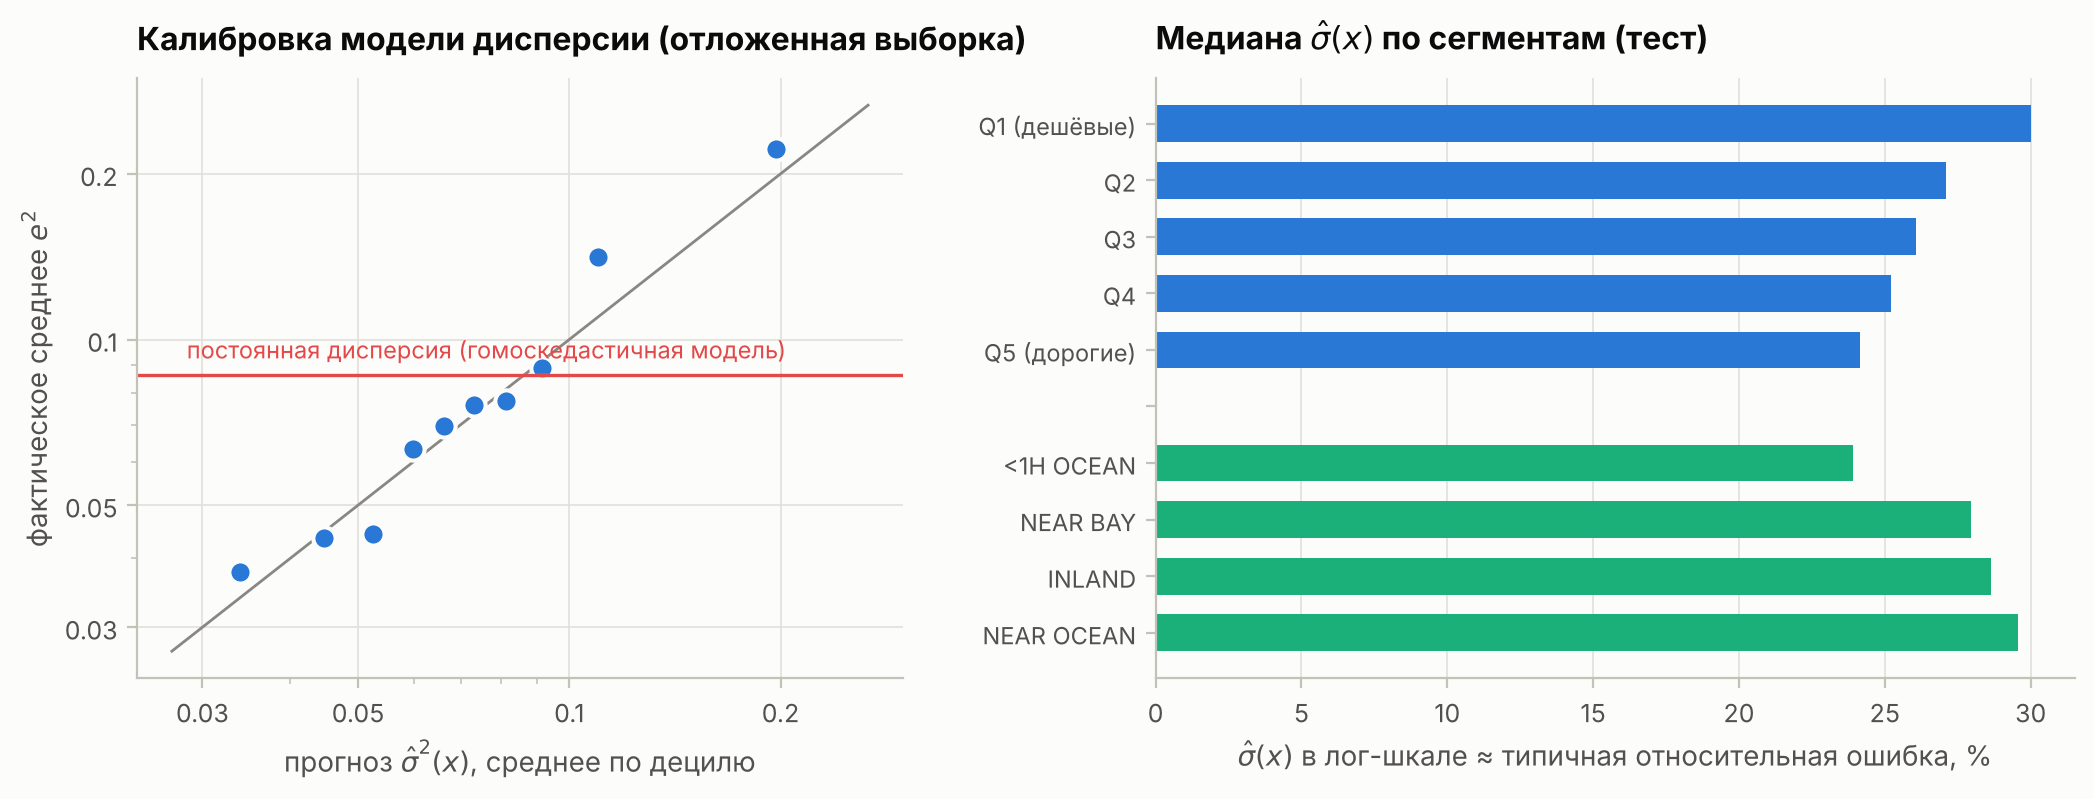

In [47]:
e_fit = mean_model.resid_
var_model = OLS(cov_type="HC3").fit(Xf, np.log(e_fit ** 2))
c_var = np.mean(e_fit ** 2 / np.exp(var_model.fittedvalues_))


def sigma2_hat(X):
    """Прогноз дисперсии шума (лог-шкала цены)."""
    return c_var * np.exp(var_model.predict(X))


print(f"Модель дисперсии: R² = {var_model.rsquared_:.3f};  дисперсия её остатков = {np.var(var_model.resid_):.2f} "
      f"(неустранимый шум log ξ² при нормальном ξ: π²/2 = {np.pi ** 2 / 2:.2f});  калибровочный множитель c = {c_var:.2f} (3,56 при нормальности)")
w_var = var_model.wald_test(var_model.param_names_[1:])
print(f"Тест Вальда «дисперсия не зависит от признаков»: F = {w_var['F']:.1f}, p-value = {w_var['p_value']:.1e}")

pred_c = mean_model.predict(Xc)
e_cal = yc - pred_c
s2_cal = sigma2_hat(Xc)
calib = pd.DataFrame({"s2": s2_cal, "e2": e_cal ** 2, "bin": pd.qcut(s2_cal, 10, labels=False)}).groupby("bin").mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"wspace": 0.3, "width_ratios": [1, 1.2]})
ax = axes[0]
lim = [calib.min().min() * 0.8, calib.max().max() * 1.2]
ax.plot(lim, lim, color=MUTED, lw=1)
ax.plot(calib["s2"], calib["e2"], "o", color=C["blue"], ms=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(e_cal.var(), color=C["red"], lw=1.2)
ax.text(lim[0] * 1.05, e_cal.var() * 1.07, "постоянная дисперсия (гомоскедастичная модель)", color=C["red"], fontsize=8.5)
ax.set(xscale="log", yscale="log", title="Калибровка модели дисперсии (отложенная выборка)",
       xlabel=r"прогноз $\hat\sigma^2(x)$, среднее по децилю", ylabel=r"фактическое среднее $e^2$")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(mpl.ticker.FixedLocator([0.03, 0.05, 0.1, 0.2]))
    axis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v:g}"))
    axis.set_minor_formatter(mpl.ticker.NullFormatter())

ax = axes[1]
seg = pd.DataFrame({"sigma, %": 100 * np.sqrt(sigma2_hat(Xt)), "ocean": test_df["ocean_proximity"].values,
                    "квинтиль цены": pd.qcut(np.exp(mean_model.predict(Xt)), 5, labels=["Q1 (дешёвые)", "Q2", "Q3", "Q4", "Q5 (дорогие)"])})
by_ocean = seg.groupby("ocean")["sigma, %"].median().sort_values()
by_price = seg.groupby("квинтиль цены", observed=True)["sigma, %"].median()
labels = list(by_price.index) + [""] + list(by_ocean.index)
vals = list(by_price.values) + [np.nan] + list(by_ocean.values)
cols = [C["blue"]] * len(by_price) + [SURFACE] + [C["aqua"]] * len(by_ocean)
ax.barh(range(len(vals)), vals, color=cols, height=0.65)
ax.set_yticks(range(len(vals)), labels, fontsize=8.5)
ax.invert_yaxis()
ax.set(title=r"Медиана $\hat\sigma(x)$ по сегментам (тест)",
       xlabel=r"$\hat\sigma(x)$ в лог-шкале ≈ типичная относительная ошибка, %")
ax.grid(axis="y", visible=False)
plt.show()

* Дисперсия зависит от признаков: тест Вальда F = 35, p ≈ 10⁻¹⁰⁶.
* На отложенной выборке средний $e^2$ по децилям прогноза меняется от 0,04 до 0,22 и лежит на диагонали; постоянная дисперсия ошибается в 2–2,5 раза.
* $R^2=0{,}04$ ожидаем: дисперсия остатков вспомогательной регрессии 4,95 при неустранимом шуме $\pi^2/2=4{,}93$. $c=3{,}93$.
* Неопределённость выше у дешёвых объектов ($\hat\sigma$ около 30% против 24% у дорогих) и вне `<1H OCEAN` (28–30% против 24%).

### 10.2. Сравнение интервалов на тесте

In [48]:
t0 = time.time()
qr_models = {q: QuantileRegressor(quantile=q, alpha=0.0, solver="highs").fit(Xf, yf) for q in (ALPHA / 2, 1 - ALPHA / 2)}
print(f"Квантильная регрессия: {time.time() - t0:.1f} с")

# Нормированный split-conformal: квантиль |e|/σ̂ на калибровочной выборке
scores = np.abs(e_cal) / np.sqrt(s2_cal)
n_cal = len(scores)
q_level = np.ceil((n_cal + 1) * (1 - ALPHA)) / n_cal
q_conf = np.quantile(scores, q_level, method="higher")
print(f"Конформный квантиль нормированных остатков: q̂ = {q_conf:.3f} (у стандартного нормального было бы {Z_CRIT:.3f})")


def intervals(X):
    """Точечный прогноз (лог), 90% ДИ для среднего и 4 предсказательных интервала (лог-шкала)."""
    pred, se_mean, _, _ = mean_model.predict(X, return_ci=True)
    t_crit = stats.t.ppf(1 - ALPHA / 2, mean_model.df_resid_)
    ci_lo, ci_hi = pred - t_crit * se_mean, pred + t_crit * se_mean
    s2 = sigma2_hat(X)
    half_homo = Z_CRIT * np.sqrt(mean_model.sigma2_ + se_mean ** 2)
    half_het = Z_CRIT * np.sqrt(s2 + se_mean ** 2)
    out = {
        "Гомоскедастичный": (pred - half_homo, pred + half_homo),
        "Гетероскедастичный": (pred - half_het, pred + half_het),
        "Квантильная регрессия": (qr_models[ALPHA / 2].predict(X), qr_models[1 - ALPHA / 2].predict(X)),
        "Конформный": (pred - q_conf * np.sqrt(s2), pred + q_conf * np.sqrt(s2)),
    }
    return pred, (ci_lo, ci_hi), out


pred_t, ci_t, pis_t = intervals(Xt)
y_med_t = np.exp(pred_t)
METHOD_COLORS = dict(zip(pis_t, [C["red"], C["blue"], C["aqua"], C["violet"]]))


def kupiec_pof(n_exc, n, p):
    """Тест Купика (proportion of failures): H0 — доля пробоев равна p."""
    ph = n_exc / n
    ll0 = (n - n_exc) * np.log(1 - p) + n_exc * np.log(p)
    ll1 = (n - n_exc) * np.log(1 - ph) + (n_exc * np.log(ph) if n_exc > 0 else 0.0)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1)


def interval_metrics(lo, hi, y, point):
    """Метрики интервала в долларах: покрытие, ширина, interval score, пробои нижней границы."""
    L, U = np.exp(lo), np.exp(hi)
    below, above = y < L, y > U
    score = (U - L) + 2 / ALPHA * (L - y) * below + 2 / ALPHA * (y - U) * above
    lr, p_k = kupiec_pof(below.sum(), len(y), ALPHA / 2)
    return {"покрытие, %": 100 * np.mean(~below & ~above), "пробоев снизу, %": 100 * below.mean(),
            "пробоев сверху, %": 100 * above.mean(), "Купик p (снизу)": p_k,
            "ширина, % от оценки": 100 * np.mean((U - L) / point), "interval score / y, %": 100 * np.mean(score / y)}


ci_metrics = {"покрытие факта ДИ для среднего, %": 100 * np.mean((y_test >= np.exp(ci_t[0])) & (y_test <= np.exp(ci_t[1]))),
              "ширина ДИ, % от оценки": 100 * np.mean((np.exp(ci_t[1]) - np.exp(ci_t[0])) / y_med_t)}
print("90% ДИ для медианы: покрытие факта {:.2f}%, ширина {:.2f}% от оценки".format(*ci_metrics.values()))
iv_table = pd.DataFrame({name: interval_metrics(lo, hi, y_test, y_med_t) for name, (lo, hi) in pis_t.items()}).T
iv_table

Квантильная регрессия: 17.2 с
Конформный квантиль нормированных остатков: q̂ = 1.642 (у стандартного нормального было бы 1.645)
90% ДИ для медианы: покрытие факта 5.62%, ширина 3.61% от оценки


,"покрытие, %","пробоев снизу, %","пробоев сверху, %",Купик p (снизу),"ширина, % от оценки","interval score / y, %"
Гомоскедастичный,90.9784,3.8119,5.2097,0.0004,96.7254,137.7873
Гетероскедастичный,90.4701,4.0915,5.4384,0.0070,95.1640,132.3167
Квантильная регрессия,89.3011,5.4638,5.2351,0.1882,94.4108,133.5311
Конформный,90.3939,4.1169,5.4892,0.0088,94.8687,132.2729


* 90%-ный ДИ для медианы (ширина 3,6%) накрывает фактическую стоимость в 5,6% случаев: он отражает только неопределённость параметров.
* Покрытие PI 89,3–91,0%. У симметричных методов пробои несимметричны: снизу 3,8–4,1%, сверху 5,2–5,5%; тест Купика для нижней границы отвергает долю 5% (p = 0,0004–0,009).
* Квантильная регрессия: пробоев снизу 5,5%, p = 0,19.
* Конформный квантиль 1,642 при нормальном 1,645.
* Interval score: 132% у гетероскедастичного и конформного, 138% у гомоскедастичного.

### 10.3. Интервалы на объектах теста

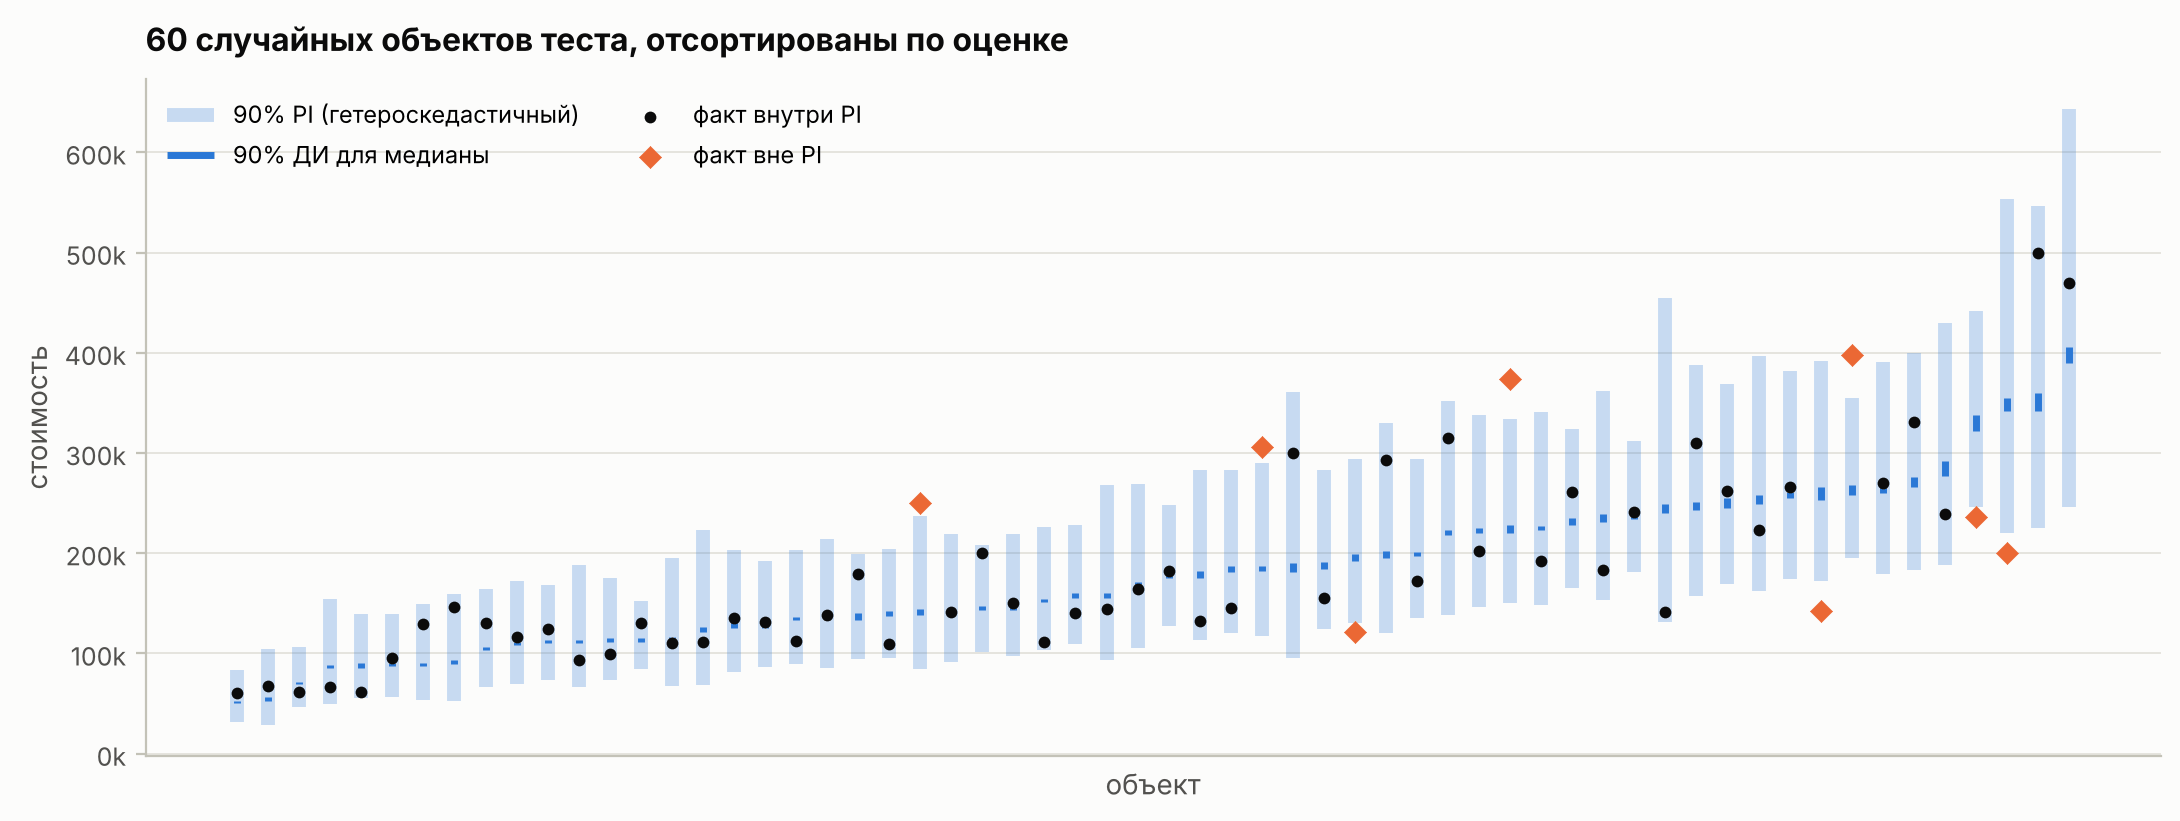

Вне 90% PI: 8 из 60 объектов (13%)


In [49]:
rs = np.random.default_rng(SEED)
pick = np.sort(rs.choice(len(y_test), 60, replace=False))
pick = pick[np.argsort(y_med_t[pick])]
lo_h, hi_h = pis_t["Гетероскедастичный"]
x = np.arange(len(pick))
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.vlines(x, np.exp(lo_h[pick]), np.exp(hi_h[pick]), color=C["blue"], lw=5, alpha=0.25, label="90% PI (гетероскедастичный)")
ax.vlines(x, np.exp(ci_t[0][pick]), np.exp(ci_t[1][pick]), color=C["blue"], lw=2.5, label="90% ДИ для медианы")
inside = (y_test[pick] >= np.exp(lo_h[pick])) & (y_test[pick] <= np.exp(hi_h[pick]))
ax.scatter(x[inside], y_test[pick][inside], color=INK, s=18, zorder=3, label="факт внутри PI")
ax.scatter(x[~inside], y_test[pick][~inside], color=C["orange"], s=34, zorder=3, marker="D", label="факт вне PI")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.set(title="60 случайных объектов теста, отсортированы по оценке", xlabel="объект", ylabel="стоимость")
ax.set_xticks([])
ax.legend(loc="upper left", ncol=2, fontsize=8.5)
plt.show()
print(f"Вне 90% PI: {(~inside).sum()} из {len(pick)} объектов ({100 * (~inside).mean():.0f}%)")

Вне PI 8 из 60 объектов при ожидаемых 6 ± 2,3.

### 10.4. Бэктест нижней границы

Доля объектов ниже консервативной оценки должна быть 5% в каждом сегменте; отклонение проверяется тестом Купика.

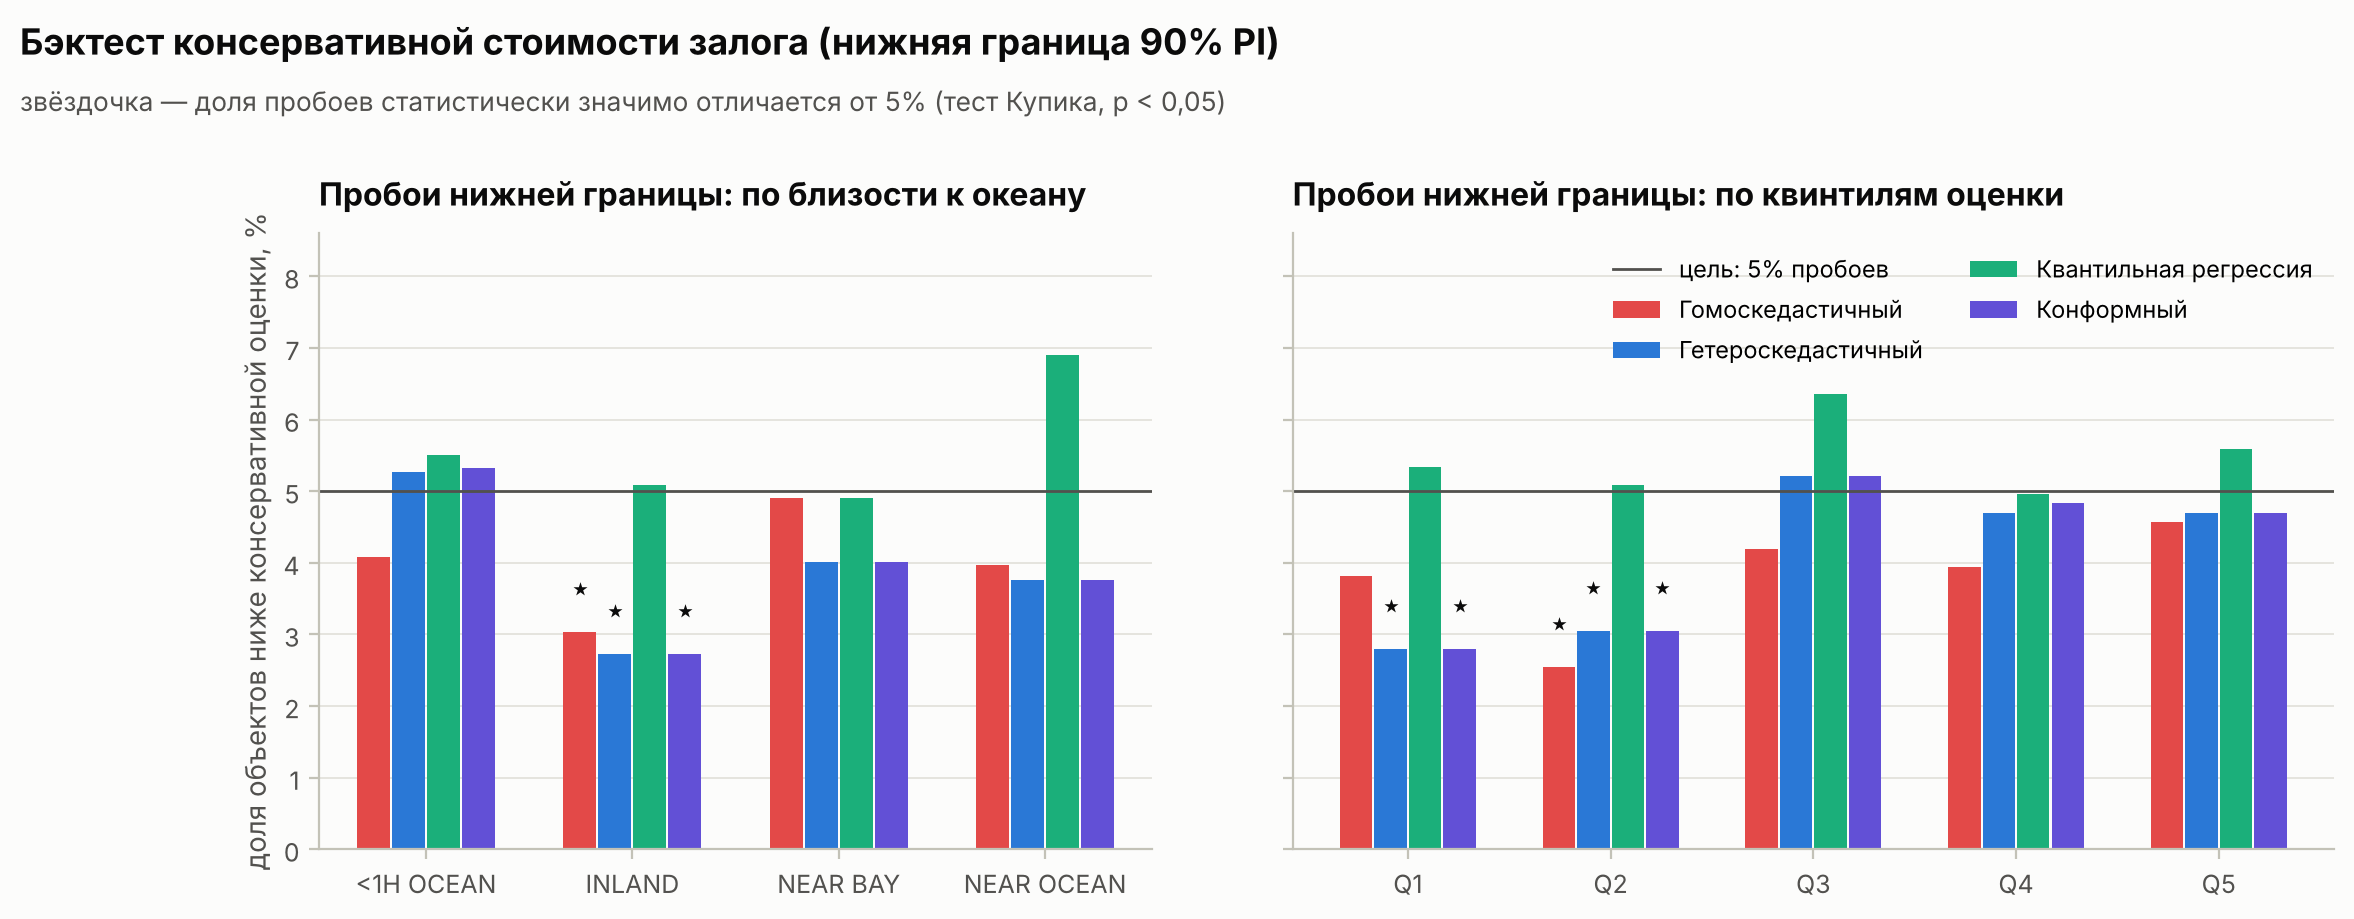

In [50]:
seg_defs = {"ocean": test_df["ocean_proximity"].values,
            "квинтиль оценки": pd.qcut(y_med_t, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]).astype(str)}
rows = []
for seg_name, seg_vals in seg_defs.items():
    for g in sorted(np.unique(seg_vals)):
        mask = seg_vals == g
        for name, (lo, hi) in pis_t.items():
            below = y_test[mask] < np.exp(lo[mask])
            lr, p_k = kupiec_pof(below.sum(), mask.sum(), ALPHA / 2)
            rows.append({"разрез": seg_name, "сегмент": g, "метод": name, "n": mask.sum(),
                         "пробоев, %": 100 * below.mean(), "Купик p": p_k})
backtest = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw={"wspace": 0.15, "width_ratios": [4, 5]}, sharey=True)
for ax, seg_name in zip(axes, seg_defs):
    sub = backtest[backtest["разрез"] == seg_name]
    groups = sub["сегмент"].unique()
    for j, name in enumerate(pis_t):
        s = sub[sub["метод"] == name].set_index("сегмент").loc[groups]
        xs = np.arange(len(groups)) + (j - 1.5) * 0.17
        ax.bar(xs, s["пробоев, %"], width=0.16, color=METHOD_COLORS[name], label=name)
        sig = s["Купик p"] < 0.05
        ax.scatter(xs[sig.values], s["пробоев, %"][sig.values] + 0.6, marker="*", color=INK, s=28, zorder=3)
    ax.axhline(100 * ALPHA / 2, color=INK2, lw=1, label="цель: 5% пробоев")
    ax.set_xticks(range(len(groups)), groups, fontsize=9)
    ax.set(title=f"Пробои нижней границы: по {'близости к океану' if seg_name == 'ocean' else 'квинтилям оценки'}",
           ylabel="доля объектов ниже консервативной оценки, %" if seg_name == "ocean" else None)
    ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 8.6)  # место под легенду (оси общие)
axes[1].legend(loc="upper right", fontsize=8.5, ncol=2)
suptitle(fig, "Бэктест консервативной стоимости залога (нижняя граница 90% PI)",
         "звёздочка — доля пробоев статистически значимо отличается от 5% (тест Купика, p < 0,05)")
plt.show()

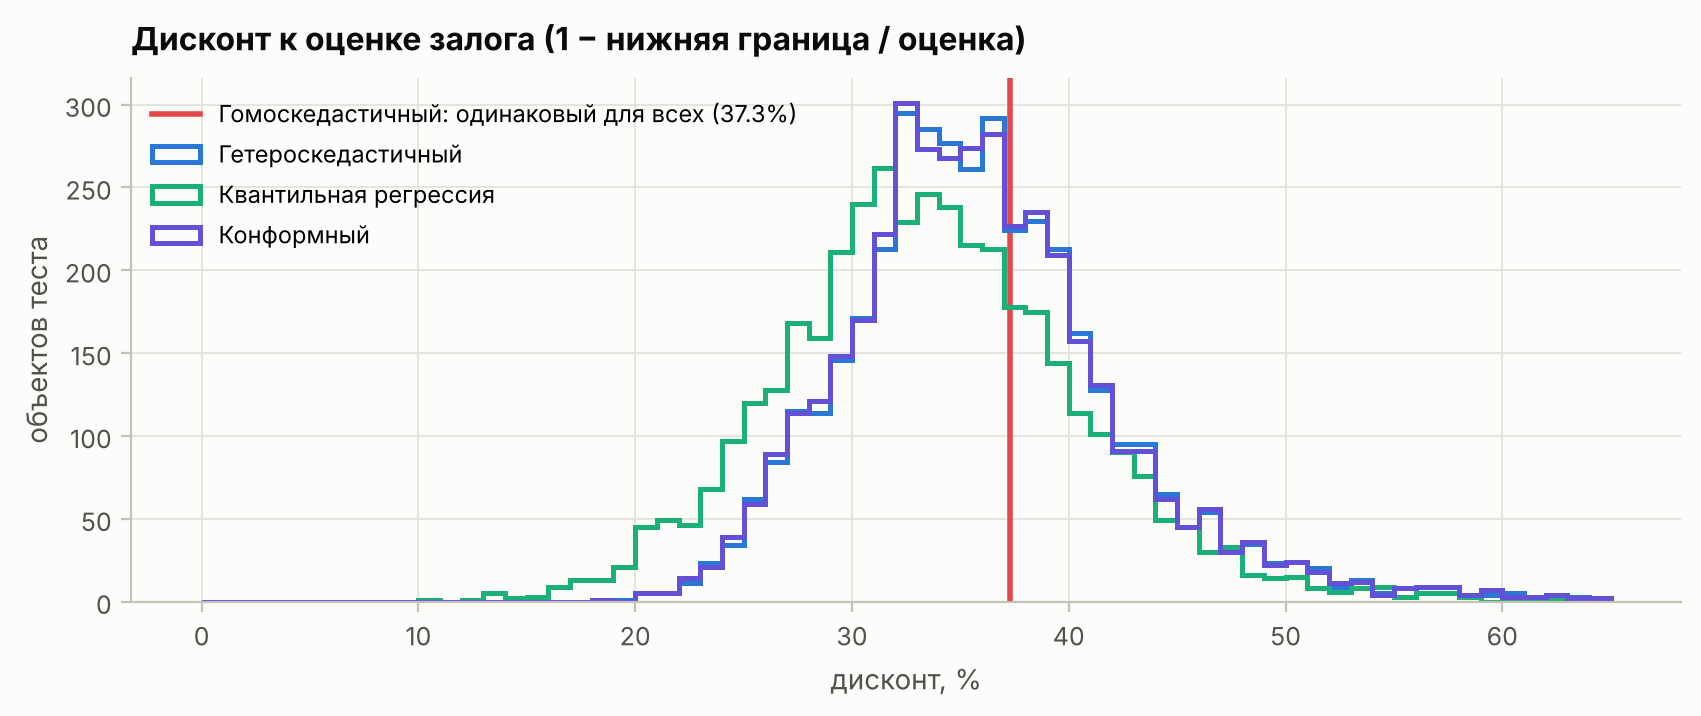

Дисконт при постоянной σ: M2 (σ = 0.283) → 37.3%;  расширенная модель (σ ≈ 0.230) → 31.5%


,"медиана, %","P10, %","P90, %"
Гомоскедастичный,37.2749,37.2642,37.3041
Гетероскедастичный,35.5066,28.4718,43.9999
Квантильная регрессия,33.3235,25.1933,42.3012
Конформный,35.4323,28.4054,43.8840


In [51]:
haircut = {name: 100 * (1 - np.exp(lo) / y_med_t) for name, (lo, hi) in pis_t.items()}
hc_table = pd.DataFrame({name: {"медиана, %": np.median(h), "P10, %": np.percentile(h, 10), "P90, %": np.percentile(h, 90)}
                         for name, h in haircut.items()}).T
fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.linspace(0, 65, 66)
for name, h in haircut.items():
    if np.ptp(h) < 0.5:  # гомоскедастичный метод: дисконт почти одинаковый для всех объектов
        ax.axvline(h[0], color=METHOD_COLORS[name], lw=2, label=f"{name}: одинаковый для всех ({h[0]:.1f}%)")
    else:
        ax.hist(h, bins=bins, histtype="step", lw=1.8, color=METHOD_COLORS[name], label=name)
ax.set(title="Дисконт к оценке залога (1 − нижняя граница / оценка)", xlabel="дисконт, %", ylabel="объектов теста")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()
sigma_best = cv_ols["val"][0]  # CV-оценка σ лог-ошибки лучшей линейной модели (МНК на расширенном пространстве)
print(f"Дисконт при постоянной σ: M2 (σ = {np.sqrt(mean_model.sigma2_):.3f}) → {100 * (1 - np.exp(-Z_CRIT * np.sqrt(mean_model.sigma2_))):.1f}%;  "
      f"расширенная модель (σ ≈ {sigma_best:.3f}) → {100 * (1 - np.exp(-Z_CRIT * sigma_best)):.1f}%")
hc_table

* Гомоскедастичный, гетероскедастичный и конформный методы в INLAND и квинтилях Q1–Q2 дают 2,5–3,8% пробоев, большинство отклонений значимо: дисконт в этих сегментах избыточен.
* У квантильной регрессии значимых отклонений нет; максимум 6,9% в NEAR OCEAN (n = 478).
* Дисконт гомоскедастичного метода 37,3% для всех объектов. У квантильной регрессии 25–42% (P10–P90), медиана 33%.
* При σ лучшей линейной модели (0,230 против 0,283) постоянный дисконт снизился бы до 31,5%.

Для консервативной стоимости залога используется квантильная регрессия.

## 11. Сравнение моделей на тесте

| | Модель |
|---|---|
| M0 | медиана обучающей выборки |
| M1 | МНК, $y$, сырые признаки |
| M2 | МНК, $\log y$, 16 признаков |
| M3 | МНК, $\log y$, 213 признаков |
| M4–M6 | Ridge, Lasso, ElasticNet на тех же 213 признаках, $\alpha_{1SE}$ |
| M7 | HistGradientBoosting, $\log y$ (challenger) |

Для лог-моделей прогноз — $\exp(\cdot)$.

In [52]:
t0 = time.time()
ols_ext_final = LinearRegression().fit(Xe_train, ly_train)
ridge_final = Ridge(alpha=cv_ridge["alpha_1se"]).fit(Xe_train, ly_train)
lasso_final = Lasso(alpha=cv_lasso["alpha_1se"], max_iter=50_000, precompute=True).fit(Xe_train, ly_train)
enet_final = ElasticNet(alpha=cv_en["alpha_1se"], l1_ratio=best_ratio, max_iter=50_000, precompute=True).fit(Xe_train, ly_train)

ocean_codes = {c: i for i, c in enumerate(sorted(train_df["ocean_proximity"].unique()))}
HGB_FEATURES = NUM_FEATURES + ["median_income", "latitude", "longitude"]


def hgb_matrix(df):
    X = df[HGB_FEATURES].copy()
    X["ocean"] = df["ocean_proximity"].map(ocean_codes)
    return X


hgb = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05, categorical_features=[len(HGB_FEATURES)],
                                    random_state=SEED).fit(hgb_matrix(train_df), ly_train)

preds = {
    "M0: медиана": np.full(len(y_test), np.median(y_train)),
    "M1: МНК, сырые": m1.predict(test_df),
    "M2: МНК, лог": np.exp(ols_m2.predict(X2_test)),
    "M3: МНК, расш.": np.exp(ols_ext_final.predict(Xe_test)),
    "M4: Ridge": np.exp(ridge_final.predict(Xe_test)),
    "M5: Lasso": np.exp(lasso_final.predict(Xe_test)),
    "M6: ElasticNet": np.exp(enet_final.predict(Xe_test)),
    "M7: бустинг": np.exp(hgb.predict(hgb_matrix(test_df))),
}
MODELS = [m for m in preds if not m.startswith("M0")]
MODEL_COLORS = dict(zip(MODELS, [C["red"], C["orange"], C["yellow"], C["blue"], C["aqua"], C["violet"], INK2]))
print(f"Обучение финальных моделей: {time.time() - t0:.1f} с;  ненулевых коэффициентов: "
      f"Lasso {np.sum(lasso_final.coef_ != 0)}/{Xe_train.shape[1]}, ElasticNet {np.sum(enet_final.coef_ != 0)}/{Xe_train.shape[1]}")

test_report = report_table(preds, y_test)
(test_report.style
 .format({c: "{:,.0f}" for c in ["RMSE, $", "MAE, $"]} | {c: "{:.2f}" for c in test_report.columns if "%" in c} | {"R2": "{:.3f}"})
 .background_gradient(subset=["MAPE, %"], cmap=CMAP_SEQ.reversed()))

Обучение финальных моделей: 1.8 с;  ненулевых коэффициентов: Lasso 153/213, ElasticNet 175/213


,"MAPE, %","MdAPE, %","PE10, %","PE20, %","OVR20, %","RMSE, $","MAE, $",R2
M0: медиана,51.58,35.87,15.58,28.46,36.93,"101,051","78,105",-0.036
"M1: МНК, сырые",27.85,20.29,26.00,49.30,31.89,"61,455","45,088",0.617
"M2: МНК, лог",22.07,16.27,33.01,59.01,22.87,"57,606","39,368",0.663
"M3: МНК, расш.",17.58,12.54,41.32,70.32,16.57,"48,038","31,680",0.766
M4: Ridge,17.69,12.58,40.76,69.81,16.87,"48,105","31,864",0.765
M5: Lasso,18.24,13.08,39.77,68.18,17.71,"49,748","33,089",0.749
M6: ElasticNet,18.17,13.15,39.77,68.36,17.71,"49,441","32,887",0.752
M7: бустинг,14.64,10.10,49.56,77.61,12.53,"41,100","26,284",0.829


### 11.1. Бутстреп метрик

Парный бутстреп, 2 000 выборок с общими индексами для всех моделей.

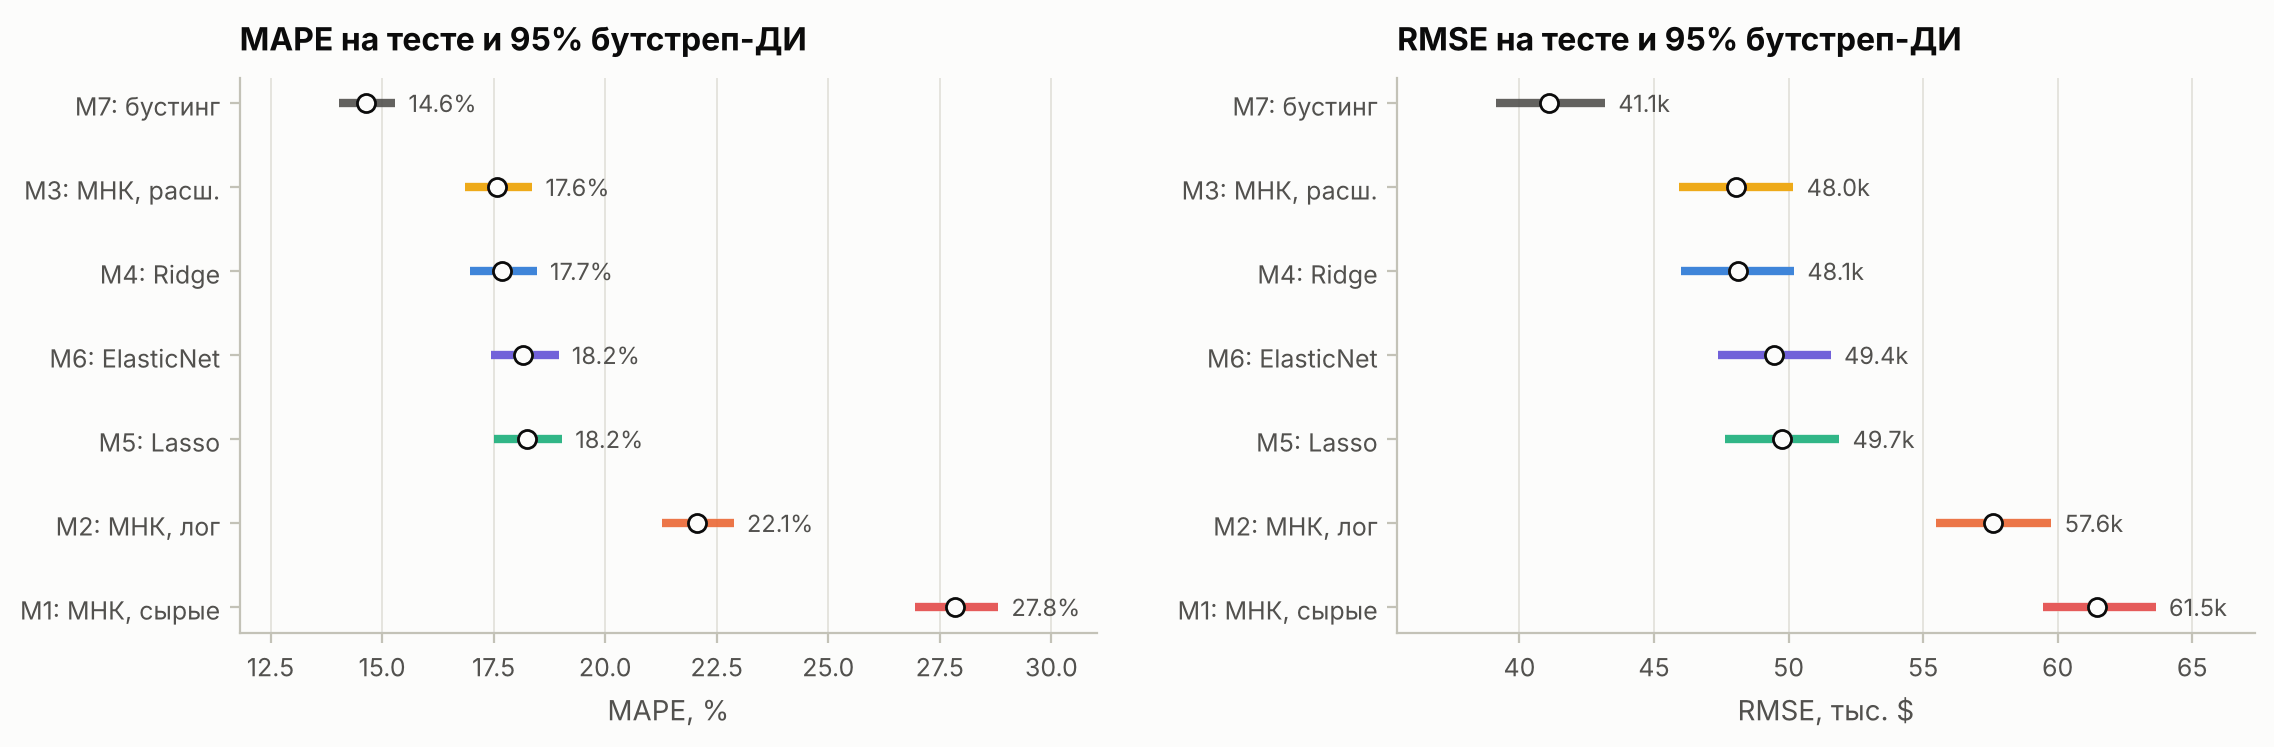

In [53]:
n_test = len(y_test)
B = 2000
boot_idx = np.random.default_rng(SEED).integers(0, n_test, size=(B, n_test), dtype=np.int32)
APE = {m: np.abs(p - y_test) / y_test for m, p in preds.items()}
SQE = {m: (p - y_test) ** 2 for m, p in preds.items()}
boot = {m: {"MAPE": 100 * APE[m][boot_idx].mean(1), "RMSE": np.sqrt(SQE[m][boot_idx].mean(1))} for m in MODELS}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"wspace": 0.35})
order = sorted(MODELS, key=lambda m: APE[m].mean(), reverse=True)
for ax, metric, scale, fmt in [(axes[0], "MAPE", 1, "{:.1f}%"), (axes[1], "RMSE", 1e3, "{:.1f}k")]:
    for i, m in enumerate(order):
        lo, hi = np.percentile(boot[m][metric], [2.5, 97.5]) / scale
        point = (100 * APE[m].mean() if metric == "MAPE" else np.sqrt(SQE[m].mean())) / scale
        ax.hlines(i, lo, hi, color=MODEL_COLORS[m], lw=3, alpha=0.9)
        ax.plot(point, i, "o", color=SURFACE, markeredgecolor=INK, ms=6.5, zorder=3)
        ax.text(hi, i, "  " + fmt.format(point), va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(range(len(order)), order)
    ax.set(title=f"{metric} на тесте и 95% бутстреп-ДИ", xlabel=metric + (", %" if metric == "MAPE" else ", тыс. $"))
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.15)
plt.show()

MAPE на тесте выше CV-оценок на 0,1–0,7 п. п. (M1–M6). Полуширина 95%-ного ДИ MAPE 0,6–0,9 п. п.; интервалы M3–M6 перекрываются. Для сравнения моделей нужна дисперсия разности, а не отдельных метрик (11.3).

### 11.2. Устойчивость ранжирования

30 случайных половин теста, ранги по MAPE.

Различных порядков моделей в 30 итерациях: 2; самый частый встречается 29 раз из 30


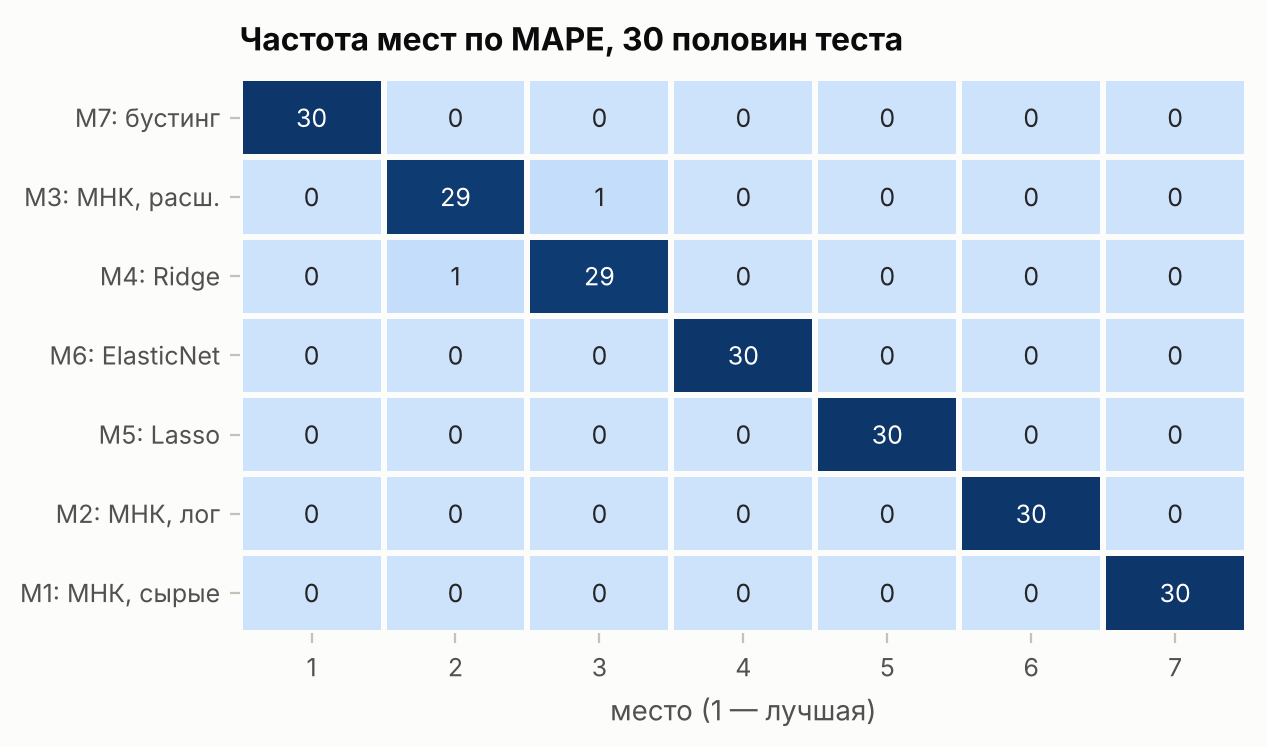

In [54]:
rs = np.random.default_rng(SEED)
rank_rows, orders = [], []
for it in range(30):
    half = rs.permutation(n_test)[: n_test // 2]
    mape_half = pd.Series({m: APE[m][half].mean() for m in MODELS})
    ranks = mape_half.rank().astype(int)
    rank_rows.append(ranks)
    orders.append(tuple(mape_half.sort_values().index))
rank_df = pd.DataFrame(rank_rows).reset_index(drop=True)
rank_freq = rank_df.apply(lambda col: col.value_counts()).fillna(0).astype(int).T.reindex(columns=range(1, len(MODELS) + 1), fill_value=0)
rank_freq = rank_freq.loc[sorted(MODELS, key=lambda m: rank_df[m].mean())]
print(f"Различных порядков моделей в 30 итерациях: {len(set(orders))}; "
      f"самый частый встречается {pd.Series(orders).value_counts().iloc[0]} раз из 30")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(rank_freq, annot=True, fmt="d", cmap=CMAP_SEQ, cbar=False, ax=ax, linewidths=2, linecolor=SURFACE,
            annot_kws={"fontsize": 9})
ax.grid(False)
ax.set(title="Частота мест по MAPE, 30 половин теста", xlabel="место (1 — лучшая)", ylabel="")
plt.show()

Порядок одинаков в 29 итерациях из 30, единственная перестановка — M3 и M4.

### 11.3. Парный тест через регрессию

$H_0:\mathsf E[\ell_A-\ell_B]=0$, где $\ell$ — APE (основная метрика) или квадрат ошибки. Регрессия $d_i=\ell_A(i)-\ell_B(i)=\theta+\varepsilon_i$ с HC1 эквивалентна парному t-тесту. В сложенной форме $\ell_{im}=\beta_0+\beta_1\mathbb 1\{m=B\}+u_{im}$ ошибки одного объекта коррелированы, нужны кластерные SE по объекту: $\operatorname{Var}(\ell_A-\ell_B)=\operatorname{Var}\ell_A+\operatorname{Var}\ell_B-2\operatorname{Cov}(\ell_A,\ell_B)$.

In [55]:
def paired_test(loss_a, loss_b, groups=None):
    """Регрессия разности потерь на константу. groups → кластерные SE (иначе HC1 = парный t-тест)."""
    d = loss_a - loss_b
    m = OLS(cov_type="cluster" if groups is not None else "HC1").fit(np.empty((len(d), 0)), d, groups=groups)
    s = m.summary().iloc[0]
    return {"diff": s.coef, "se": s.std_err, "ci_low": s.ci_low, "ci_high": s.ci_high, "t": s.t, "p": s.p_value}


a, b = "M4: Ridge", "M5: Lasso"
res_paired = paired_test(100 * APE[a], 100 * APE[b])
stacked_y = np.r_[100 * APE[a], 100 * APE[b]]
stacked_X = np.r_[np.zeros(n_test), np.ones(n_test)][:, None]
obj_id = np.r_[np.arange(n_test), np.arange(n_test)]
st_naive = OLS(cov_type="nonrobust").fit(stacked_X, stacked_y).summary().iloc[1]
st_clust = OLS(cov_type="cluster").fit(stacked_X, stacked_y, groups=obj_id).summary().iloc[1]
tt = stats.ttest_rel(100 * APE[a], 100 * APE[b])
pd.DataFrame({
    "Δ MAPE (A − B), п. п.": [res_paired["diff"], -st_naive.coef, -st_clust.coef, tt.statistic * res_paired["se"]],
    "SE": [res_paired["se"], st_naive.std_err, st_clust.std_err, np.nan],
    "t": [res_paired["t"], -st_naive.t, -st_clust.t, tt.statistic],
    "p-value": [res_paired["p"], st_naive.p_value, st_clust.p_value, tt.pvalue],
}, index=["регрессия d на константу (HC1)", "сложенная регрессия, обычные SE", "сложенная регрессия, кластеры по объекту",
          "scipy.stats.ttest_rel (контроль)"])

,"Δ MAPE (A − B), п. п.",SE,t,p-value
регрессия d на константу (HC1),-0.5516,0.0870,-6.3413,0.0000
"сложенная регрессия, обычные SE",-0.5516,0.5611,-0.9830,0.3256
"сложенная регрессия, кластеры по объекту",-0.5516,0.0870,-6.3409,0.0000
scipy.stats.ttest_rel (контроль),-0.5516,NaN,-6.3413,0.0000


HC1 на константе совпадает с `ttest_rel` (t = −6,34). Без учёта парности SE больше в 6,5 раза (0,561 против 0,087), и p = 0,33 вместо ~10⁻¹⁰.

### 11.4. Множественные сравнения

При $K$ тестах уровня $\alpha$ и верных $H_0$: $\alpha\le\mathrm{FWER}\le\min(1,K\alpha)$. Нижняя граница достигается при полностью зависимых тестах, верхняя — при непересекающихся областях отвержения; при независимости $\mathrm{FWER}=1-(1-\alpha)^K$. Для $K=3$ это [5%; 15%], для $K=21$ — [5%; 100%], при независимости 66%. Бонферрони ($\alpha/K$) и Холм (step-down) дают $\mathrm{FWER}\le\alpha$ при любой зависимости, Холм мощнее. Дополнительно — кластерные SE по географическим ячейкам.

In [56]:
def holm(pvals):
    """Скорректированные по Холму p-значения (step-down, контроль FWER)."""
    p = np.asarray(pvals)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


cells_test = spatial_cells(test_df)
pairs = [(MODELS[i], MODELS[j]) for i in range(len(MODELS)) for j in range(i + 1, len(MODELS))]
K = len(pairs)
rows = []
for metric, losses, scale in [("MAPE", APE, 100), ("MSE", SQE, 1e-6)]:
    for a, b in pairs:
        r = paired_test(scale * losses[a], scale * losses[b])
        rc = paired_test(scale * losses[a], scale * losses[b], groups=cells_test)
        rows.append({"метрика": metric, "A": a, "B": b, "Δ (A − B)": r["diff"], "95% ДИ от": r["ci_low"], "до": r["ci_high"],
                     "p": r["p"], "p (кластеры)": rc["p"]})
tests = pd.DataFrame(rows)
for metric in ("MAPE", "MSE"):
    mask = tests["метрика"] == metric
    tests.loc[mask, "p Бонферрони"] = np.minimum(1, tests.loc[mask, "p"] * K)
    tests.loc[mask, "p Холм"] = holm(tests.loc[mask, "p"])
    tests.loc[mask, "p Холм (кластеры)"] = holm(tests.loc[mask, "p (кластеры)"])
summary_tests = pd.DataFrame({
    metric: {"значимо при α = 5% без поправки": int((t["p"] < 0.05).sum()),
             "после Бонферрони": int((t["p Бонферрони"] < 0.05).sum()),
             "после Холма": int((t["p Холм"] < 0.05).sum()),
             "Холм + кластерные SE": int((t["p Холм (кластеры)"] < 0.05).sum())}
    for metric, t in tests.groupby("метрика")}).T
display(summary_tests)
close = ["M3: МНК, расш.", "M4: Ridge", "M5: Lasso", "M6: ElasticNet"]
(tests[(tests["метрика"] == "MAPE") & tests["A"].isin(close) & tests["B"].isin(close)]
 .drop(columns="метрика").style.format(
    {"Δ (A − B)": "{:+.2f}", "95% ДИ от": "{:+.2f}", "до": "{:+.2f}", "p": "{:.1e}", "p (кластеры)": "{:.1e}",
     "p Бонферрони": "{:.3f}", "p Холм": "{:.3f}", "p Холм (кластеры)": "{:.3f}"}).hide(axis="index"))

,значимо при α = 5% без поправки,после Бонферрони,после Холма,Холм + кластерные SE
MAPE,20,19,20,19
MSE,20,20,20,16


A,B,Δ (A − B),95% ДИ от,до,p,p (кластеры),p Бонферрони,p Холм,p Холм (кластеры)
"M3: МНК, расш.",M4: Ridge,-0.11,-0.23,+0.02,8.6e-02,4.0e-01,1.000,0.086,0.396
"M3: МНК, расш.",M5: Lasso,-0.66,-0.87,-0.45,4.9e-10,9.4e-03,0.000,0.000,0.037
"M3: МНК, расш.",M6: ElasticNet,-0.58,-0.78,-0.39,4.7e-09,1.2e-02,0.000,0.000,0.037
M4: Ridge,M5: Lasso,-0.55,-0.72,-0.38,2.5e-10,1.8e-03,0.000,0.000,0.009
M4: Ridge,M6: ElasticNet,-0.48,-0.62,-0.33,3.6e-10,1.2e-03,0.000,0.000,0.007
M5: Lasso,M6: ElasticNet,+0.08,+0.03,+0.13,2.9e-03,8.5e-02,0.061,0.006,0.170


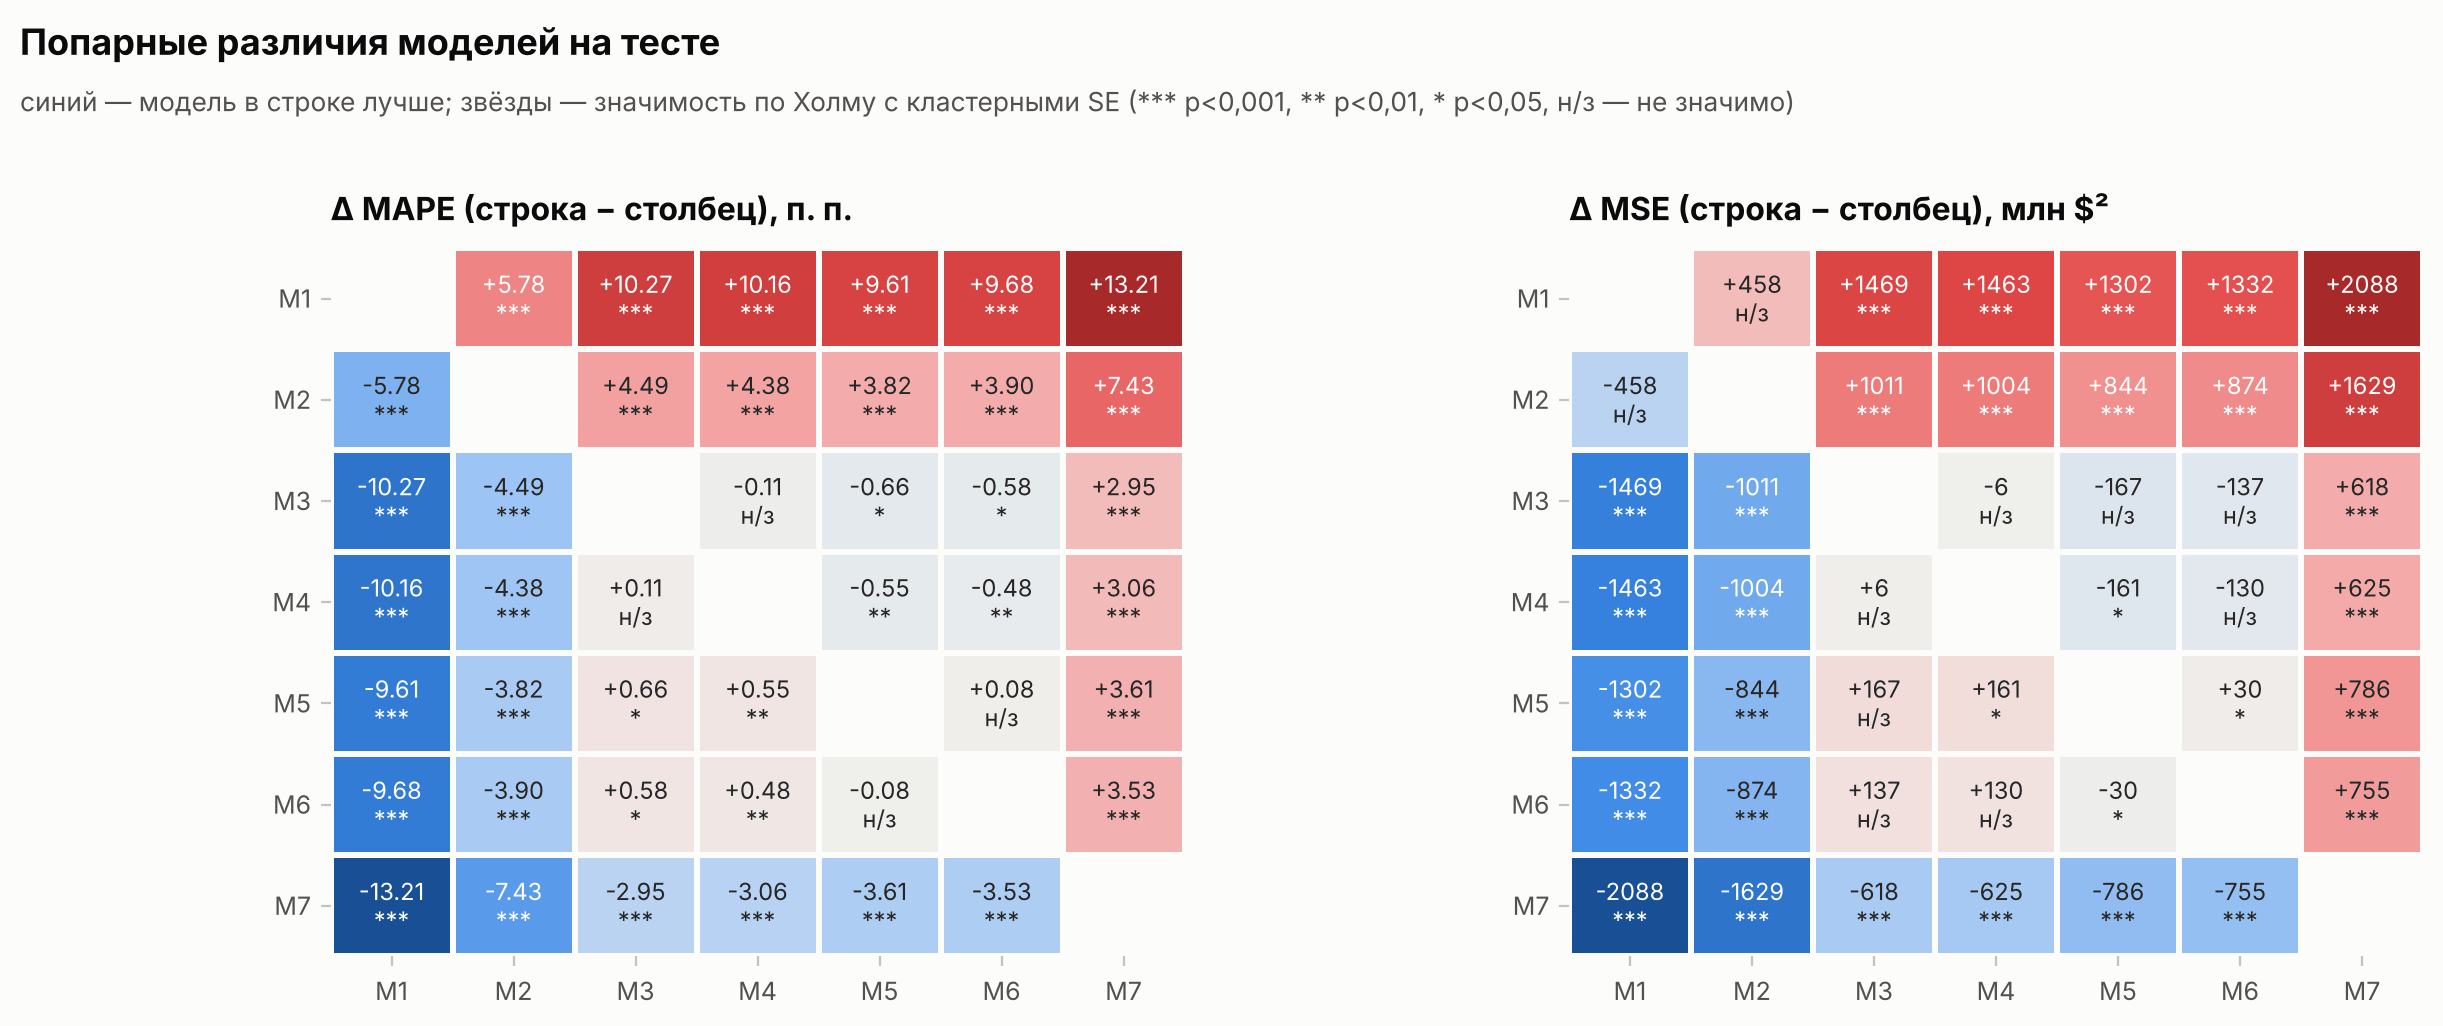

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"wspace": 0.45})
short = {m: m.split(":")[0] for m in MODELS}
for ax, metric, unit in [(axes[0], "MAPE", "п. п."), (axes[1], "MSE", "млн $²")]:
    sub = tests[tests["метрика"] == metric]
    M = pd.DataFrame(np.nan, index=MODELS, columns=MODELS)
    P = M.copy()
    for _, r in sub.iterrows():
        M.loc[r["A"], r["B"]], M.loc[r["B"], r["A"]] = r["Δ (A − B)"], -r["Δ (A − B)"]
        P.loc[r["A"], r["B"]] = P.loc[r["B"], r["A"]] = r["p Холм (кластеры)"]
    vmax = np.nanmax(np.abs(M.values))
    labels = M.apply(lambda col: col.map(lambda v: "" if np.isnan(v) else f"{v:+.2f}" if metric == "MAPE" else f"{v:+.0f}"))
    labels = labels + P.apply(lambda col: col.map(lambda p: "" if np.isnan(p) else ("\n***" if p < 0.001 else "\n**" if p < 0.01 else "\n*" if p < 0.05 else "\nн/з")))
    sns.heatmap(M, ax=ax, cmap=CMAP_DIV, vmin=-vmax, vmax=vmax, annot=labels.values, fmt="", cbar=False,
                linewidths=2, linecolor=SURFACE, annot_kws={"fontsize": 8.5})
    ax.set_xticklabels([short[m] for m in MODELS], rotation=0)
    ax.set_yticklabels([short[m] for m in MODELS], rotation=0)
    ax.set(title=f"Δ {metric} (строка − столбец), {unit}", xlabel="", ylabel="")
    ax.grid(False)
suptitle(fig, "Попарные различия моделей на тесте",
         "синий — модель в строке лучше; звёзды — значимость по Холму с кластерными SE (*** p<0,001, ** p<0,01, * p<0,05, н/з — не значимо)")
plt.show()

* MAPE: с поправкой Холма значимы 20 различий из 21. Бонферрони не находит различия Lasso и ElasticNet (p = 0,061 против 0,006 у Холма).
* M3 и M4 не различаются: p = 0,086 без поправки.
* С кластерными SE незначимо различие Lasso и ElasticNet (p = 0,17); M3 лучше Lasso и ElasticNet при p = 0,037.
* MSE с кластерными SE: 5 незначимых пар, в том числе M1–M2. Преимущество M2 над M1 значимо по MAPE, но не по квадратичной ошибке в долларах.

### 11.5. Выбор модели

* Champion — M4 (Ridge): по MAPE не отличается от M3 (p = 0,09; с кластерными SE 0,40), коэффициенты устойчивы, κ меньше почти на три порядка. MAPE 17,7%, PE20 69,8%, OVR20 16,9%.
* M2 — объясняющая модель для валидации и мониторинга драйверов; MAPE на 4,4 п. п. хуже.
* Challenger M7 точнее на 3,1 п. п. MAPE (p < 0,001). Это цена интерпретируемости; переход на бустинг определяется требованиями валидации к объяснимости.

## 12. Ограничения и развитие

* Наблюдение — квартал 1990 г., а не объект: переносится методология, значения метрик — нет.
* Объекты дороже 500 тыс. долл. вне области применимости; для полного диапазона нужна тобит-регрессия.
* Случайный сплит не проверяет перенос на новые территории; нужна пространственная CV (`GroupKFold` по ячейкам). Кластерные SE не учитывают корреляцию между соседними ячейками.
* Конформная гарантия маргинальная; условное покрытие проверено только по выбранным сегментам. Модель дисперсии линейна.
* Коэффициенты описывают ассоциации, а не причинные эффекты.

Развитие: тобит или Gamma-GLM с лог-связью; пространственная CV; CQR (квантильная регрессия с конформной калибровкой); мониторинг PSI и регулярный бэктест нижней границы.